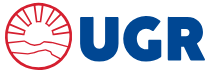

**Trabajo Final** - Ariel Fernandez  : *Clasificación del riesgo de derivación a Gestión Judicial en una cartera de préstamos personales mediante aprendizaje automático supervisado*


# Análisis Exploratorio de Datos (EDA)

**Dataset:** `dataset2326v2.xlsx`  
**Período disponible:** 2023–2026  
**Ventana principal del EDA:** 2024–2026  
**Población con desenlace conocido:** 2024–2025  
**Aplicación temporal:** operaciones activas observadas hasta el 01/09/2026  


## Objetivo

Analizar las características de los préstamos y de los clientes asociadas con la derivación a Gestión Judicial, con especial atención a la disponibilidad de información al momento del otorgamiento, la composición de la cartera, las diferencias entre segmentos y el contraste entre operaciones de Apertura y Renovación.


## Índice Metodologico

0. Configuración y carga de datos  
1. Revisión inicial del dataset  
2. Descripción general de la base 2023–2026  
3. Disponibilidad de sueldo y definición de la ventana de análisis  
4. Descripción de la ventana principal 2024–2026  
5. Estados observados y construcción del resultado Judicial / No Judicial  
6. Clasificación de variables  
7. Construcción de la relación cuota-ingreso  
8. Estadísticos descriptivos por tipo de crédito  
9. Distribución de variables numéricas  
10. Análisis del score crediticio  
11. Apertura versus Renovación  
12. Segmentación de la judicialización  
13. Relación cuota-ingreso y judicialización  
14. Matriz de correlaciones de variables candidatas  
15. Resumen de hallazgos por segmento  
16. Variables disponibles al momento de evaluar el crédito  
17. Poblaciones de Apertura y Renovación para el modelado  
18. Cierre del EDA


# 0. Configuración y carga de datos

En este bloque se importan las librerías necesarias y se carga el dataset principal.

La base contiene operaciones crediticias del período 2023–2026 y constituye el punto de partida para definir la ventana temporal, construir el resultado de interés y desarrollar el análisis exploratorio.


In [ ]:
# ============================================================
# 0. CONFIGURACIÓN DEL ENTORNO Y CARGA DE DATOS
# ============================================================

!pip -q install openpyxl

from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display


# ------------------------------------------------------------
# Configuración de visualización
# ------------------------------------------------------------

pd.set_option("display.max_columns", 150)
pd.set_option("display.max_rows", 250)


# ------------------------------------------------------------
# Conexión con Google Drive
# ------------------------------------------------------------

try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception:
    pass


# ------------------------------------------------------------
# Rutas
# ------------------------------------------------------------

CARPETA = Path(
    "/content/drive/MyDrive/PROYECTO TESIS/SEMINARIO"
)

RUTA_BASE = (
    CARPETA / "dataset2326v2.xlsx"
)



# ------------------------------------------------------------
# Carga del dataset
# ------------------------------------------------------------

df = pd.read_excel(RUTA_BASE)

# Limpieza de posibles espacios en los nombres de columnas
df.columns = [
    str(columna).strip()
    for columna in df.columns
]


# ------------------------------------------------------------
# Control inicial de carga
# ------------------------------------------------------------

print(
    "Base cargada:",
    df.shape
)

print(
    "Cantidad de columnas:",
    len(df.columns)
)

Mounted at /content/drive
Base cargada: (48668, 40)
Cantidad de columnas: 40


# 1. Revisión inicial de la estructura del dataset

Una vez cargada la base, se realiza una primera revisión de su estructura para verificar la cantidad de registros y variables, los tipos de datos y la presencia de valores nulos técnicos.

Esta revisión permite conocer cómo se encuentra conformado el dataset antes de comenzar con el análisis exploratorio.

In [ ]:
# ============================================================
# 1. REVISIÓN INICIAL DE LA ESTRUCTURA DEL DATASET
# ============================================================

# Primeras filas de la base
display(df.head())

print(f"Cantidad de operaciones: {len(df):,}".replace(",", "."))
print(f"Cantidad de variables: {df.shape[1]}")

print("\nEstructura del dataset:")
df.info()

,target,sucursal,provincia,id_cliente,factura,añofac,mesfac,tipocredito,rangoedad,genero,capitalprestado,plan,interes,totalfac,saldofactura,monto_cuota,SUELDO,rscore,actividad,motivocompra,antiguedad_credito,saldo_relativo,costo_credito,cuotas_pendientes,cuotas_pagas,ratio_cumplimiento,%cobrado,CANT. MESES MORA >30,CANT. MESES MORA >60,CANT. MESES MORA >90,CANT. MESES MORA >120,CANT. MESES MORA >150,MAX DIA MORA,cantidad_prestamos_anteriores,tuvo_mora_anterior,max_mora_prestamos_anteriores,prestamos_cancelados_normal,prestamos_en_judicial_anteriores,renovacion_sin_historial_observable,FECHA JUDICIAL
0,2,711,TUCUMAN,28,6013000031803,2023,4,RENOVACION,60-69,1,150000,18,249750.0,407386.36,207005.14,22632.575556,NaN,700-799,Publico,Compras Hogar,36.000000,1.380034,1.665000,9,9,0.500000,0.491870,6,6,4,3,2,192,2,0,0,0,0,1,2024-09-01
1,2,711,TUCUMAN,28,6013000037069,2023,9,RENOVACION,60-69,1,126500,12,280830.0,413520.83,248598.65,34460.069167,NaN,300-399,Publico,Compras Hogar,30.966667,1.965207,2.220000,8,4,0.333333,0.398824,6,6,4,3,2,195,1,1,192,0,1,1,2024-09-01
2,2,711,TUCUMAN,113,6013000033351,2023,6,APERTURA,60-69,0,250000,18,494999.5,758522.21,686010.21,42140.122778,NaN,450-499,Publico,Compras Hogar,34.366667,2.744041,1.979998,16,2,0.111111,0.095596,7,6,5,4,3,234,0,0,0,0,0,0,2024-05-01
3,2,711,TUCUMAN,138,6013000034615,2023,7,APERTURA,50-59,1,150000,9,195750.0,351136.36,159004.61,39015.151111,NaN,300-399,Publico,Eventos,33.266667,1.060031,1.305000,4,5,0.555556,0.547171,7,6,6,4,3,235,0,0,0,0,0,0,2024-09-01
4,2,711,TUCUMAN,151,6013000035304,2023,7,APERTURA,50-59,0,250000,18,652500.0,930861.63,930861.63,51714.535000,NaN,400-449,Publico,Construccion Remodelacion,32.700000,3.723447,2.610000,18,0,0.000000,0.000000,8,7,6,5,4,246,0,0,0,0,0,0,2024-05-01


Cantidad de operaciones: 48.668
Cantidad de variables: 40

Estructura del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48668 entries, 0 to 48667
Data columns (total 40 columns):
 #   Column                               Non-Null Count  Dtype         
---  ------                               --------------  -----         
 0   target                               48668 non-null  int64         
 1   sucursal                             48668 non-null  int64         
 2   provincia                            48668 non-null  object        
 3   id_cliente                           48668 non-null  int64         
 4   factura                              48668 non-null  int64         
 5   añofac                               48668 non-null  int64         
 6   mesfac                               48668 non-null  int64         
 7   tipocredito                          48668 non-null  object        
 8   rangoedad                            48668 non-null  object        
 9   

In [ ]:
# ============================================================
# CONTROL DE VALORES NULOS TÉCNICOS
# ============================================================

tabla_nulos = pd.DataFrame({
    "Variable": ["SUELDO", "FECHA JUDICIAL"],
    "Nulos técnicos": [
        df["SUELDO"].isna().sum(),
        df["FECHA JUDICIAL"].isna().sum()
    ],
    "% sobre el total": [
        df["SUELDO"].isna().mean() * 100,
        df["FECHA JUDICIAL"].isna().mean() * 100
    ]
})

tabla_nulos["% sobre el total"] = (
    tabla_nulos["% sobre el total"]
    .round(2)
    .astype(str)
    + " %"
)

display(tabla_nulos)

,Variable,Nulos técnicos,% sobre el total
0,SUELDO,15698,32.26 %
1,FECHA JUDICIAL,36150,74.28 %


### Valores nulos técnicos

Los valores nulos se concentran únicamente en las variables `SUELDO` y `FECHA JUDICIAL`, pero tienen distinto significado.

En `SUELDO`, la ausencia de información se encuentra asociada principalmente a las operaciones del año 2023, situación que será analizada mas adelante.

En `FECHA JUDICIAL`, una celda vacía no representa necesariamente información faltante, ya que esta variable solo corresponde a las operaciones que fueron derivadas a Gestión Judicial.(Es un vacio)

# 2. Descripción general del dataset 2023–2026

Antes de definir la ventana principal de análisis, se realiza una descripción general del dataset completo correspondiente al período **2023–2026**.

En esta etapa se observa el volumen de operaciones y clientes, la distribución de los préstamos según su estado y la composición de la cartera entre operaciones de **Apertura** y **Renovación**. Esto permite tener una primera visión del universo histórico disponible antes de realizar los recortes y análisis posteriores.

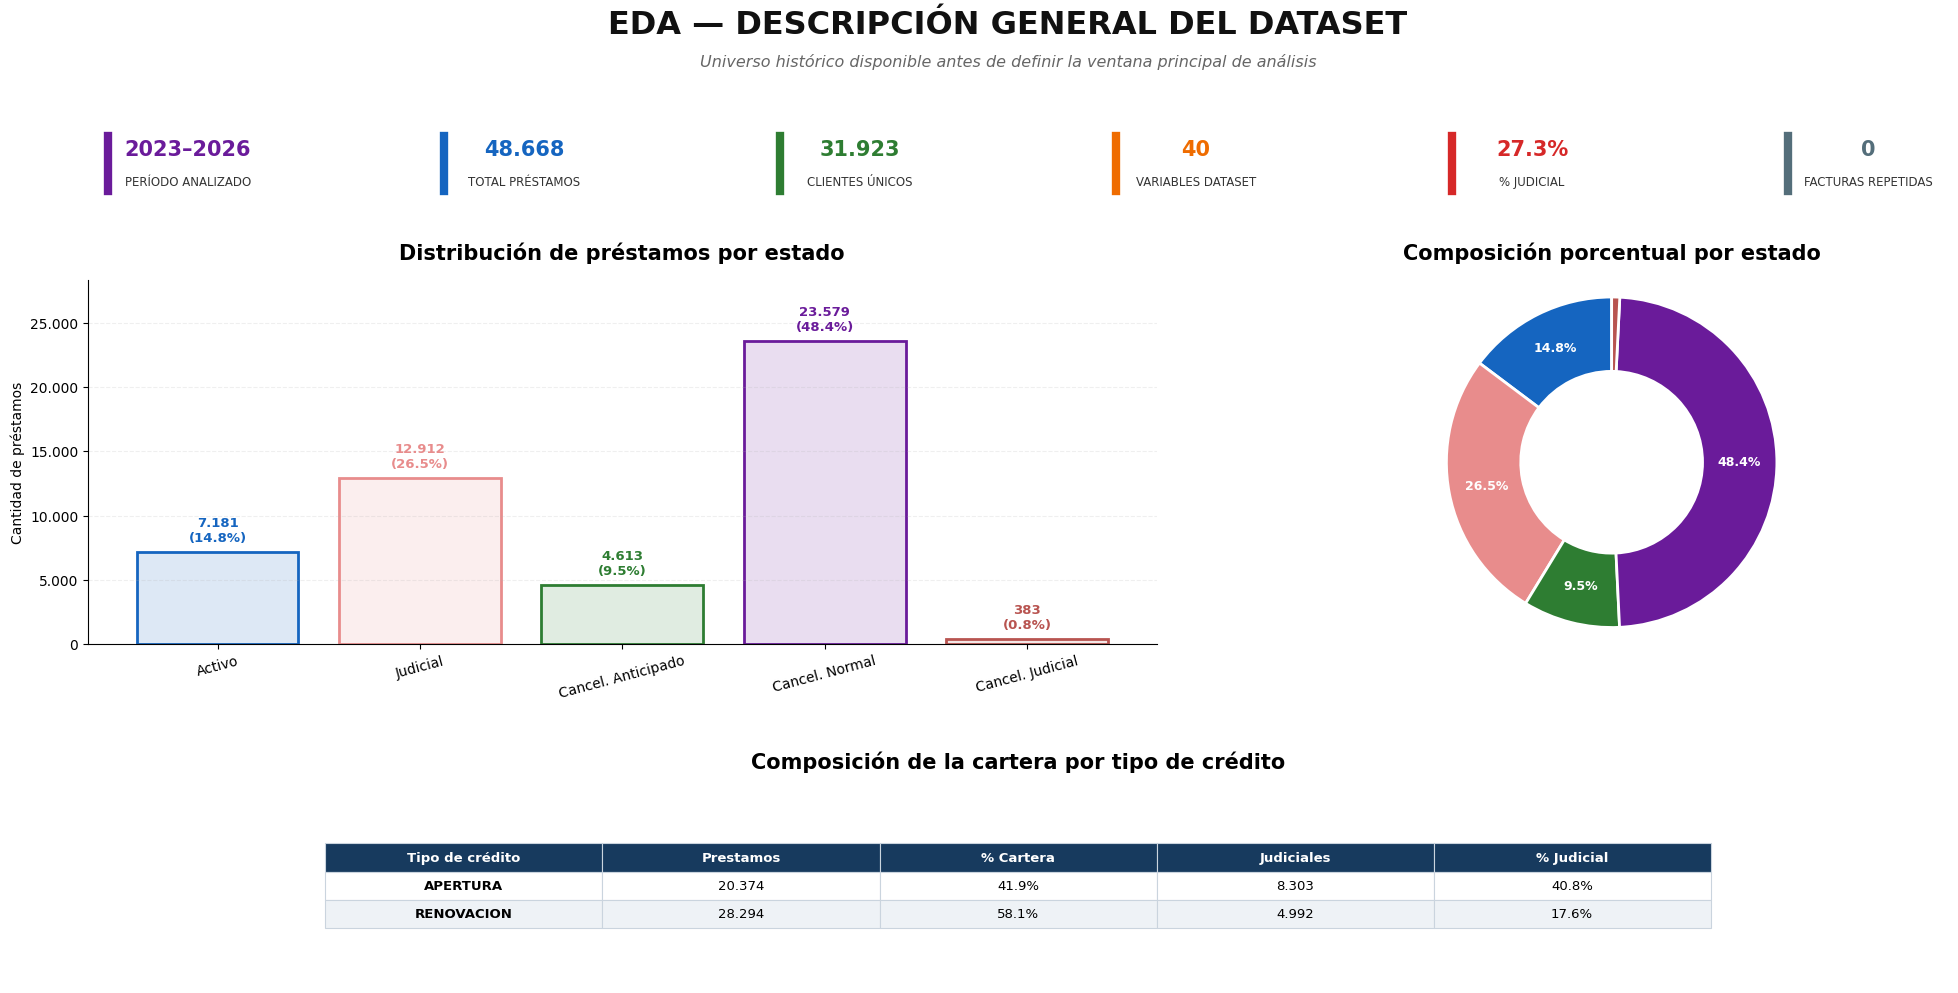

In [ ]:
# ============================================================
# 2. DESCRIPCIÓN GENERAL DEL DATASET 2023–2026
# ============================================================

from matplotlib.ticker import FuncFormatter


# ------------------------------------------------------------
# 1. CONFIGURACIÓN
# ------------------------------------------------------------

TARGETS_JUDICIALES = [2, 5]

NOMBRES_TARGET = {
    1: "Activo",
    2: "Judicial",
    3: "Cancel. Anticipado",
    4: "Cancel. Normal",
    5: "Cancel. Judicial"
}

COLORES_TARGET = {
    1: "#1565C0",
    2: "#E88C8C",
    3: "#2E7D32",
    4: "#6A1B9A",
    5: "#B85450"
}


def formato_entero(valor):
    return f"{valor:,.0f}".replace(",", ".")


def formato_pesos(valor):
    return "$ " + f"{valor:,.0f}".replace(",", ".")


def formato_porcentaje(valor):
    return f"{valor:.1f}%"


# ------------------------------------------------------------
# 2. INDICADORES GENERALES
# ------------------------------------------------------------

total_prestamos = len(df)

clientes_unicos = df["id_cliente"].nunique()

cantidad_variables = df.shape[1]

cantidad_judiciales = (
    df["target"]
    .isin(TARGETS_JUDICIALES)
    .sum()
)

porcentaje_judicial = (
    cantidad_judiciales
    / total_prestamos
    * 100
)

facturas_repetidas = (
    df["factura"]
    .dropna()
    .duplicated(keep=False)
    .sum()
)


# ------------------------------------------------------------
# 3. DISTRIBUCIÓN POR ESTADO
# ------------------------------------------------------------

orden_targets = [1, 2, 3, 4, 5]

distribucion = (
    df["target"]
    .value_counts()
    .reindex(
        orden_targets,
        fill_value=0
    )
)

porcentajes = (
    distribucion
    / total_prestamos
    * 100
)

nombres = [
    NOMBRES_TARGET[x]
    for x in orden_targets
]

colores = [
    COLORES_TARGET[x]
    for x in orden_targets
]


# ------------------------------------------------------------
# 4. APERTURA VS RENOVACIÓN
# ------------------------------------------------------------

tabla_tipo = (
    df
    .groupby(
        "tipocredito",
        observed=False
    )
    .agg(
        Prestamos=("factura", "count"),
        Judiciales=(
            "target",
            lambda x: x.isin(
                TARGETS_JUDICIALES
            ).sum()
        )
    )
    .reset_index()
)

tabla_tipo["% Cartera"] = (
    tabla_tipo["Prestamos"]
    / total_prestamos
    * 100
)

tabla_tipo["% Judicial"] = (
    tabla_tipo["Judiciales"]
    / tabla_tipo["Prestamos"]
    * 100
)

tabla_tipo = tabla_tipo[
    [
        "tipocredito",
        "Prestamos",
        "% Cartera",
        "Judiciales",
        "% Judicial"
    ]
].rename(
    columns={
        "tipocredito": "Tipo de crédito"
    }
)

tabla_tipo_visual = tabla_tipo.copy()

tabla_tipo_visual["Tipo de crédito"] = (
    tabla_tipo_visual["Tipo de crédito"]
    .astype(str)
    .str.upper()
)

tabla_tipo_visual["Prestamos"] = (
    tabla_tipo_visual["Prestamos"]
    .map(formato_entero)
)

tabla_tipo_visual["Judiciales"] = (
    tabla_tipo_visual["Judiciales"]
    .map(formato_entero)
)

tabla_tipo_visual["% Cartera"] = (
    tabla_tipo_visual["% Cartera"]
    .map(formato_porcentaje)
)

tabla_tipo_visual["% Judicial"] = (
    tabla_tipo_visual["% Judicial"]
    .map(formato_porcentaje)
)


# ------------------------------------------------------------
# 5. CONSTRUCCIÓN DEL PANEL
# ------------------------------------------------------------

fig = plt.figure(
    figsize=(20, 11),
    facecolor="white"
)

estructura = fig.add_gridspec(
    nrows=14,
    ncols=24,
    left=0.04,
    right=0.97,
    top=0.77,
    bottom=0.08,
    hspace=1.30,
    wspace=1.00
)


# ------------------------------------------------------------
# TÍTULO
# ------------------------------------------------------------

fig.text(
    0.5,
    0.965,
    "EDA — DESCRIPCIÓN GENERAL DEL DATASET",
    ha="center",
    va="top",
    fontsize=23,
    fontweight="bold",
    color="#111111"
)

fig.text(
    0.5,
    0.925,
    "Universo histórico disponible antes de definir la ventana principal de análisis",
    ha="center",
    va="top",
    fontsize=11.5,
    fontstyle="italic",
    color="#666666"
)


# ------------------------------------------------------------
# 6. TARJETAS DE INDICADORES
# ------------------------------------------------------------

indicadores = [
    (
        "2023–2026",
        "PERÍODO ANALIZADO",
        "#6A1B9A"
    ),
    (
        formato_entero(total_prestamos),
        "TOTAL PRÉSTAMOS",
        "#1565C0"
    ),
    (
        formato_entero(clientes_unicos),
        "CLIENTES ÚNICOS",
        "#2E7D32"
    ),
    (
        formato_entero(cantidad_variables),
        "VARIABLES DATASET",
        "#EF6C00"
    ),
    (
        formato_porcentaje(porcentaje_judicial),
        "% JUDICIAL",
        "#D62828"
    ),
    (
        formato_entero(facturas_repetidas),
        "FACTURAS REPETIDAS",
        "#546E7A"
    )
]

posiciones = np.linspace(
    0.05,
    0.89,
    len(indicadores)
)

for posicion, (valor, etiqueta, color) in zip(
    posiciones,
    indicadores
):

    fig.add_artist(
        plt.Line2D(
            [posicion, posicion],
            [0.800, 0.850],
            transform=fig.transFigure,
            color=color,
            linewidth=6
        )
    )

    fig.text(
        posicion + 0.04,
        0.838,
        valor,
        ha="center",
        va="center",
        fontsize=15,
        fontweight="bold",
        color=color
    )

    fig.text(
        posicion + 0.04,
        0.808,
        etiqueta,
        ha="center",
        va="center",
        fontsize=8.5,
        color="#333333"
    )


# ------------------------------------------------------------
# 7. DISTRIBUCIÓN DE PRÉSTAMOS POR ESTADO
# ------------------------------------------------------------

ax_estado = fig.add_subplot(
    estructura[
        1:8,
        0:14
    ]
)

colores_relleno = [
    color + "25"
    for color in colores
]

barras = ax_estado.bar(
    nombres,
    distribucion.values,
    color=colores_relleno,
    edgecolor=colores,
    linewidth=2
)

ax_estado.set_title(
    "Distribución de préstamos por estado",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax_estado.set_ylabel(
    "Cantidad de préstamos"
)

ax_estado.grid(
    axis="y",
    linestyle="--",
    alpha=0.20
)

ax_estado.spines["top"].set_visible(False)
ax_estado.spines["right"].set_visible(False)

ax_estado.tick_params(
    axis="x",
    rotation=15
)

ax_estado.yaxis.set_major_formatter(
    FuncFormatter(
        lambda valor, posicion:
        formato_entero(valor)
    )
)

altura_maxima = distribucion.max()

ax_estado.set_ylim(
    0,
    altura_maxima * 1.20
)

for barra, cantidad, porcentaje, color in zip(
    barras,
    distribucion.values,
    porcentajes.values,
    colores
):

    ax_estado.text(
        barra.get_x()
        + barra.get_width() / 2,

        barra.get_height()
        + altura_maxima * 0.025,

        (
            f"{formato_entero(cantidad)}\n"
            f"({porcentaje:.1f}%)"
        ),

        ha="center",
        va="bottom",
        fontsize=9.5,
        fontweight="bold",
        color=color
    )


# ------------------------------------------------------------
# 8. COMPOSICIÓN DE LA CARTERA
# ------------------------------------------------------------

ax_dona = fig.add_subplot(
    estructura[
        1:8,
        15:24
    ]
)

ax_dona.set_title(
    "Composición porcentual por estado",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax_dona.pie(
    distribucion.values,
    labels=None,
    colors=colores,
    startangle=90,
    wedgeprops={
        "width": 0.45,
        "edgecolor": "white",
        "linewidth": 2
    },
    autopct=lambda p:
        f"{p:.1f}%"
        if p >= 5
        else "",
    pctdistance=0.77,
    textprops={
        "color": "white",
        "fontsize": 9,
        "fontweight": "bold"
    }
)

ax_dona.axis("equal")


# ------------------------------------------------------------
# 9. TABLA APERTURA VS RENOVACIÓN
# ------------------------------------------------------------

ax_tipo = fig.add_subplot(
    estructura[
        10:14,
        3:21
    ]
)

ax_tipo.axis("off")

ax_tipo.set_title(
    "Composición de la cartera por tipo de crédito",
    fontsize=15,
    fontweight="bold",
    pad=15
)

tabla = ax_tipo.table(
    cellText=tabla_tipo_visual.values,
    colLabels=tabla_tipo_visual.columns,
    loc="center",
    cellLoc="center",
    colLoc="center"
)

tabla.auto_set_font_size(False)
tabla.set_fontsize(9.5)
tabla.scale(1, 1.7)

for (fila, columna), celda in tabla.get_celld().items():

    celda.set_edgecolor("#CAD4DE")
    celda.set_linewidth(0.8)

    if fila == 0:

        celda.set_facecolor("#173A5E")

        celda.set_text_props(
            color="white",
            weight="bold"
        )

    else:

        if fila % 2 == 0:
            celda.set_facecolor("#EEF2F6")
        else:
            celda.set_facecolor("#FFFFFF")

        if columna == 0:
            celda.set_text_props(
                weight="bold"
            )


plt.show()

La base completa 2023–2026 permite observar la composición general de la cartera antes de realizar cualquier recorte temporal. En este período se dispone de operaciones de **Apertura y Renovación**, con distintos estados posteriores, entre ellos operaciones activas, canceladas y derivadas a Gestión Judicial.

Esta primera descripción se utiliza como referencia del universo histórico disponible. En el siguiente punto se analiza la disponibilidad temporal de la variable `SUELDO`, a partir de la cual se define la ventana principal utilizada en el resto del estudio.

# 3. Disponibilidad de la variable sueldo y definición de la ventana principal de análisis

La variable `SUELDO` forma parte de la información disponible al momento del otorgamiento y resulta necesaria para algunos análisis posteriores, especialmente para estudiar la relación entre el valor de la cuota y el ingreso del cliente.

Al revisar su disponibilidad por año, se observa que durante 2023 esta información no se encuentra registrada de manera consistente. Por este motivo, se analiza su cobertura temporal antes de definir la ventana principal del estudio.

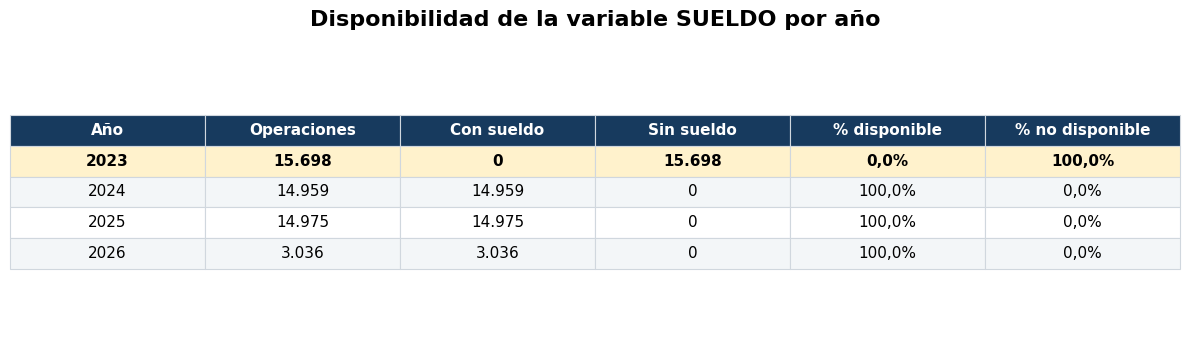

In [ ]:
# ============================================================
# 3. DISPONIBILIDAD DE LA VARIABLE SUELDO POR AÑO
# ============================================================

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Construcción de la tabla
# ------------------------------------------------------------

tabla_sueldo = (
    df.groupby("añofac")
    .agg(
        Operaciones=("factura", "count"),
        Con_sueldo=("SUELDO", lambda x: x.notna().sum()),
        Sin_sueldo=("SUELDO", lambda x: x.isna().sum())
    )
    .reset_index()
    .rename(columns={
        "añofac": "Año",
        "Con_sueldo": "Con sueldo",
        "Sin_sueldo": "Sin sueldo"
    })
)

tabla_sueldo["% disponible"] = (
    tabla_sueldo["Con sueldo"]
    / tabla_sueldo["Operaciones"]
    * 100
)

tabla_sueldo["% no disponible"] = (
    tabla_sueldo["Sin sueldo"]
    / tabla_sueldo["Operaciones"]
    * 100
)


# ------------------------------------------------------------
# Formato visual de los valores
# ------------------------------------------------------------

tabla_visual = tabla_sueldo.copy()

for columna in [
    "Operaciones",
    "Con sueldo",
    "Sin sueldo"
]:
    tabla_visual[columna] = (
        tabla_visual[columna]
        .map(lambda x: f"{x:,.0f}".replace(",", "."))
    )

for columna in [
    "% disponible",
    "% no disponible"
]:
    tabla_visual[columna] = (
        tabla_visual[columna]
        .map(lambda x: f"{x:.1f}%".replace(".", ","))
    )


# ------------------------------------------------------------
# Gráfico de tabla
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(12, 3.5)
)

ax.axis("off")

ax.set_title(
    "Disponibilidad de la variable SUELDO por año",
    fontsize=16,
    fontweight="bold",
    pad=20
)

tabla = ax.table(
    cellText=tabla_visual.values,
    colLabels=tabla_visual.columns,
    cellLoc="center",
    colLoc="center",
    loc="center"
)

tabla.auto_set_font_size(False)
tabla.set_fontsize(11)
tabla.scale(1, 1.8)


# ------------------------------------------------------------
# Formato de encabezados y filas
# ------------------------------------------------------------

for (fila, columna), celda in tabla.get_celld().items():

    celda.set_edgecolor("#D0D7DE")
    celda.set_linewidth(0.8)

    # Encabezado
    if fila == 0:
        celda.set_facecolor("#173A5E")
        celda.set_text_props(
            color="white",
            weight="bold"
        )

    else:

        # Resaltar 2023
        if tabla_visual.iloc[fila - 1]["Año"] == 2023:
            celda.set_facecolor("#FFF2CC")
            celda.set_text_props(
                weight="bold"
            )

        # Filas alternadas
        elif fila % 2 == 0:
            celda.set_facecolor("#F3F6F8")

        else:
            celda.set_facecolor("white")


plt.tight_layout()
plt.show()

# 4. Descripción de la ventana principal de análisis 2024–2026

Una vez definida la ventana principal del estudio, se analiza nuevamente la composición general de la cartera considerando únicamente las operaciones correspondientes al período **2024–2026**.

A partir de este punto, esta será la base principal utilizada en el análisis exploratorio. Se observa la cantidad de operaciones y clientes, la distribución según el estado del préstamo y la composición entre operaciones de **Apertura** y **Renovación**.

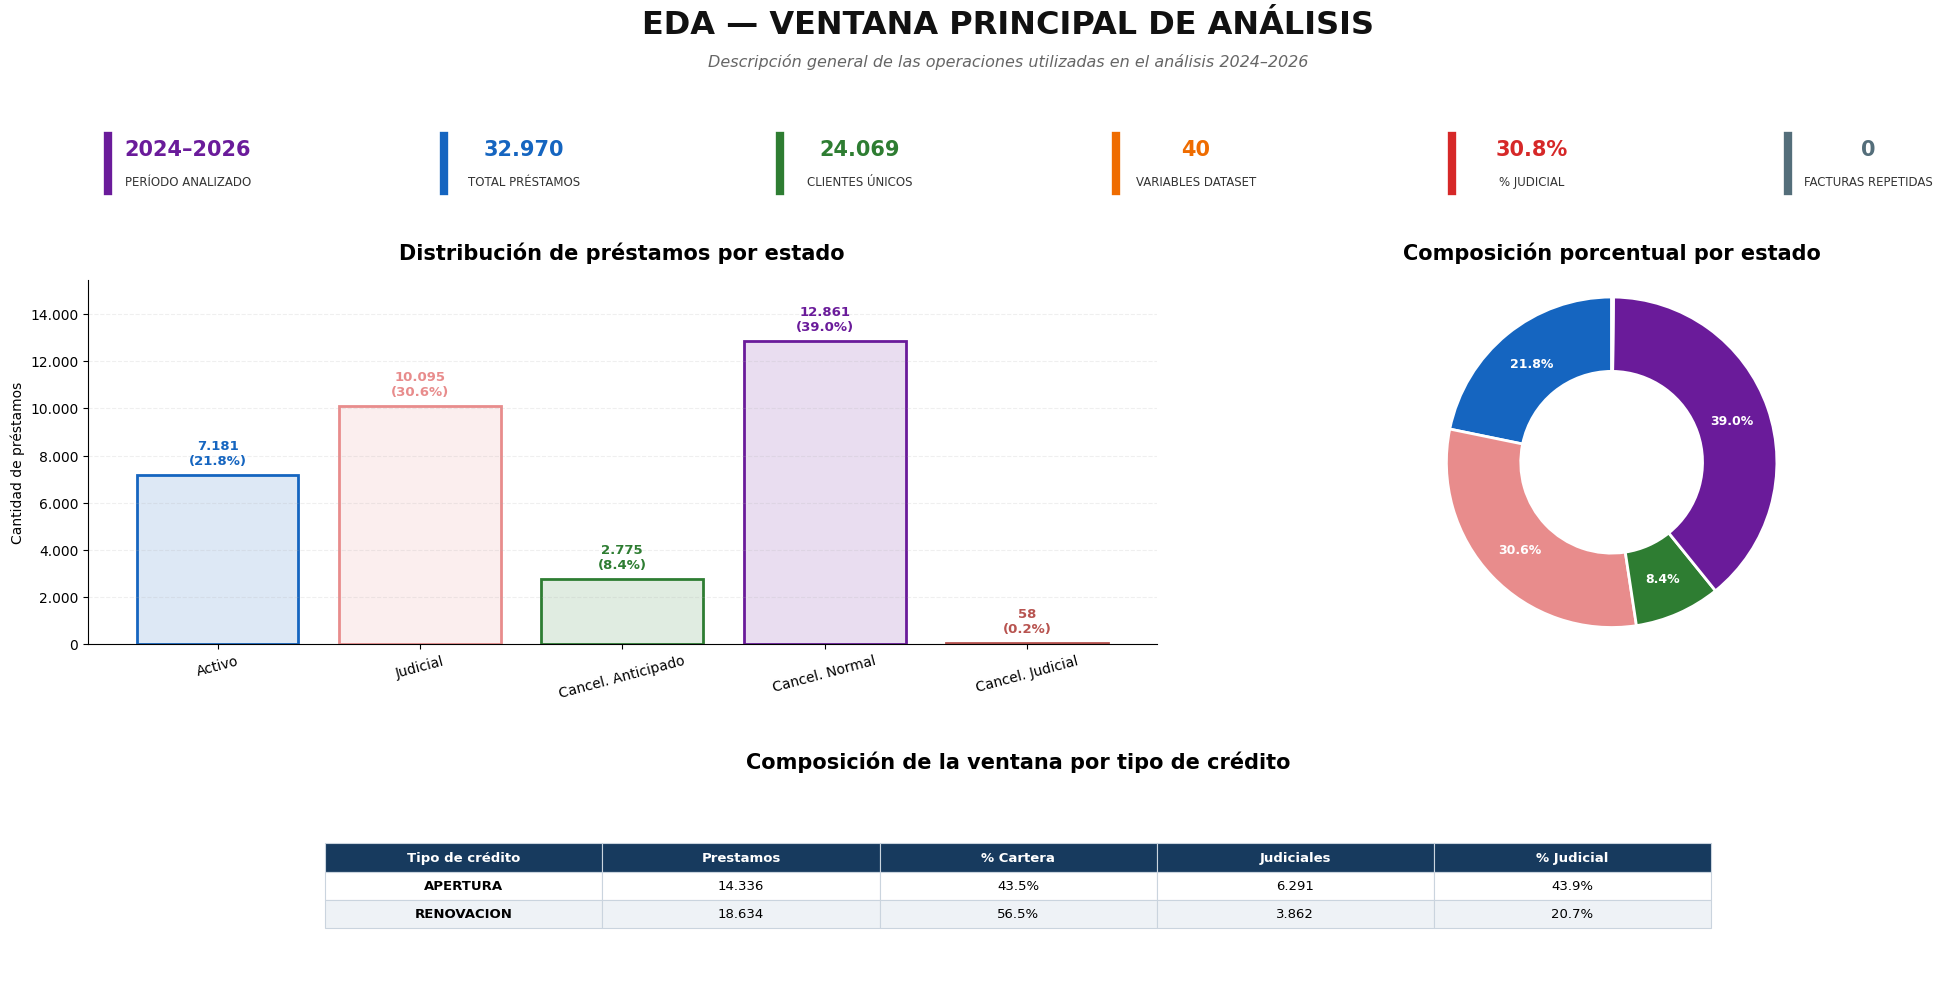

In [ ]:
# ============================================================
# 4. DESCRIPCIÓN DE LA VENTANA PRINCIPAL DE ANÁLISIS
# PERÍODO 2024–2026
# ============================================================

from matplotlib.ticker import FuncFormatter

# Define df_2024_2026 by filtering the original df
df_2024_2026 = df[df["añofac"].isin([2024, 2025, 2026])].copy()

# ------------------------------------------------------------
# 1. INDICADORES GENERALES
# ------------------------------------------------------------

total_prestamos_2426 = len(df_2024_2026)

clientes_unicos_2426 = (
    df_2024_2026["id_cliente"]
    .nunique()
)

cantidad_variables_2426 = (
    df_2024_2026.shape[1]
)

cantidad_judiciales_2426 = (
    df_2024_2026["target"]
    .isin(TARGETS_JUDICIALES)
    .sum()
)

porcentaje_judicial_2426 = (
    cantidad_judiciales_2426
    / total_prestamos_2426
    * 100
)

facturas_repetidas_2426 = (
    df_2024_2026["factura"]
    .dropna()
    .duplicated(keep=False)
    .sum()
)


# ------------------------------------------------------------
# 2. DISTRIBUCIÓN POR ESTADO
# ------------------------------------------------------------

orden_targets = [1, 2, 3, 4, 5]

distribucion_2426 = (
    df_2024_2026["target"]
    .value_counts()
    .reindex(
        orden_targets,
        fill_value=0
    )
)

porcentajes_2426 = (
    distribucion_2426
    / total_prestamos_2426
    * 100
)

nombres = [
    NOMBRES_TARGET[x]
    for x in orden_targets
]

colores = [
    COLORES_TARGET[x]
    for x in orden_targets
]


# ------------------------------------------------------------
# 3. APERTURA VS RENOVACIÓN
# ------------------------------------------------------------

tabla_tipo_2426 = (
    df_2024_2026
    .groupby(
        "tipocredito",
        observed=False
    )
    .agg(
        Prestamos=("factura", "count"),

        Judiciales=(
            "target",
            lambda x: x.isin(
                TARGETS_JUDICIALES
            ).sum()
        )
    )
    .reset_index()
)

tabla_tipo_2426["% Cartera"] = (
    tabla_tipo_2426["Prestamos"]
    / total_prestamos_2426
    * 100
)

tabla_tipo_2426["% Judicial"] = (
    tabla_tipo_2426["Judiciales"]
    / tabla_tipo_2426["Prestamos"]
    * 100
)

tabla_tipo_2426 = (
    tabla_tipo_2426[
        [
            "tipocredito",
            "Prestamos",
            "% Cartera",
            "Judiciales",
            "% Judicial"
        ]
    ]
    .rename(
        columns={
            "tipocredito": "Tipo de crédito"
        }
    )
)


# ------------------------------------------------------------
# 4. FORMATO DE LA TABLA
# ------------------------------------------------------------

tabla_tipo_visual_2426 = (
    tabla_tipo_2426.copy()
)

tabla_tipo_visual_2426[
    "Tipo de crédito"
] = (
    tabla_tipo_visual_2426[
        "Tipo de crédito"
    ]
    .astype(str)
    .str.upper()
)

tabla_tipo_visual_2426[
    "Prestamos"
] = (
    tabla_tipo_visual_2426[
        "Prestamos"
    ]
    .map(formato_entero)
)

tabla_tipo_visual_2426[
    "Judiciales"
] = (
    tabla_tipo_visual_2426[
        "Judiciales"
    ]
    .map(formato_entero)
)

tabla_tipo_visual_2426[
    "% Cartera"
] = (
    tabla_tipo_visual_2426[
        "% Cartera"
    ]
    .map(formato_porcentaje)
)

tabla_tipo_visual_2426[
    "% Judicial"
] = (
    tabla_tipo_visual_2426[
        "% Judicial"
    ]
    .map(formato_porcentaje)
)


# ============================================================
# 5. CONSTRUCCIÓN DEL PANEL
# ============================================================

fig = plt.figure(
    figsize=(20, 11),
    facecolor="white"
)

estructura = fig.add_gridspec(
    nrows=14,
    ncols=24,

    left=0.04,
    right=0.97,
    top=0.77,
    bottom=0.08,

    hspace=1.30,
    wspace=1.00
)


# ------------------------------------------------------------
# TÍTULO
# ------------------------------------------------------------

fig.text(
    0.5,
    0.965,

    "EDA — VENTANA PRINCIPAL DE ANÁLISIS",

    ha="center",
    va="top",

    fontsize=23,
    fontweight="bold",

    color="#111111"
)

fig.text(
    0.5,
    0.925,

    "Descripción general de las operaciones utilizadas en el análisis 2024–2026",

    ha="center",
    va="top",

    fontsize=11.5,
    fontstyle="italic",

    color="#666666"
)


# ------------------------------------------------------------
# 6. TARJETAS DE INDICADORES
# ------------------------------------------------------------

indicadores = [

    (
        "2024–2026",
        "PERÍODO ANALIZADO",
        "#6A1B9A"
    ),

    (
        formato_entero(
            total_prestamos_2426
        ),
        "TOTAL PRÉSTAMOS",
        "#1565C0"
    ),

    (
        formato_entero(
            clientes_unicos_2426
        ),
        "CLIENTES ÚNICOS",
        "#2E7D32"
    ),

    (
        formato_entero(
            cantidad_variables_2426
        ),
        "VARIABLES DATASET",
        "#EF6C00"
    ),

    (
        formato_porcentaje(
            porcentaje_judicial_2426
        ),
        "% JUDICIAL",
        "#D62828"
    ),

    (
        formato_entero(
            facturas_repetidas_2426
        ),
        "FACTURAS REPETIDAS",
        "#546E7A"
    )
]

posiciones = np.linspace(
    0.05,
    0.89,
    len(indicadores)
)

for posicion, (
    valor,
    etiqueta,
    color
) in zip(
    posiciones,
    indicadores
):

    fig.add_artist(
        plt.Line2D(
            [posicion, posicion],
            [0.800, 0.850],

            transform=fig.transFigure,

            color=color,
            linewidth=6
        )
    )

    fig.text(
        posicion + 0.04,
        0.838,

        valor,

        ha="center",
        va="center",

        fontsize=15,
        fontweight="bold",

        color=color
    )

    fig.text(
        posicion + 0.04,
        0.808,

        etiqueta,

        ha="center",
        va="center",

        fontsize=8.5,

        color="#333333"
    )


# ------------------------------------------------------------
# 7. DISTRIBUCIÓN DE PRÉSTAMOS POR ESTADO
# ------------------------------------------------------------

ax_estado = fig.add_subplot(
    estructura[
        1:8,
        0:14
    ]
)

colores_relleno = [
    color + "25"
    for color in colores
]

barras = ax_estado.bar(
    nombres,
    distribucion_2426.values,

    color=colores_relleno,
    edgecolor=colores,

    linewidth=2
)

ax_estado.set_title(
    "Distribución de préstamos por estado",

    fontsize=15,
    fontweight="bold",

    pad=15
)

ax_estado.set_ylabel(
    "Cantidad de préstamos"
)

ax_estado.grid(
    axis="y",
    linestyle="--",
    alpha=0.20
)

ax_estado.spines[
    "top"
].set_visible(False)

ax_estado.spines[
    "right"
].set_visible(False)

ax_estado.tick_params(
    axis="x",
    rotation=15
)

ax_estado.yaxis.set_major_formatter(
    FuncFormatter(
        lambda valor, posicion:
        formato_entero(valor)
    )
)

altura_maxima = (
    distribucion_2426.max()
)

ax_estado.set_ylim(
    0,
    altura_maxima * 1.20
)

for (
    barra,
    cantidad,
    porcentaje,
    color
) in zip(
    barras,
    distribucion_2426.values,
    porcentajes_2426.values,
    colores
):

    ax_estado.text(

        barra.get_x()
        + barra.get_width() / 2,

        barra.get_height()
        + altura_maxima * 0.025,

        (
            f"{formato_entero(cantidad)}\n"
            f"({porcentaje:.1f}%)"
        ),

        ha="center",
        va="bottom",

        fontsize=9.5,
        fontweight="bold",

        color=color
    )


# ------------------------------------------------------------
# 8. COMPOSICIÓN PORCENTUAL
# ------------------------------------------------------------

ax_dona = fig.add_subplot(
    estructura[
        1:8,
        15:24
    ]
)

ax_dona.set_title(
    "Composición porcentual por estado",

    fontsize=15,
    fontweight="bold",

    pad=15
)

ax_dona.pie(

    distribucion_2426.values,

    labels=None,

    colors=colores,

    startangle=90,

    wedgeprops={
        "width": 0.45,
        "edgecolor": "white",
        "linewidth": 2
    },

    autopct=lambda p:
        f"{p:.1f}%"
        if p >= 5
        else "",

    pctdistance=0.77,

    textprops={
        "color": "white",
        "fontsize": 9,
        "fontweight": "bold"
    }
)

ax_dona.axis(
    "equal"
)


# ------------------------------------------------------------
# 9. TABLA APERTURA VS RENOVACIÓN
# ------------------------------------------------------------

ax_tipo = fig.add_subplot(
    estructura[
        10:14,
        3:21
    ]
)

ax_tipo.axis(
    "off"
)

ax_tipo.set_title(
    "Composición de la ventana por tipo de crédito",

    fontsize=15,
    fontweight="bold",

    pad=15
)

tabla = ax_tipo.table(

    cellText=
        tabla_tipo_visual_2426.values,

    colLabels=
        tabla_tipo_visual_2426.columns,

    loc="center",

    cellLoc="center",
    colLoc="center"
)

tabla.auto_set_font_size(
    False
)

tabla.set_fontsize(
    9.5
)

tabla.scale(
    1,
    1.7
)


for (
    fila,
    columna
), celda in tabla.get_celld().items():

    celda.set_edgecolor(
        "#CAD4DE"
    )

    celda.set_linewidth(
        0.8
    )

    if fila == 0:

        celda.set_facecolor(
            "#173A5E"
        )

        celda.set_text_props(
            color="white",
            weight="bold"
        )

    else:

        if fila % 2 == 0:

            celda.set_facecolor(
                "#EEF2F6"
            )

        else:

            celda.set_facecolor(
                "#FFFFFF"
            )

        if columna == 0:

            celda.set_text_props(
                weight="bold"
            )


plt.show()



La exclusión del año 2023 no modifica de manera sustancial la composición del problema de estudio, ya que en la ventana **2024–2026** se mantiene una participación representativa de las operaciones que fueron derivadas a Gestión Judicial. Por lo tanto, la exclusión del 2023 permite trabajar con información más completa sin perder el comportamiento principal que se busca analizar.



# 5. Estados observados y construcción del resultado Judicial / No Judicial


## 5.1 Estados observados de los préstamos

Cada operación del dataset posee un estado que representa la situación observada durante el período de seguimiento.

Los estados considerados son:

- `1` → Activo
- `2` → Judicial
- `3` → Cancelación anticipada
- `4` → Cancelación normal
- `5` → Cancelado en Judicial

Esta variable permite conocer la trayectoria final observada de cada préstamo dentro del período analizado.

Para el problema de estudio, a partir de estos estados se diferencian las operaciones que alcanzaron **Gestión Judicial**, las que finalizaron sin llegar a esa instancia y aquellas que continúan activas.

La unidad de análisis utilizada en el trabajo es cada operación de préstamo.

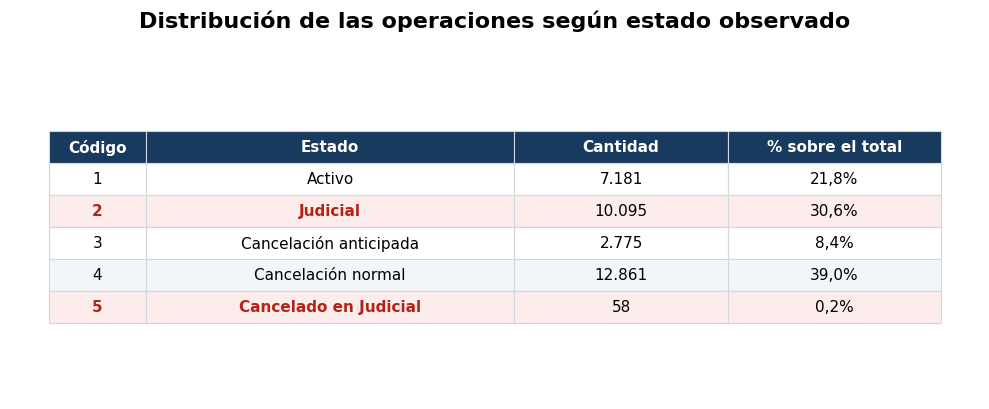

In [ ]:
# ============================================================
# 5. ESTADOS OBSERVADOS DE LOS PRÉSTAMOS
# Ventana principal: 2024–2026
# ============================================================

import matplotlib.pyplot as plt

nombres_target = {
    1: "Activo",
    2: "Judicial",
    3: "Cancelación anticipada",
    4: "Cancelación normal",
    5: "Cancelado en Judicial"
}

tabla_estados = (
    df_2024_2026["target"]
    .value_counts()
    .sort_index()
    .rename_axis("Código")
    .reset_index(name="Cantidad")
)

tabla_estados["Estado"] = (
    tabla_estados["Código"]
    .map(nombres_target)
)

tabla_estados["% sobre el total"] = (
    tabla_estados["Cantidad"]
    / len(df_2024_2026)
    * 100
)

tabla_estados = tabla_estados[
    [
        "Código",
        "Estado",
        "Cantidad",
        "% sobre el total"
    ]
]


# ------------------------------------------------------------
# Formato visual
# ------------------------------------------------------------

tabla_visual = tabla_estados.copy()

tabla_visual["Cantidad"] = (
    tabla_visual["Cantidad"]
    .map(lambda x: f"{x:,.0f}".replace(",", "."))
)

tabla_visual["% sobre el total"] = (
    tabla_visual["% sobre el total"]
    .map(lambda x: f"{x:.1f}%".replace(".", ","))
)


# ------------------------------------------------------------
# Construcción de la tabla gráfica
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 4.2)
)

ax.axis("off")

ax.set_title(
    "Distribución de las operaciones según estado observado",
    fontsize=16,
    fontweight="bold",
    pad=20
)

tabla = ax.table(
    cellText=tabla_visual.values,
    colLabels=tabla_visual.columns,
    cellLoc="center",
    colLoc="center",
    loc="center",
    colWidths=[0.10, 0.38, 0.22, 0.22]
)

tabla.auto_set_font_size(False)
tabla.set_fontsize(11)
tabla.scale(1, 1.8)


# ------------------------------------------------------------
# Estilo
# ------------------------------------------------------------

for (fila, columna), celda in tabla.get_celld().items():

    celda.set_edgecolor("#D0D7DE")
    celda.set_linewidth(0.8)

    if fila == 0:

        celda.set_facecolor("#173A5E")
        celda.set_text_props(
            color="white",
            weight="bold"
        )

    else:

        # Resaltar los estados relacionados con Gestión Judicial
        codigo = tabla_estados.iloc[fila - 1]["Código"]

        if codigo in [2, 5]:

            celda.set_facecolor("#FDECEC")

            if columna in [0, 1]:
                celda.set_text_props(
                    color="#B42318",
                    weight="bold"
                )

        elif fila % 2 == 0:

            celda.set_facecolor("#F3F6F8")

        else:

            celda.set_facecolor("white")


plt.tight_layout()
plt.show()

## 5.2 Construcción de la clasificación Judicial / No Judicial

A partir de los estados observados de los préstamos, se construye una variable binaria que representa el resultado relevante para el problema de estudio.

Se consideran como operaciones **Judiciales** aquellas que fueron derivadas a Gestión Judicial, independientemente de que posteriormente hayan sido canceladas dentro de esa instancia.

La clasificación utilizada es la siguiente:

- `target = 2` → Judicial → `1`
- `target = 5` → Cancelado en Judicial → `1`
- `target = 3` → Cancelación anticipada → `0`
- `target = 4` → Cancelación normal → `0`
- `target = 1` → Activo → sin resultado definitivo

Las operaciones activas no se clasifican como No Judicial, ya que al cierre del período de seguimiento todavía no presentan un desenlace definitivo.

La nueva variable `judicial_bin` será utilizada en los análisis posteriores para comparar la judicialización entre distintos segmentos de la cartera.

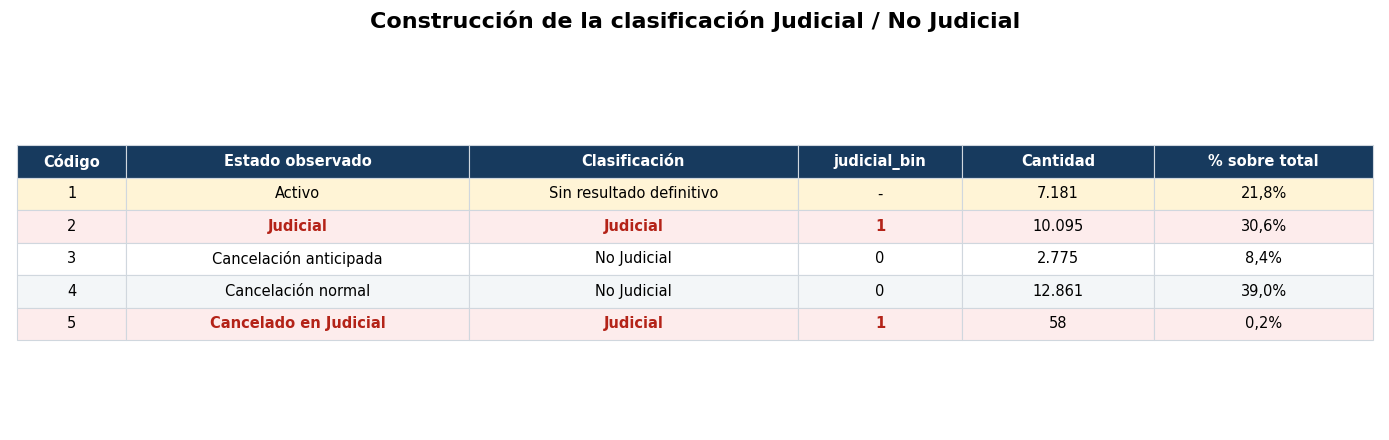

In [ ]:
# ============================================================
# 5.2 CONSTRUCCIÓN DE LA CLASIFICACIÓN JUDICIAL / NO JUDICIAL
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Crear variable binaria
# ------------------------------------------------------------

df_2024_2026["judicial_bin"] = np.select(
    [
        df_2024_2026["target"].isin([2, 5]),
        df_2024_2026["target"].isin([3, 4])
    ],
    [
        1,
        0
    ],
    default=np.nan
)


# ------------------------------------------------------------
# 2. Diccionarios de interpretación
# ------------------------------------------------------------

nombres_estado = {
    1: "Activo",
    2: "Judicial",
    3: "Cancelación anticipada",
    4: "Cancelación normal",
    5: "Cancelado en Judicial"
}

clasificacion = {
    1: "Sin resultado definitivo",
    2: "Judicial",
    3: "No Judicial",
    4: "No Judicial",
    5: "Judicial"
}

valor_binario = {
    1: "-",
    2: "1",
    3: "0",
    4: "0",
    5: "1"
}


# ------------------------------------------------------------
# 3. Cantidad real por estado
# ------------------------------------------------------------

conteo_estados = (
    df_2024_2026["target"]
    .value_counts()
    .sort_index()
)


tabla_clasificacion = pd.DataFrame({
    "Código": [1, 2, 3, 4, 5]
})


tabla_clasificacion["Estado observado"] = (
    tabla_clasificacion["Código"]
    .map(nombres_estado)
)

tabla_clasificacion["Clasificación"] = (
    tabla_clasificacion["Código"]
    .map(clasificacion)
)

tabla_clasificacion["judicial_bin"] = (
    tabla_clasificacion["Código"]
    .map(valor_binario)
)

tabla_clasificacion["Cantidad"] = (
    tabla_clasificacion["Código"]
    .map(conteo_estados)
    .fillna(0)
    .astype(int)
)

tabla_clasificacion["% sobre total"] = (
    tabla_clasificacion["Cantidad"]
    / len(df_2024_2026)
    * 100
)


# ------------------------------------------------------------
# 4. Formato visual
# ------------------------------------------------------------

tabla_visual = tabla_clasificacion.copy()

tabla_visual["Cantidad"] = (
    tabla_visual["Cantidad"]
    .map(lambda x: f"{x:,.0f}".replace(",", "."))
)

tabla_visual["% sobre total"] = (
    tabla_visual["% sobre total"]
    .map(lambda x: f"{x:.1f}%".replace(".", ","))
)


# ------------------------------------------------------------
# 5. Tabla gráfica
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 4.5))

ax.axis("off")

ax.set_title(
    "Construcción de la clasificación Judicial / No Judicial",
    fontsize=16,
    fontweight="bold",
    pad=20
)

tabla = ax.table(
    cellText=tabla_visual.values,
    colLabels=tabla_visual.columns,
    cellLoc="center",
    colLoc="center",
    loc="center",
    colWidths=[
        0.08,   # Código
        0.25,   # Estado
        0.24,   # Clasificación
        0.12,   # judicial_bin
        0.14,   # Cantidad
        0.16    # %
    ]
)

tabla.auto_set_font_size(False)
tabla.set_fontsize(10.5)
tabla.scale(1, 1.8)


for (fila, columna), celda in tabla.get_celld().items():

    celda.set_edgecolor("#D0D7DE")
    celda.set_linewidth(0.8)

    if fila == 0:

        celda.set_facecolor("#173A5E")

        celda.set_text_props(
            color="white",
            weight="bold"
        )

    else:

        codigo = tabla_clasificacion.iloc[fila - 1]["Código"]

        # Judicial
        if codigo in [2, 5]:
            celda.set_facecolor("#FDECEC")

            if columna in [1, 2, 3]:
                celda.set_text_props(
                    color="#B42318",
                    weight="bold"
                )

        # Activo
        elif codigo == 1:
            celda.set_facecolor("#FFF4D6")

        # No Judicial
        elif fila % 2 == 0:
            celda.set_facecolor("#F3F6F8")

        else:
            celda.set_facecolor("white")


plt.tight_layout()
plt.show()

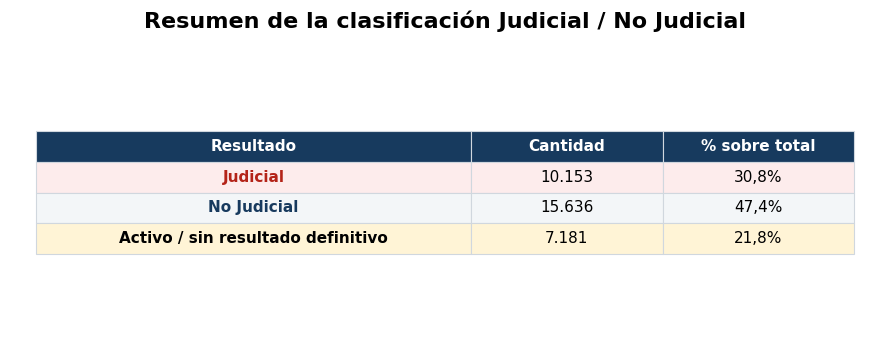

In [ ]:
# ============================================================
# RESUMEN FINAL DE LA CLASIFICACIÓN
# ============================================================

resumen_binario = pd.DataFrame({

    "Resultado": [
        "Judicial",
        "No Judicial",
        "Activo / sin resultado definitivo"
    ],

    "Cantidad": [
        df_2024_2026["judicial_bin"].eq(1).sum(),
        df_2024_2026["judicial_bin"].eq(0).sum(),
        df_2024_2026["judicial_bin"].isna().sum()
    ]
})


resumen_binario["% sobre total"] = (
    resumen_binario["Cantidad"]
    / len(df_2024_2026)
    * 100
)


# ------------------------------------------------------------
# Formato visual
# ------------------------------------------------------------

resumen_visual = resumen_binario.copy()

resumen_visual["Cantidad"] = (
    resumen_visual["Cantidad"]
    .map(lambda x: f"{x:,.0f}".replace(",", "."))
)

resumen_visual["% sobre total"] = (
    resumen_visual["% sobre total"]
    .map(lambda x: f"{x:.1f}%".replace(".", ","))
)


# ------------------------------------------------------------
# Tabla profesional
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 3.5))

ax.axis("off")

ax.set_title(
    "Resumen de la clasificación Judicial / No Judicial",
    fontsize=16,
    fontweight="bold",
    pad=20
)

tabla = ax.table(
    cellText=resumen_visual.values,
    colLabels=resumen_visual.columns,
    cellLoc="center",
    colLoc="center",
    loc="center",
    colWidths=[
        0.50,
        0.22,
        0.22
    ]
)

tabla.auto_set_font_size(False)
tabla.set_fontsize(11)
tabla.scale(1, 1.8)


for (fila, columna), celda in tabla.get_celld().items():

    celda.set_edgecolor("#D0D7DE")
    celda.set_linewidth(0.8)

    if fila == 0:

        celda.set_facecolor("#173A5E")

        celda.set_text_props(
            color="white",
            weight="bold"
        )

    else:

        resultado = resumen_binario.iloc[fila - 1]["Resultado"]

        if resultado == "Judicial":
            celda.set_facecolor("#FDECEC")

            if columna == 0:
                celda.set_text_props(
                    color="#B42318",
                    weight="bold"
                )

        elif resultado == "Activo / sin resultado definitivo":
            celda.set_facecolor("#FFF4D6")

            if columna == 0:
                celda.set_text_props(
                    weight="bold"
                )

        else:
            celda.set_facecolor("#F3F6F8")

            if columna == 0:
                celda.set_text_props(
                    weight="bold",
                    color="#173A5E"
                )


plt.tight_layout()
plt.show()

## 5.3 Evolución anual de la cantidad de préstamos

A continuación se observa la distribución anual de las operaciones incluidas en la ventana principal de análisis **2024–2026**.

Para cada año se presenta la cantidad de préstamos y su participación porcentual sobre el total de operaciones de la ventana seleccionada.

Debe considerarse que **2026 corresponde a un período parcial**, por lo que su menor participación se encuentra condicionada por la menor cantidad de meses incluidos en la base.

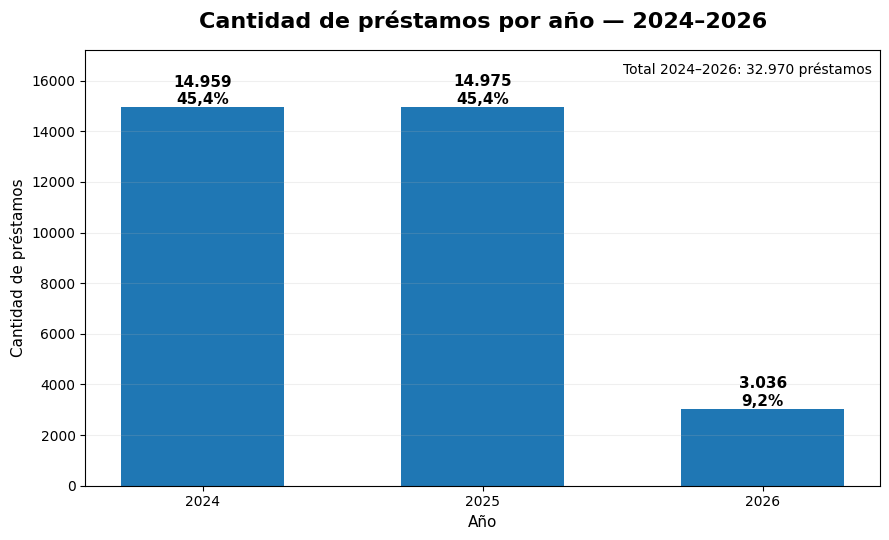

Imagen guardada en:
/content/drive/MyDrive/PROYECTO TESIS/SEMINARIO/prestamos_por_anio_2024_2026.png


In [ ]:
# ============================================================
# 5.3 EVOLUCIÓN ANUAL DE LA CANTIDAD DE PRÉSTAMOS
# Ventana principal: 2024–2026
# ============================================================

import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Resumen anual
# ------------------------------------------------------------

tabla_anual = (
    df_2024_2026
    .groupby("añofac")
    .size()
    .reset_index(name="Cantidad")
    .rename(columns={
        "añofac": "Año"
    })
)


# Participación de cada año sobre el total 2024–2026
tabla_anual["Porcentaje"] = (
    tabla_anual["Cantidad"]
    / tabla_anual["Cantidad"].sum()
    * 100
)


# ------------------------------------------------------------
# Gráfico de bastones verticales
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(9, 5.5)
)

barras = ax.bar(
    tabla_anual["Año"].astype(str),
    tabla_anual["Cantidad"],
    width=0.58
)


# ------------------------------------------------------------
# Cantidad + porcentaje sobre cada barra
# ------------------------------------------------------------

for barra, cantidad, porcentaje in zip(
    barras,
    tabla_anual["Cantidad"],
    tabla_anual["Porcentaje"]
):

    etiqueta = (
        f"{cantidad:,.0f}".replace(",", ".")
        + "\n"
        + f"{porcentaje:.1f}%".replace(".", ",")
    )

    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        etiqueta,
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )


# ------------------------------------------------------------
# Formato
# ------------------------------------------------------------

ax.set_title(
    "Cantidad de préstamos por año — 2024–2026",
    fontsize=16,
    fontweight="bold",
    pad=16
)

ax.set_xlabel(
    "Año",
    fontsize=11
)

ax.set_ylabel(
    "Cantidad de préstamos",
    fontsize=11
)

ax.grid(
    axis="y",
    alpha=0.20
)

# Dar espacio arriba para las etiquetas
ax.set_ylim(
    0,
    tabla_anual["Cantidad"].max() * 1.15
)


# ------------------------------------------------------------
# Nota del total analizado
# ------------------------------------------------------------

total_operaciones = tabla_anual["Cantidad"].sum()

ax.text(
    0.99,
    0.97,
    "Total 2024–2026: "
    + f"{total_operaciones:,.0f}".replace(",", ".")
    + " préstamos",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=10
)


plt.tight_layout()


# ------------------------------------------------------------
# Guardar imagen
# ------------------------------------------------------------

ruta_grafico = (
    "/content/drive/MyDrive/PROYECTO TESIS/"
    "SEMINARIO/prestamos_por_anio_2024_2026.png"
)

plt.savefig(
    ruta_grafico,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Imagen guardada en:")
print(ruta_grafico)

## 5.4 Composición anual de la cartera por condición observada

En este gráfico se presenta la composición anual de la cartera 2024–2026, diferenciando las operaciones **Activas**, **Judiciales** y **No Judiciales**.

Para esta clasificación se considera:

- **Activo**: operaciones con `target = 1`
- **Judicial**: operaciones con `target = 2` o `target = 5`
- **No Judicial**: operaciones con `target = 3` o `target = 4`

A diferencia del criterio utilizado luego para el modelado, en esta instancia sí se incluyen las operaciones activas, ya que el objetivo es describir la cartera observada en cada año y mostrar su composición completa.

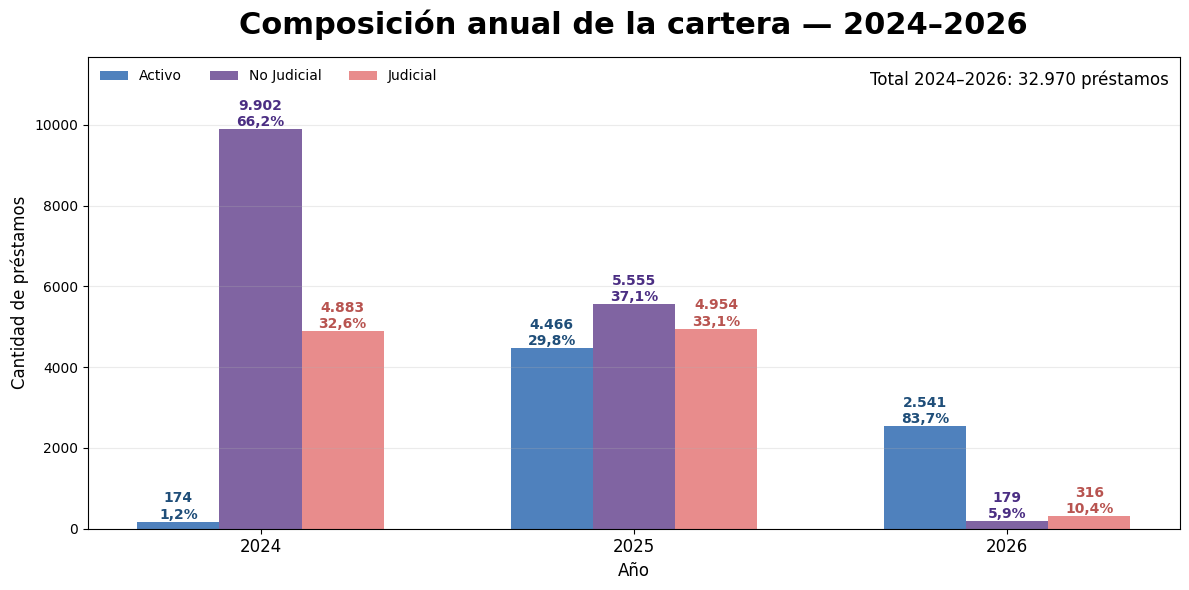

condicion_observada,Activo,No Judicial,Judicial,% Activo,% No Judicial,% Judicial,Total
añofac,,,,,,,
2024,174,9.902,4.883,"1,2%","66,2%","32,6%",14.959
2025,4.466,5.555,4.954,"29,8%","37,1%","33,1%",14.975
2026,2.541,179,316,"83,7%","5,9%","10,4%",3.036


In [ ]:
# ============================================================
# 5.4 COMPOSICIÓN ANUAL DE LA CARTERA POR CONDICIÓN OBSERVADA
# Ventana de análisis: 2024–2026
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Base 2024–2026
# ------------------------------------------------------------
base_eda = df_2024_2026.copy()

# ------------------------------------------------------------
# Clasificación de estados observados
# ------------------------------------------------------------
def clasificar_condicion(target):
    if target == 1:
        return "Activo"
    elif target in [2, 5]:
        return "Judicial"
    elif target in [3, 4]:
        return "No Judicial"
    else:
        return "Otro"

base_eda["condicion_observada"] = base_eda["target"].apply(clasificar_condicion)

# ------------------------------------------------------------
# Tabla de cantidades por año
# ------------------------------------------------------------
tabla_anual = (
    base_eda
    .groupby(["añofac", "condicion_observada"])
    .size()
    .unstack(fill_value=0)
)

# asegurar orden de columnas
for col in ["Activo", "No Judicial", "Judicial"]:
    if col not in tabla_anual.columns:
        tabla_anual[col] = 0

tabla_anual = tabla_anual[["Activo", "No Judicial", "Judicial"]]

# ------------------------------------------------------------
# Porcentajes sobre el total de cada año
# ------------------------------------------------------------
tabla_pct = tabla_anual.div(tabla_anual.sum(axis=1), axis=0) * 100

# ------------------------------------------------------------
# Gráfico
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(tabla_anual.index))
ancho = 0.22

colores = {
    "Activo": "#4F81BD",
    "No Judicial": "#8064A2",
    "Judicial": "#E88C8C"   # rojo claro
}

b1 = ax.bar(x - ancho, tabla_anual["Activo"], width=ancho, color=colores["Activo"], label="Activo")
b2 = ax.bar(x,         tabla_anual["No Judicial"], width=ancho, color=colores["No Judicial"], label="No Judicial")
b3 = ax.bar(x + ancho, tabla_anual["Judicial"], width=ancho, color=colores["Judicial"], label="Judicial")

# ------------------------------------------------------------
# Etiquetas
# ------------------------------------------------------------
def poner_etiquetas(barras, valores_pct, color_texto="black"):
    for i, barra in enumerate(barras):
        y = barra.get_height()
        pct = valores_pct.iloc[i]
        ax.text(
            barra.get_x() + barra.get_width()/2,
            y,
            f"{int(y):,}".replace(",", ".") + f"\n{pct:.1f}%".replace(".", ","),
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold",
            color=color_texto
        )

poner_etiquetas(b1, tabla_pct["Activo"], "#1F4E79")
poner_etiquetas(b2, tabla_pct["No Judicial"], "#4B2E83")
poner_etiquetas(b3, tabla_pct["Judicial"], "#B85450")

# ------------------------------------------------------------
# Formato
# ------------------------------------------------------------
total_general = len(base_eda)

ax.set_title("Composición anual de la cartera — 2024–2026", fontsize=22, fontweight="bold", pad=16)
ax.text(
    0.99, 0.97,
    f"Total 2024–2026: {total_general:,} préstamos".replace(",", "."),
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=12
)

ax.set_xlabel("Año", fontsize=12)
ax.set_ylabel("Cantidad de préstamos", fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(tabla_anual.index.astype(str), fontsize=12)

ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False, ncol=3, loc="upper left")

max_y = tabla_anual.to_numpy().max()
ax.set_ylim(0, max_y * 1.18)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Tabla resumen profesional
# ------------------------------------------------------------
tabla_resumen = tabla_anual.copy()

for col in ["Activo", "No Judicial", "Judicial"]:
    tabla_resumen[f"% {col}"] = tabla_pct[col].round(1)

tabla_resumen["Total"] = tabla_anual.sum(axis=1)

display(
    tabla_resumen.style
    .format({
        "Activo": "{:,.0f}",
        "No Judicial": "{:,.0f}",
        "Judicial": "{:,.0f}",
        "Total": "{:,.0f}",
        "% Activo": "{:.1f}%",
        "% No Judicial": "{:.1f}%",
        "% Judicial": "{:.1f}%"
    }, decimal=",", thousands=".")
    .set_caption("Resumen anual de la cartera según condición observada")
)

### Interpretación de la composición anual de la cartera

La composición anual permite observar cómo se distribuyen las operaciones entre préstamos **Activos**, **No Judiciales** y **Judiciales** dentro de cada año de la ventana 2024–2026.

En esta instancia descriptiva se incluyen las operaciones activas con el objetivo de representar la cartera completa observada en cada período. Esto resulta especialmente importante en **2026**, ya que se trata de un período parcial y una proporción relevante de los préstamos aún continúa activa al cierre de la base.

Por este motivo, los porcentajes mostrados en el gráfico se calculan sobre el total de operaciones de cada año e incluyen las tres condiciones observadas.



# 6. Clasificación de las variables

Antes de continuar con el análisis, se clasifican las variables del dataset según su tipo de dato y su función dentro del estudio.

Se diferencia entre el **tipo técnico** de cada variable —numérica, categórica o fecha— y su **subtipo conceptual**, por ejemplo: continua, discreta, nominal, ordinal, binaria, identificador, historial interno previo o comportamiento posterior.

Esta clasificación permite entender cómo debe ser tratada cada variable en las etapas posteriores del análisis y del modelado.

In [ ]:
# ============================================================
# CLASIFICACION DE VARIABLES SEGUN SU TIPO DE DATO Y SUBTIPO
# DATASET DE ANALISIS 2024-2026
# ============================================================
#
# Esta tabla resuelve en un solo lugar dos preguntas distintas
# sobre cada variable:
#   1) Tipo de variable  -> lo que dice el dtype de pandas
#      (Numerica / Categorica / Fecha). Es una clasificacion
#      mecanica: no sabe nada del significado del dato.
#   2) Subtipo            -> la lectura conceptual que se le da
#      como analista (continua, discreta, nominal, ordinal,
#      binaria, derivada, comportamiento del prestamo actual o
#      historial interno previo). Esta segunda capa es la que
#      realmente importa para decidir como tratar cada variable
#      mas adelante (por ejemplo, si conviene un one-hot, si
#      respeta un orden, o si puede usarse recien en Renovacion).

from IPython.display import display
import pandas as pd
import numpy as np

# Diccionario con la clasificacion conceptual de las variables
# conocidas del dataset. Las que no aparecen aca se clasifican
# con una regla automatica de respaldo (ver mas abajo) y quedan
# marcadas como "a revisar" para no asumir nada de mas.
SUBTIPOS_CONOCIDOS = {
    # Identificadores / objetivo
    "factura": "Identificador",
    "id_cliente": "Identificador",
    "target": "Objetivo (target)",

    # Numericas continuas
    "capitalprestado": "Numérica continua",
    "monto_cuota": "Numérica continua",
    "totalfac": "Numérica continua",
    "SUELDO": "Numérica continua",
    "interes": "Numérica continua",
    "costo_credito": "Numérica continua",
    "score_numerico": "Numérica continua",

    # Derivadas
    "relacion_cuota_ingreso": "Derivada (numérica continua)",

    # Numericas discretas (conteos)
    "plan": "Numérica discreta",
    "cantidad_prestamos_anteriores": "Numérica discreta",
    "cuotas_pagas": "Numérica discreta",
    "cuotas_pendientes": "Numérica discreta",
    "antiguedad_credito": "Numérica discreta",
    "CANT. MESES MORA >30": "Numérica discreta",
    "CANT. MESES MORA >60": "Numérica discreta",
    "CANT. MESES MORA >90": "Numérica discreta",
    "CANT. MESES MORA >120": "Numérica discreta",
    "CANT. MESES MORA >150": "Numérica discreta",

    # Categoricas nominales (sin orden)
    "provincia": "Categórica nominal",
    "actividad": "Categórica nominal",
    "motivocompra": "Categórica nominal",
    "sucursal": "Categórica nominal",
    "tipocredito": "Categórica nominal",
    "genero": "Categórica nominal",

    # Categoricas ordinales (con orden)
    "rangoedad": "Categórica ordinal",
    "tramo_score_100": "Categórica ordinal",
    "rango_cuota_ingreso": "Categórica ordinal",
    "rscore": "Categórica ordinal",

    # Binarias
    "tuvo_mora_anterior": "Binaria",
    "renovacion_sin_historial_observable": "Binaria",
    "judicial_bin": "Binaria",

    # Comportamiento del prestamo actual (posterior al otorgamiento)
    "saldofactura": "Comportamiento (posterior)",
    "saldo_relativo": "Comportamiento (posterior)",
    "ratio_cumplimiento": "Comportamiento (posterior)",
    "%cobrado": "Comportamiento (posterior)",
    "MAX DIA MORA": "Comportamiento (posterior)",

    # Historial interno previo (Renovacion)
    "max_mora_prestamos_anteriores": "Historial interno previo",
    "prestamos_cancelados_normal": "Historial interno previo",
    "prestamos_en_judicial_anteriores": "Historial interno previo",

    # Temporales descriptivas
    "añofac": "Temporal descriptiva",
    "mesfac": "Temporal descriptiva",
}


def clasificar_tipo_variable(serie):
    """Clasificacion mecanica segun el dtype de pandas."""
    if pd.api.types.is_datetime64_any_dtype(serie):
        return "Fecha"
    elif pd.api.types.is_numeric_dtype(serie):
        return "Numérica"
    else:
        return "Categórica"


def clasificar_subtipo(nombre_columna, serie):
    """
    Devuelve el subtipo conceptual de la variable.
    Prioriza el diccionario de variables conocidas. Para el resto,
    aplica una regla de respaldo basada en la cantidad de valores
    unicos y deja marcado "a revisar" en vez de asumir un subtipo.
    """
    if nombre_columna in SUBTIPOS_CONOCIDOS:
        return SUBTIPOS_CONOCIDOS[nombre_columna]

    if pd.api.types.is_numeric_dtype(serie):
        if serie.nunique(dropna=True) <= 15:
            return "Numérica discreta (a revisar)"
        return "Numérica continua (a revisar)"

    if serie.nunique(dropna=True) <= 15:
        return "Categórica nominal (a revisar)"

    return "Categórica (a revisar)"


tabla_variables = pd.DataFrame({
    "Variable": df_2024_2026.columns,
    "Tipo de variable": [
        clasificar_tipo_variable(df_2024_2026[columna])
        for columna in df_2024_2026.columns
    ],
    "Subtipo": [
        clasificar_subtipo(columna, df_2024_2026[columna])
        for columna in df_2024_2026.columns
    ],
    "Tipo técnico": [
        str(df_2024_2026[columna].dtype)
        for columna in df_2024_2026.columns
    ],
    "Valores únicos": [
        df_2024_2026[columna].nunique(dropna=True)
        for columna in df_2024_2026.columns
    ],
    "Datos nulos": [
        df_2024_2026[columna].isna().sum()
        for columna in df_2024_2026.columns
    ]
})

tabla_variables["% nulos"] = (
    tabla_variables["Datos nulos"]
    / len(df_2024_2026)
    * 100
)

# Ordenar primero por tipo y luego por nombre
orden_tipos = ["Numérica", "Categórica", "Fecha"]

tabla_variables["Tipo de variable"] = pd.Categorical(
    tabla_variables["Tipo de variable"],
    categories=orden_tipos,
    ordered=True
)

tabla_variables = (
    tabla_variables
    .sort_values(
        ["Tipo de variable", "Variable"]
    )
    .reset_index(drop=True)
)

# Cuantas variables quedaron sin clasificacion manual, para
# saber si conviene revisar y completar el diccionario
sin_clasificar = tabla_variables["Subtipo"].str.contains(
    "a revisar", na=False
).sum()

if sin_clasificar > 0:
    print(
        f"Nota: {sin_clasificar} variable(s) quedaron con subtipo "
        "automatico ('a revisar'). Conviene revisar el diccionario "
        "SUBTIPOS_CONOCIDOS si corresponde precisarlas."
    )

# Mostrar tabla profesional
display(
    tabla_variables.style
    .set_caption(
        "Clasificación de las variables del dataset — Período 2024–2026"
    )
    .format({
        "Valores únicos": "{:,.0f}",
        "Datos nulos": "{:,.0f}",
        "% nulos": "{:.1f}%"
    })
    .hide(axis="index")
    .set_properties(**{
        "background-color": "white !important",
        "color": "black !important",
        "text-align": "center",
        "font-size": "12px",
        "padding": "8px",
        "border": "1px solid #D9E1E8"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("background-color", "white !important"),
                ("border-collapse", "collapse"),
                ("width", "95%"),
                ("margin", "auto")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("background-color", "white !important"),
                ("color", "black !important"),
                ("font-size", "20px"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("padding", "14px")
            ]
        },
        {
            "selector": "thead th",
            "props": [
                ("background-color", "#1F4E78 !important"),
                ("color", "white !important"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("padding", "9px")
            ]
        },
        {
            "selector": "tbody tr:nth-child(even) td",
            "props": [
                ("background-color", "#F3F6F9 !important")
            ]
        },
        {
            "selector": "tbody tr:nth-child(odd) td",
            "props": [
                ("background-color", "white !important")
            ]
        }
    ])
)


Nota: 1 variable(s) quedaron con subtipo automatico ('a revisar'). Conviene revisar el diccionario SUBTIPOS_CONOCIDOS si corresponde precisarlas.


Variable,Tipo de variable,Subtipo,Tipo técnico,Valores únicos,Datos nulos,% nulos
%cobrado,Numérica,Comportamiento (posterior),float64,"11,886",0,0.0%
CANT. MESES MORA >120,Numérica,Numérica discreta,int64,15,0,0.0%
CANT. MESES MORA >150,Numérica,Numérica discreta,int64,14,0,0.0%
CANT. MESES MORA >30,Numérica,Numérica discreta,int64,21,0,0.0%
CANT. MESES MORA >60,Numérica,Numérica discreta,int64,18,0,0.0%
CANT. MESES MORA >90,Numérica,Numérica discreta,int64,17,0,0.0%
MAX DIA MORA,Numérica,Comportamiento (posterior),int64,593,0,0.0%
SUELDO,Numérica,Numérica continua,float64,"30,107",0,0.0%
antiguedad_credito,Numérica,Numérica discreta,float64,675,0,0.0%
añofac,Numérica,Temporal descriptiva,int64,3,0,0.0%




El dataset está compuesto por variables numéricas y categóricas. Esa primera clasificación viene del tipo de dato técnico (dtype) y es automática, pero se queda corta para decidir cómo tratar cada variable más adelante — por eso la tabla anterior agrega una columna **Subtipo** con una lectura más fina:

- **Numéricas continuas**: expresan magnitudes que pueden tomar cualquier valor dentro de un rango, por ejemplo capital prestado, sueldo, interés o monto de cuota.
- **Numéricas discretas**: representan conteos, por ejemplo cuotas pagadas o cantidad de préstamos anteriores.
- **Categóricas nominales**: identifican grupos sin orden cuantitativo, por ejemplo provincia, actividad o motivo de compra.
- **Categóricas ordinales**: poseen un orden natural, por ejemplo rango de edad o tramos de score.
- **Binarias**: representan dos estados, por ejemplo tuvo mora anterior (sí/no) o el target judicial (1/0).
- **Derivadas**: se calculan a partir de otras variables; en este estudio, la relación cuota-ingreso resume el esfuerzo de pago inicial.
- **Comportamiento del préstamo actual**: describen lo ocurrido luego del otorgamiento. Son útiles para comprender el desenlace y para futuros modelos de cobranzas, pero no son predictores válidos del modelo inicial.
- **Historial interno previo**: resume préstamos anteriores del cliente y puede utilizarse en Renovación siempre que sea estrictamente anterior a la factura actual.

Esta doble clasificación (tipo técnico + subtipo) permite anticipar qué variables requerirán tratamientos diferentes en etapas posteriores del análisis, especialmente en cuanto a su representación (por ejemplo, one-hot para nominales, orden explícito para ordinales) y su momento de uso válido en el modelado.

La variable FECHA JUDICIAL quedó señalada para revisión en la clasificación automática. Corresponde a la fecha de derivación a Gestión Judicial y no se utiliza como predictor, porque se conoce después del otorgamiento.

# 7. Construcción de la variable relación cuota-ingreso

Con el objetivo de representar el esfuerzo financiero inicial de cada operación, se construye la variable `relacion_cuota_ingreso`.

Esta variable indica qué porcentaje del ingreso mensual informado representa el valor de la cuota del préstamo y se calcula de la siguiente manera:

**Relación cuota-ingreso = (Monto de la cuota / Sueldo) × 100**

Por ejemplo, un valor de 30 indica que la cuota representa el **30 % del ingreso mensual informado**.

La variable se calcula únicamente cuando el sueldo es mayor que cero, evitando divisiones inválidas o resultados que no puedan ser interpretados correctamente.

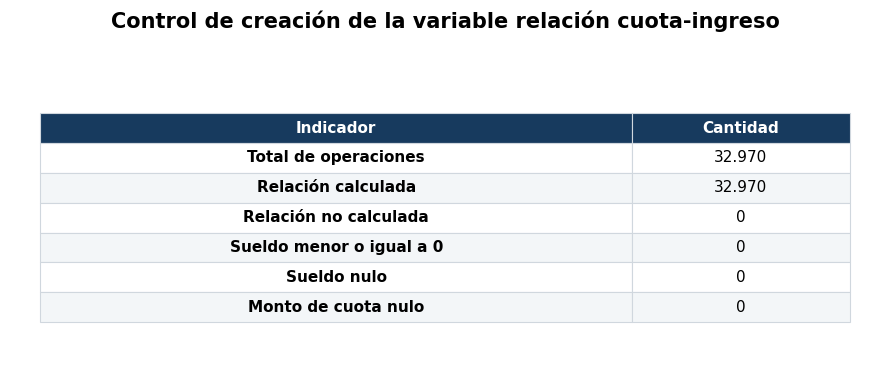

In [ ]:
# ============================================================
# 7. CONSTRUCCIÓN DE LA VARIABLE RELACIÓN CUOTA-INGRESO
# Ventana principal: 2024–2026
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Crear la variable como porcentaje
# ------------------------------------------------------------

df_2024_2026["relacion_cuota_ingreso"] = np.where(
    df_2024_2026["SUELDO"] > 0,
    (
        df_2024_2026["monto_cuota"]
        / df_2024_2026["SUELDO"]
    ) * 100,
    np.nan
)


# ------------------------------------------------------------
# Control de creación
# ------------------------------------------------------------

tabla_relacion = pd.DataFrame({

    "Indicador": [
        "Total de operaciones",
        "Relación calculada",
        "Relación no calculada",
        "Sueldo menor o igual a 0",
        "Sueldo nulo",
        "Monto de cuota nulo"
    ],

    "Cantidad": [
        len(df_2024_2026),

        df_2024_2026[
            "relacion_cuota_ingreso"
        ].notna().sum(),

        df_2024_2026[
            "relacion_cuota_ingreso"
        ].isna().sum(),

        (
            df_2024_2026["SUELDO"] <= 0
        ).sum(),

        df_2024_2026[
            "SUELDO"
        ].isna().sum(),

        df_2024_2026[
            "monto_cuota"
        ].isna().sum()
    ]
})


# ------------------------------------------------------------
# Formato de presentación
# ------------------------------------------------------------

tabla_visual = tabla_relacion.copy()

tabla_visual["Cantidad"] = (
    tabla_visual["Cantidad"]
    .map(
        lambda x:
        f"{x:,.0f}".replace(",", ".")
    )
)


# ------------------------------------------------------------
# Tabla gráfica
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(9, 4)
)

ax.axis("off")

ax.set_title(
    "Control de creación de la variable relación cuota-ingreso",
    fontsize=15,
    fontweight="bold",
    pad=20
)

tabla = ax.table(

    cellText=tabla_visual.values,

    colLabels=tabla_visual.columns,

    cellLoc="center",
    colLoc="center",

    loc="center",

    colWidths=[
        0.68,
        0.25
    ]
)

tabla.auto_set_font_size(False)

tabla.set_fontsize(11)

tabla.scale(
    1,
    1.7
)


# ------------------------------------------------------------
# Estilo
# ------------------------------------------------------------

for (fila, columna), celda in tabla.get_celld().items():

    celda.set_edgecolor("#D0D7DE")
    celda.set_linewidth(0.8)

    if fila == 0:

        celda.set_facecolor("#173A5E")

        celda.set_text_props(
            color="white",
            weight="bold"
        )

    else:

        if fila % 2 == 0:

            celda.set_facecolor("#F3F6F8")

        else:

            celda.set_facecolor("white")

        if columna == 0:

            celda.set_text_props(
                weight="bold"
            )


plt.tight_layout()
plt.show()

# 8. Estadísticos descriptivos por tipo de crédito

A partir de la ventana principal 2024–2026, se analizan las principales variables numéricas relacionadas con las características del préstamo y del cliente, diferenciando las operaciones de **Apertura** y **Renovación**.

Para cada variable se presentan medidas de tendencia central y dispersión, junto con los percentiles 25 y 75 y la cantidad de observaciones ubicadas fuera de los límites definidos mediante el rango intercuartil (IQR).

una observación fuera del rango IQR **no se considera automáticamente un error ni un dato inválido**. En una cartera de créditos pueden existir operaciones reales con montos, ingresos o condiciones menos frecuentes. Por este motivo, estos casos se identifican para conocer la distribución de los datos, pero no se eliminan automáticamente.

En las operaciones de Renovación se incorporan además variables relacionadas con el historial previo del cliente, como la antigüedad crediticia y la máxima mora registrada en préstamos anteriores.

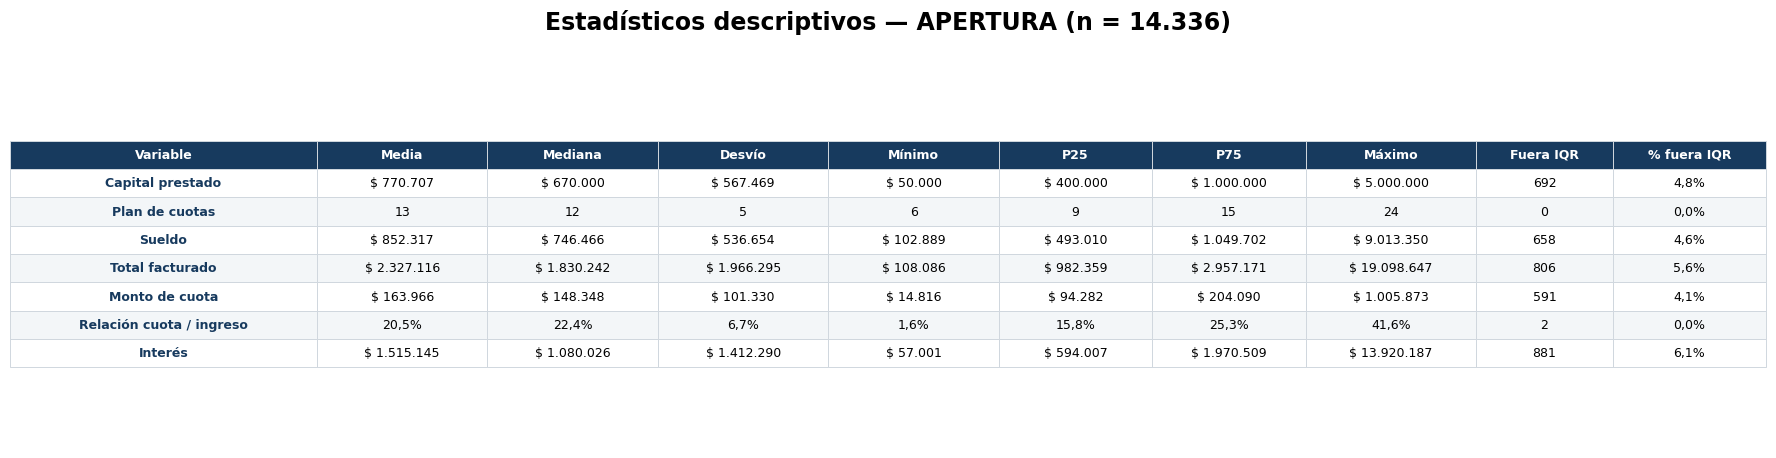

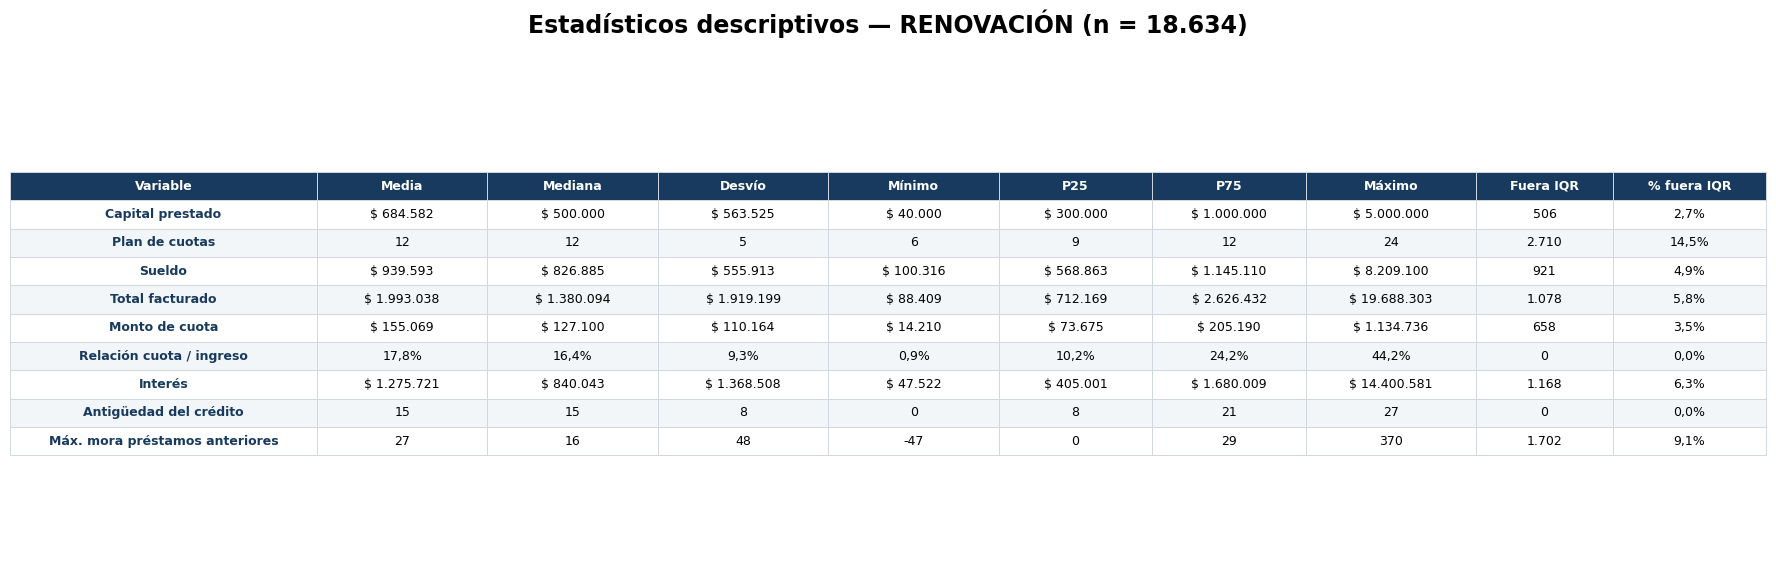

In [ ]:
# ============================================================
# 8. ESTADÍSTICOS DESCRIPTIVOS POR TIPO DE CRÉDITO
# Ventana principal: 2024–2026
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


# ------------------------------------------------------------
# 1. Separación de Apertura y Renovación
# ------------------------------------------------------------

df_apertura = df_2024_2026[
    df_2024_2026["tipocredito"]
    .astype(str)
    .str.upper()
    .str.contains("APERTURA")
].copy()


df_renovacion = df_2024_2026[
    df_2024_2026["tipocredito"]
    .astype(str)
    .str.upper()
    .str.contains("RENOV")
].copy()


# ------------------------------------------------------------
# 2. Variables seleccionadas
# ------------------------------------------------------------

variables_apertura = [
    "capitalprestado",
    "plan",
    "SUELDO",
    "totalfac",
    "monto_cuota",
    "relacion_cuota_ingreso",
    "interes"
]


variables_renovacion = [
    "capitalprestado",
    "plan",
    "SUELDO",
    "totalfac",
    "monto_cuota",
    "relacion_cuota_ingreso",
    "interes",
    "antiguedad_credito",
    "max_mora_prestamos_anteriores"
]


# ------------------------------------------------------------
# 3. Nombres para presentación
# ------------------------------------------------------------

nombres_variables = {
    "capitalprestado": "Capital prestado",
    "plan": "Plan de cuotas",
    "SUELDO": "Sueldo",
    "totalfac": "Total facturado",
    "monto_cuota": "Monto de cuota",
    "relacion_cuota_ingreso": "Relación cuota / ingreso",
    "interes": "Interés",
    "antiguedad_credito": "Antigüedad del crédito",
    "max_mora_prestamos_anteriores":
        "Máx. mora préstamos anteriores"
}


# ------------------------------------------------------------
# 4. Función para calcular estadísticos
# ------------------------------------------------------------

def calcular_descriptivos(base, variables):

    resultados = []

    for variable in variables:

        serie = (
            pd.to_numeric(
                base[variable],
                errors="coerce"
            )
            .dropna()
        )

        q1 = serie.quantile(0.25)
        q3 = serie.quantile(0.75)

        iqr = q3 - q1

        limite_inferior = q1 - 1.5 * iqr
        limite_superior = q3 + 1.5 * iqr

        fuera_iqr = (
            (serie < limite_inferior)
            | (serie > limite_superior)
        ).sum()

        resultados.append({
            "Variable":
                nombres_variables.get(variable, variable),

            "Media":
                serie.mean(),

            "Mediana":
                serie.median(),

            "Desvío":
                serie.std(),

            "Mínimo":
                serie.min(),

            "P25":
                q1,

            "P75":
                q3,

            "Máximo":
                serie.max(),

            "Fuera IQR":
                fuera_iqr,

            "% fuera IQR":
                fuera_iqr / len(serie) * 100
                if len(serie) > 0
                else np.nan
        })

    return pd.DataFrame(resultados)


tabla_apertura = calcular_descriptivos(
    df_apertura,
    variables_apertura
)

tabla_renovacion = calcular_descriptivos(
    df_renovacion,
    variables_renovacion
)


# ------------------------------------------------------------
# 5. Funciones de formato
# ------------------------------------------------------------

variables_dinero = {
    "Capital prestado",
    "Sueldo",
    "Total facturado",
    "Monto de cuota",
    "Interés"
}


variables_enteras = {
    "Plan de cuotas",
    "Antigüedad del crédito",
    "Máx. mora préstamos anteriores"
}


def formato_moneda(valor):
    if pd.isna(valor):
        return "-"
    return "$ " + f"{valor:,.0f}".replace(",", ".")


def formato_entero(valor):
    if pd.isna(valor):
        return "-"
    return f"{valor:,.0f}".replace(",", ".")


def formato_porcentaje(valor):
    if pd.isna(valor):
        return "-"
    return f"{valor:.1f}%".replace(".", ",")


def formato_numero(valor):
    if pd.isna(valor):
        return "-"
    return f"{valor:,.0f}".replace(",", ".")


# ------------------------------------------------------------
# 6. Preparar tabla visual
# ------------------------------------------------------------

def preparar_tabla_visual(tabla):

    visual = tabla.copy()

    columnas_estadisticas = [
        "Media",
        "Mediana",
        "Desvío",
        "Mínimo",
        "P25",
        "P75",
        "Máximo"
    ]

    for i in visual.index:

        variable = visual.loc[i, "Variable"]

        for columna in columnas_estadisticas:

            valor = visual.loc[i, columna]

            if variable in variables_dinero:

                visual.loc[i, columna] = (
                    formato_moneda(valor)
                )

            elif variable == "Relación cuota / ingreso":

                visual.loc[i, columna] = (
                    formato_porcentaje(valor)
                )

            elif variable in variables_enteras:

                visual.loc[i, columna] = (
                    formato_entero(valor)
                )

            else:

                visual.loc[i, columna] = (
                    formato_numero(valor)
                )

    visual["Fuera IQR"] = (
        visual["Fuera IQR"]
        .map(formato_entero)
    )

    visual["% fuera IQR"] = (
        tabla["% fuera IQR"]
        .map(formato_porcentaje)
    )

    return visual


tabla_apertura_visual = preparar_tabla_visual(
    tabla_apertura
)

tabla_renovacion_visual = preparar_tabla_visual(
    tabla_renovacion
)


# ------------------------------------------------------------
# 7. Función para mostrar y guardar como imagen
# ------------------------------------------------------------

def mostrar_tabla_descriptiva(
    tabla_visual,
    titulo,
    nombre_archivo
):

    filas = len(tabla_visual)

    fig, ax = plt.subplots(
        figsize=(22, max(5, filas * 0.72))
    )

    ax.axis("off")

    ax.set_title(
        titulo,
        fontsize=17,
        fontweight="bold",
        pad=22
    )

    tabla = ax.table(

        cellText=tabla_visual.values,

        colLabels=tabla_visual.columns,

        cellLoc="center",
        colLoc="center",

        loc="center",

        colWidths=[
            0.18,  # Variable
            0.10,  # Media
            0.10,  # Mediana
            0.10,  # Desvío
            0.10,  # Mínimo
            0.09,  # P25
            0.09,  # P75
            0.10,  # Máximo
            0.08,  # Fuera IQR
            0.09   # % fuera IQR
        ]
    )

    tabla.auto_set_font_size(False)

    tabla.set_fontsize(9)

    tabla.scale(
        1,
        1.7
    )

    for (fila, columna), celda in tabla.get_celld().items():

        celda.set_edgecolor("#D0D7DE")
        celda.set_linewidth(0.7)

        if fila == 0:

            celda.set_facecolor("#173A5E")

            celda.set_text_props(
                color="white",
                weight="bold"
            )

        else:

            if fila % 2 == 0:
                celda.set_facecolor("#F3F6F8")
            else:
                celda.set_facecolor("white")

            if columna == 0:
                celda.set_text_props(
                    weight="bold",
                    color="#173A5E"
                )

    plt.savefig(
        nombre_archivo,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()


# ------------------------------------------------------------
# 8. APERTURA
# ------------------------------------------------------------

mostrar_tabla_descriptiva(

    tabla_apertura_visual,

    (
        "Estadísticos descriptivos — APERTURA "
        f"(n = {len(df_apertura):,.0f})"
    ).replace(",", "."),

    "estadisticos_descriptivos_apertura_2024_2026.png"
)


# ------------------------------------------------------------
# 9. RENOVACIÓN
# ------------------------------------------------------------

mostrar_tabla_descriptiva(

    tabla_renovacion_visual,

    (
        "Estadísticos descriptivos — RENOVACIÓN "
        f"(n = {len(df_renovacion):,.0f})"
    ).replace(",", "."),

    "estadisticos_descriptivos_renovacion_2024_2026.png"
)

Las tablas permiten comparar las características centrales de las operaciones de Apertura y Renovación sin considerar automáticamente como errores los valores ubicados fuera de los límites del IQR.

En una cartera de créditos, estos valores pueden corresponder a operaciones reales menos frecuentes, por ejemplo préstamos de mayor monto, ingresos elevados o condiciones crediticias diferentes al comportamiento central de la distribución. Por este motivo, se identifican y analizan, pero su presencia por sí sola no justifica su eliminación.

# 9. Distribución de las principales variables numéricas

Luego de revisar los estadísticos descriptivos, se analizan gráficamente las distribuciones de las principales variables numéricas mediante **histogramas y boxplots**, manteniendo la separación entre operaciones de **Apertura** y **Renovación**.

Los histogramas permiten observar la concentración y la forma de cada distribución, mientras que los boxplots facilitan la identificación de valores menos frecuentes y diferencias en la dispersión.

Los valores ubicados fuera de los límites del boxplot no se interpretan automáticamente como errores. En una cartera de créditos pueden corresponder a operaciones reales con montos, ingresos o condiciones menos frecuentes, por lo que se mantienen en el análisis mientras no se detecten inconsistencias en los datos.

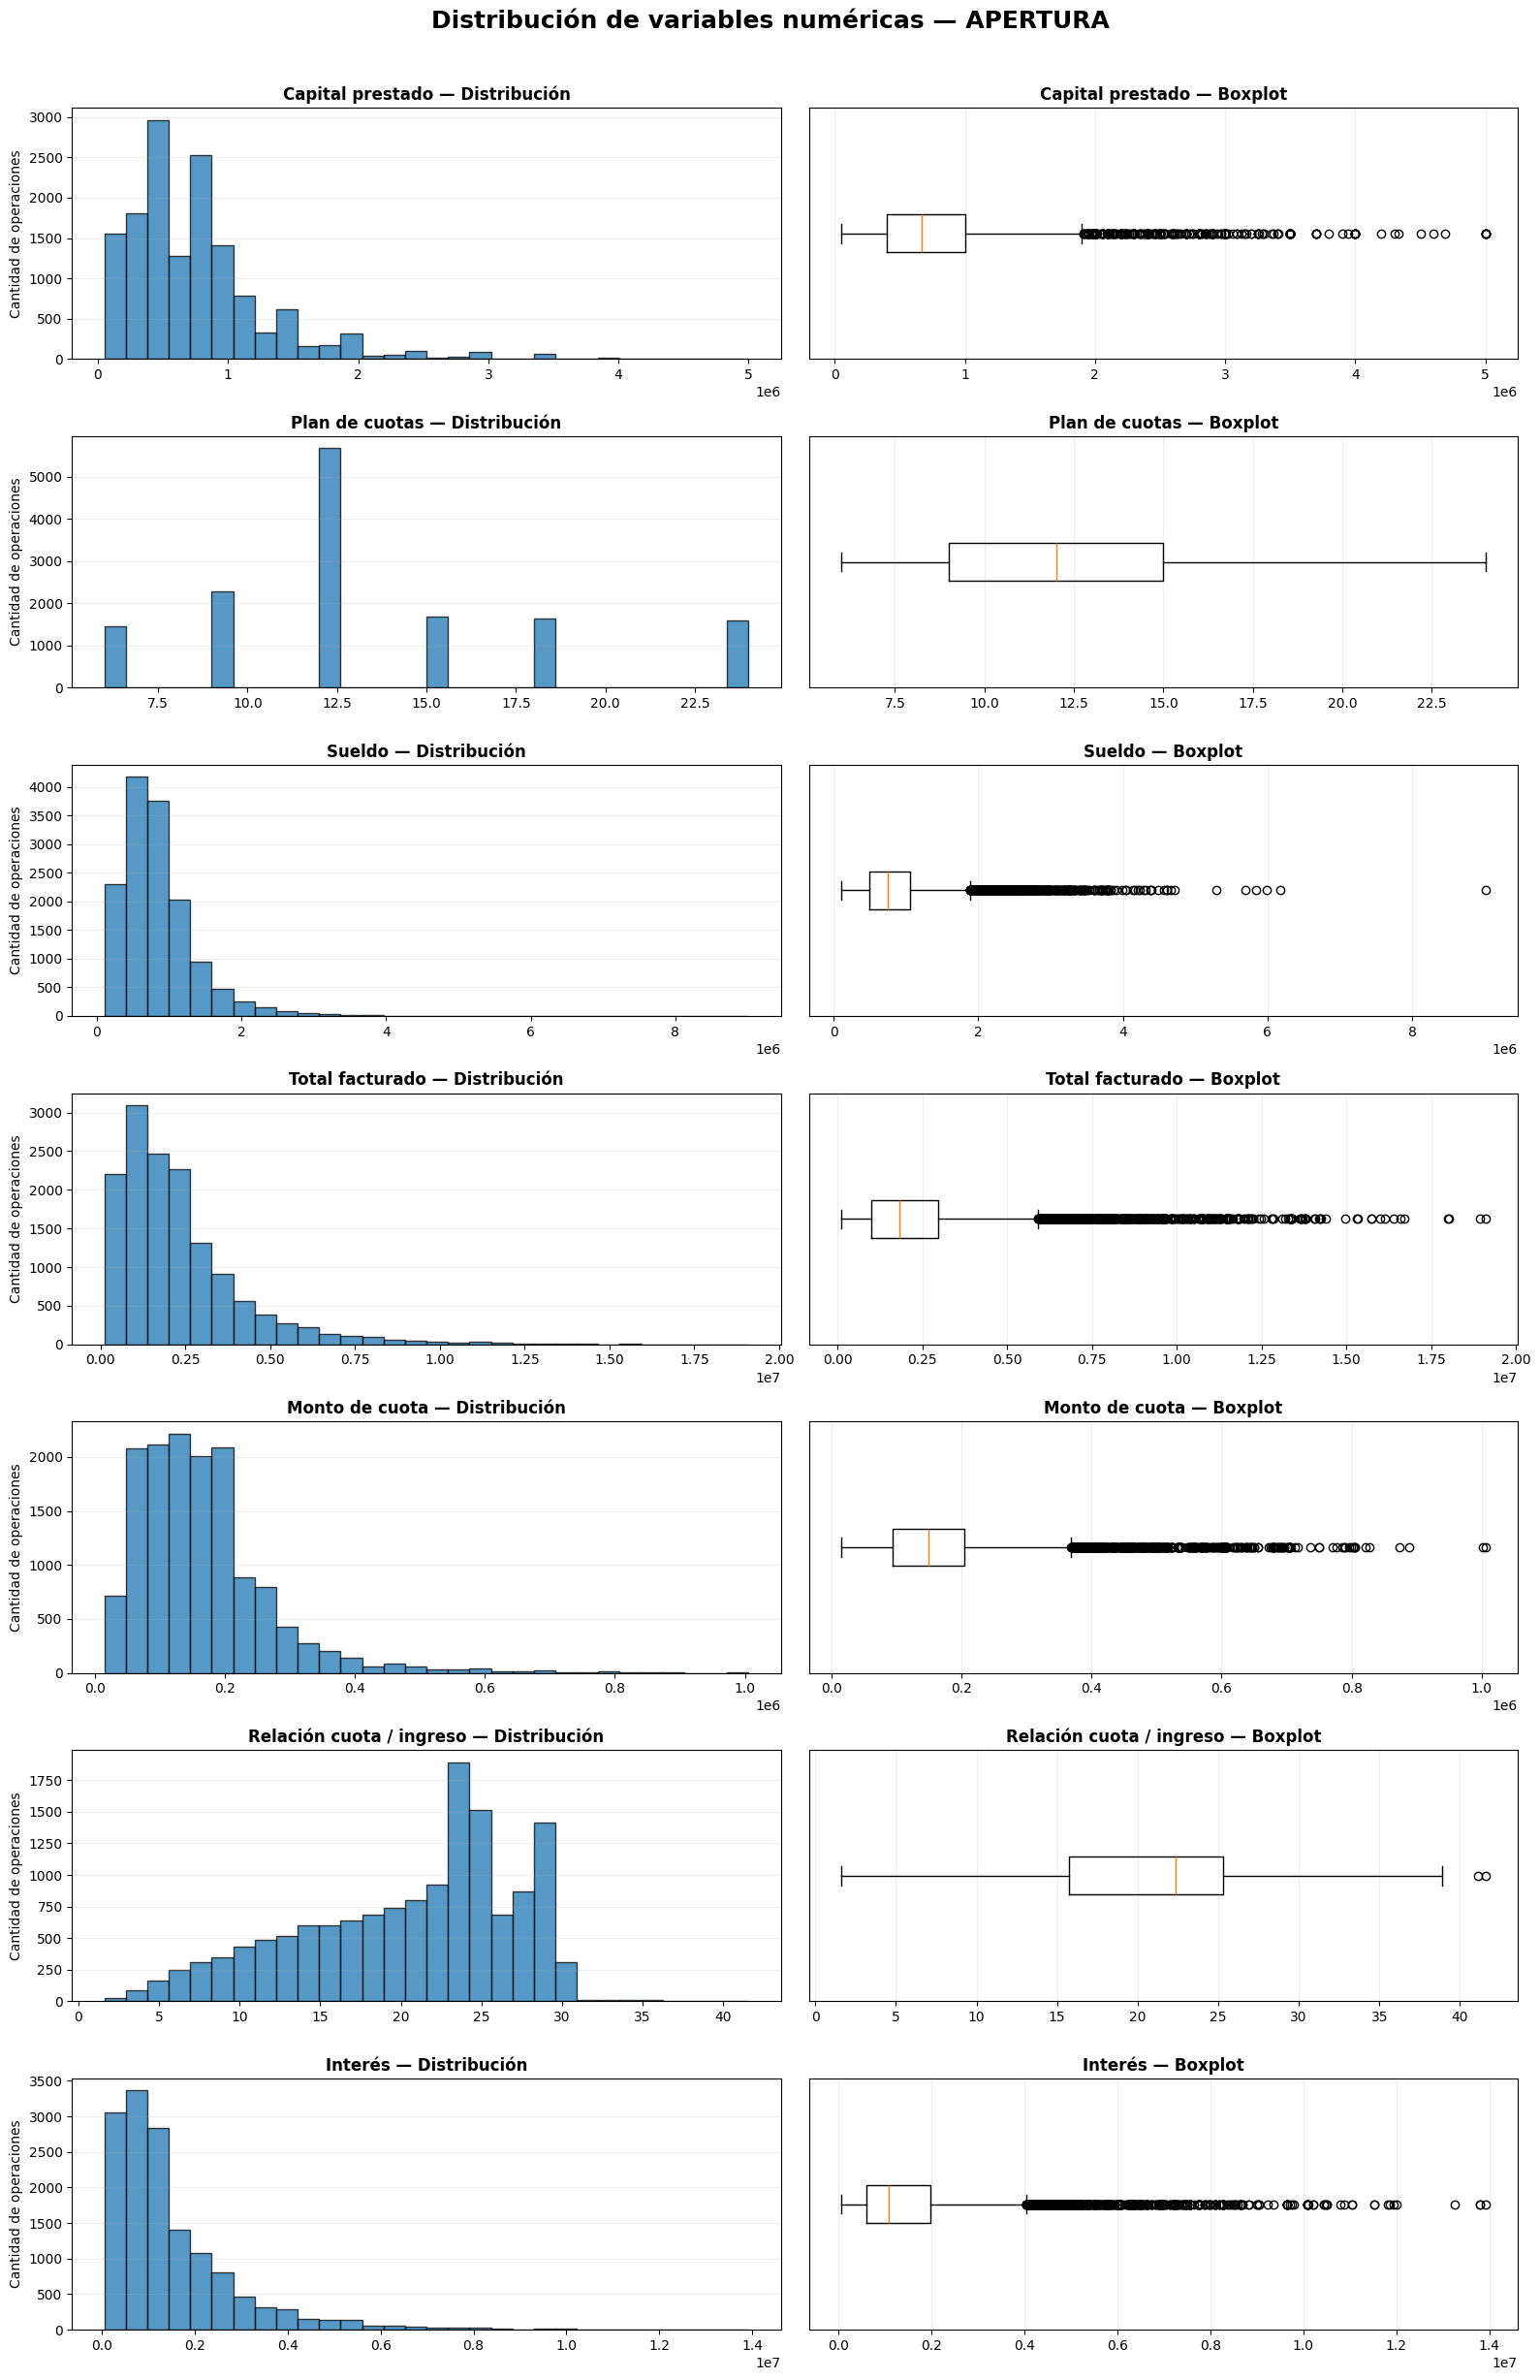

Gráfico guardado en: /content/drive/MyDrive/PROYECTO TESIS/SEMINARIO/GRAFICOS_EDA/distribuciones_apertura_2024_2026.png


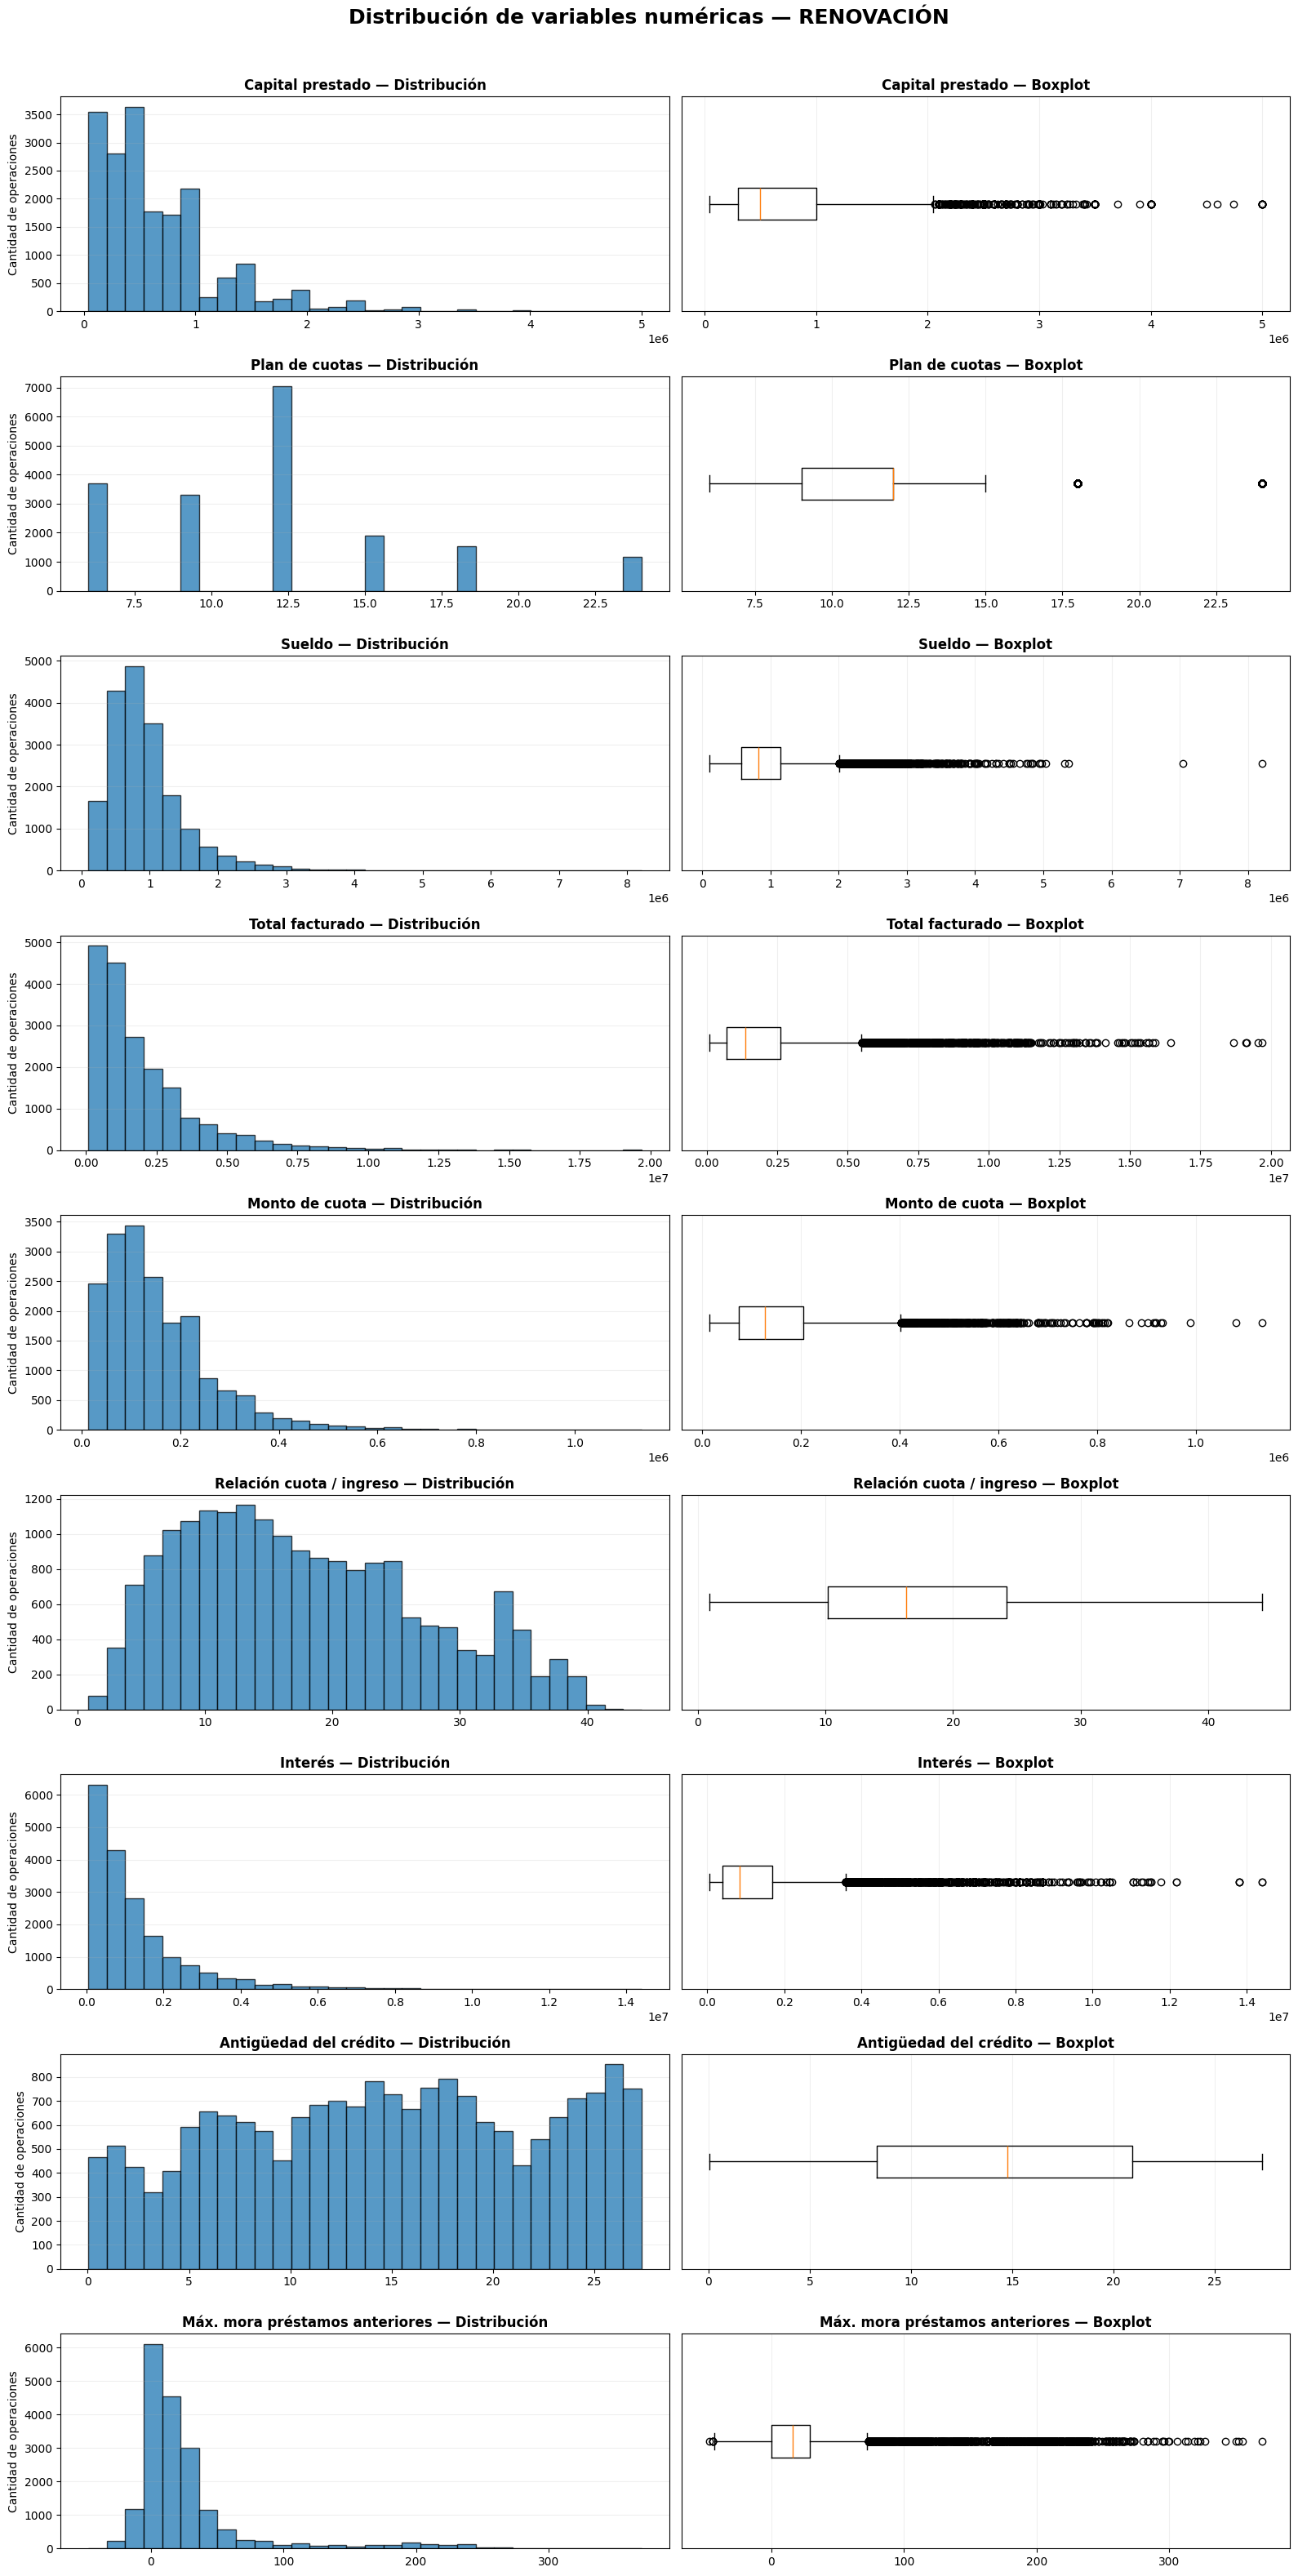

Gráfico guardado en: /content/drive/MyDrive/PROYECTO TESIS/SEMINARIO/GRAFICOS_EDA/distribuciones_renovacion_2024_2026.png


In [ ]:
# ============================================================
# 9. DISTRIBUCIÓN DE LAS PRINCIPALES VARIABLES NUMÉRICAS
# Histogramas y boxplots por tipo de crédito
# Ventana principal: 2024–2026
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pathlib import Path


# ------------------------------------------------------------
# Carpeta para guardar los gráficos
# ------------------------------------------------------------

CARPETA_GRAFICOS = Path(
    "/content/drive/MyDrive/PROYECTO TESIS/SEMINARIO/GRAFICOS_EDA"
)

CARPETA_GRAFICOS.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# Variables de APERTURA
# ------------------------------------------------------------

variables_grafico_apertura = {

    "capitalprestado":
        "Capital prestado",

    "plan":
        "Plan de cuotas",

    "SUELDO":
        "Sueldo",

    "totalfac":
        "Total facturado",

    "monto_cuota":
        "Monto de cuota",

    "relacion_cuota_ingreso":
        "Relación cuota / ingreso",

    "interes":
        "Interés"
}


# ------------------------------------------------------------
# Variables de RENOVACIÓN
# ------------------------------------------------------------

variables_grafico_renovacion = {

    "capitalprestado":
        "Capital prestado",

    "plan":
        "Plan de cuotas",

    "SUELDO":
        "Sueldo",

    "totalfac":
        "Total facturado",

    "monto_cuota":
        "Monto de cuota",

    "relacion_cuota_ingreso":
        "Relación cuota / ingreso",

    "interes":
        "Interés",

    "antiguedad_credito":
        "Antigüedad del crédito",

    "max_mora_prestamos_anteriores":
        "Máx. mora préstamos anteriores"
}


# ============================================================
# FUNCIÓN PARA GENERAR HISTOGRAMA + BOXPLOT
# ============================================================

def graficar_distribuciones(
    base,
    variables,
    tipo_credito,
    nombre_archivo
):

    cantidad_variables = len(variables)

    fig, axes = plt.subplots(
        nrows=cantidad_variables,
        ncols=2,
        figsize=(16, cantidad_variables * 3.5)
    )

    fig.suptitle(
        f"Distribución de variables numéricas — {tipo_credito}",
        fontsize=18,
        fontweight="bold",
        y=1.00
    )


    for fila, (variable, titulo) in enumerate(
        variables.items()
    ):

        serie = (
            pd.to_numeric(
                base[variable],
                errors="coerce"
            )
            .dropna()
        )


        # ----------------------------------------------------
        # HISTOGRAMA
        # ----------------------------------------------------

        ax_hist = axes[fila, 0]

        ax_hist.hist(
            serie,
            bins=30,
            edgecolor="black",
            alpha=0.75
        )

        ax_hist.set_title(
            f"{titulo} — Distribución",
            fontsize=12,
            fontweight="bold"
        )

        ax_hist.set_ylabel(
            "Cantidad de operaciones"
        )

        ax_hist.grid(
            axis="y",
            alpha=0.20
        )


        # ----------------------------------------------------
        # BOXPLOT
        # ----------------------------------------------------

        ax_box = axes[fila, 1]

        ax_box.boxplot(
            serie,
            vert=False,
            showfliers=True
        )

        ax_box.set_title(
            f"{titulo} — Boxplot",
            fontsize=12,
            fontweight="bold"
        )

        ax_box.set_yticks([])

        ax_box.grid(
            axis="x",
            alpha=0.20
        )


    plt.tight_layout(
        rect=[0, 0, 1, 0.99]
    )


    # --------------------------------------------------------
    # Guardar
    # --------------------------------------------------------

    ruta = (
        CARPETA_GRAFICOS
        / nombre_archivo
    )

    plt.savefig(
        ruta,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()

    print(
        f"Gráfico guardado en: {ruta}"
    )


# ============================================================
# APERTURA
# ============================================================

graficar_distribuciones(

    df_apertura,

    variables_grafico_apertura,

    "APERTURA",

    "distribuciones_apertura_2024_2026.png"
)


# ============================================================
# RENOVACIÓN
# ============================================================

graficar_distribuciones(

    df_renovacion,

    variables_grafico_renovacion,

    "RENOVACIÓN",

    "distribuciones_renovacion_2024_2026.png"
)

Las distribuciones muestran que varias variables financieras presentan concentración en determinados rangos y una extensión hacia valores menos frecuentes. Esto es esperable en una cartera real de créditos, donde conviven operaciones de distintos montos, planes, ingresos y características.

Los boxplots permiten identificar estas observaciones de manera visual, pero no se utilizan como criterio automático de eliminación. La decisión de conservar o excluir un registro debe considerar su consistencia y el contexto de la operación.

# 10. Análisis del score crediticio

El score crediticio constituye una de las principales variables disponibles al momento del otorgamiento y representa una referencia previa del nivel de riesgo asociado a cada solicitante.

En esta etapa se analiza su distribución dentro de la cartera y su relación con el resultado posteriormente observado.

El objetivo no es utilizar el score como una regla aislada de clasificación, sino evaluar hasta qué punto sus distintos rangos presentan comportamientos diferentes respecto de la derivación a Gestión Judicial.

## 10.1 Control y agrupación del score

La variable `rscore` se encuentra expresada mediante rangos de score. Para facilitar su análisis se ordenan las operaciones en intervalos de 100 puntos, conservando el orden natural de la variable.

Antes de realizar las comparaciones se controla la cobertura de la variable y la correcta asignación de las operaciones a cada tramo.

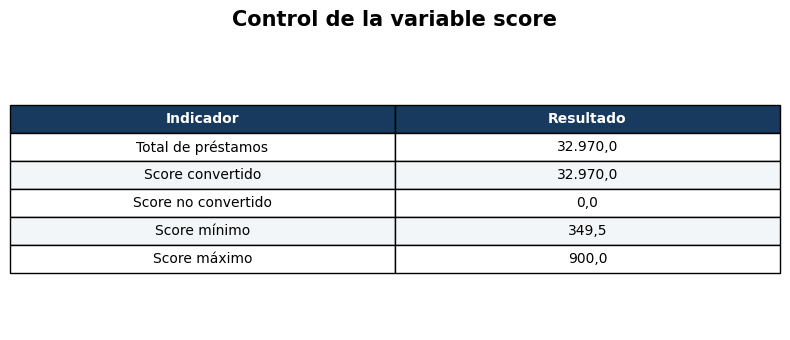

In [ ]:
# ============================================================
# 10.1 CONTROL Y AGRUPACIÓN DEL SCORE
# ============================================================

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Función para convertir el score
# ------------------------------------------------------------

def convertir_score(valor):

    if pd.isna(valor):
        return np.nan

    # Si ya viene numérico
    if isinstance(valor, (int, float, np.integer, np.floating)):
        return float(valor)

    texto = str(valor).strip()

    numeros = re.findall(r"\d+", texto)

    # Si es un rango, utilizar punto medio
    # Ejemplo: 400-499 -> 449,5
    if len(numeros) >= 2:

        inferior = float(numeros[0])
        superior = float(numeros[1])

        return (inferior + superior) / 2

    # Si posee un único valor
    if len(numeros) == 1:
        return float(numeros[0])

    return np.nan


# ------------------------------------------------------------
# 2. Crear score numérico
# ------------------------------------------------------------

df_2024_2026["score_numerico"] = (
    df_2024_2026["rscore"]
    .apply(convertir_score)
)


# ------------------------------------------------------------
# 3. Crear tramos de score
# ------------------------------------------------------------

limites_score = [
    -np.inf,
    299,
    399,
    499,
    599,
    699,
    799,
    899,
    np.inf
]

etiquetas_score = [
    "Hasta 299",
    "300–399",
    "400–499",
    "500–599",
    "600–699",
    "700–799",
    "800–899",
    "900 o más"
]


df_2024_2026["tramo_score_100"] = pd.cut(
    df_2024_2026["score_numerico"],
    bins=limites_score,
    labels=etiquetas_score,
    include_lowest=True,
    ordered=True
)


# ------------------------------------------------------------
# 4. Tabla de control
# ------------------------------------------------------------

tabla_control_score = pd.DataFrame({

    "Indicador": [
        "Total de préstamos",
        "Score convertido",
        "Score no convertido",
        "Score mínimo",
        "Score máximo"
    ],

    "Resultado": [
        len(df_2024_2026),
        df_2024_2026["score_numerico"].notna().sum(),
        df_2024_2026["score_numerico"].isna().sum(),
        df_2024_2026["score_numerico"].min(),
        df_2024_2026["score_numerico"].max()
    ]
})


# ------------------------------------------------------------
# 5. Mostrar tabla como imagen
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 3.5))

ax.axis("off")

tabla_mostrar = tabla_control_score.copy()

tabla_mostrar["Resultado"] = tabla_mostrar["Resultado"].apply(
    lambda x: f"{x:,.1f}".replace(",", "X").replace(".", ",").replace("X", ".")
)

tabla = ax.table(
    cellText=tabla_mostrar.values,
    colLabels=tabla_mostrar.columns,
    cellLoc="center",
    colLoc="center",
    loc="center"
)

tabla.auto_set_font_size(False)
tabla.set_fontsize(10)
tabla.scale(1, 1.6)

# Encabezado
for j in range(len(tabla_mostrar.columns)):

    tabla[(0, j)].set_facecolor("#173A5E")
    tabla[(0, j)].set_text_props(
        color="white",
        weight="bold"
    )

# Filas
for i in range(1, len(tabla_mostrar) + 1):

    color = "#F3F6F8" if i % 2 == 0 else "white"

    for j in range(len(tabla_mostrar.columns)):

        tabla[(i, j)].set_facecolor(color)


ax.set_title(
    "Control de la variable score",
    fontsize=15,
    fontweight="bold",
    pad=16
)

plt.tight_layout()
plt.show()

## 10.2 Distribución de la cartera por tramo de score

Acá usamos toda la cartera 2024–2026, incluidos los activos.

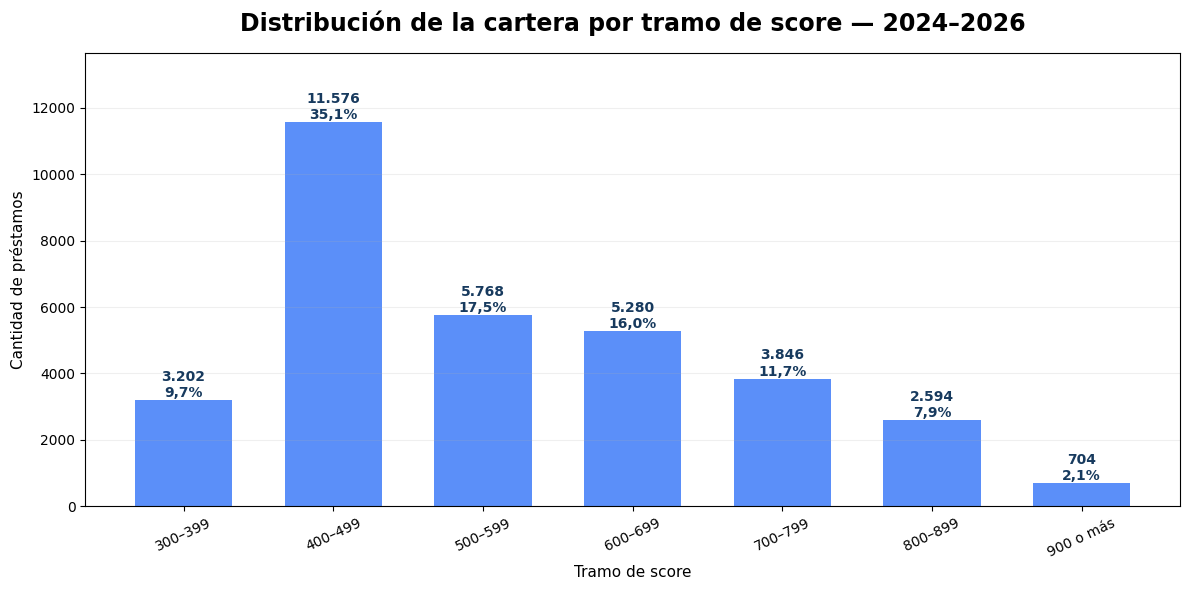

In [ ]:
# ============================================================
# 10.2 DISTRIBUCIÓN DE LA CARTERA POR TRAMO DE SCORE
# ============================================================

tabla_distribucion_score = (
    df_2024_2026
    .groupby(
        "tramo_score_100",
        observed=False
    )
    .size()
    .reset_index(name="Cantidad")
)


tabla_distribucion_score["Porcentaje"] = (
    tabla_distribucion_score["Cantidad"]
    / tabla_distribucion_score["Cantidad"].sum()
    * 100
)


# Quitar tramos sin casos
tabla_distribucion_score = (
    tabla_distribucion_score[
        tabla_distribucion_score["Cantidad"] > 0
    ]
    .copy()
)


# ------------------------------------------------------------
# Gráfico
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(12, 6)
)

barras = ax.bar(
    tabla_distribucion_score["tramo_score_100"].astype(str),
    tabla_distribucion_score["Cantidad"],
    width=0.65,
    color="#5B8FF9"
)


# ------------------------------------------------------------
# Etiquetas cantidad + porcentaje
# ------------------------------------------------------------

for barra, cantidad, porcentaje in zip(
    barras,
    tabla_distribucion_score["Cantidad"],
    tabla_distribucion_score["Porcentaje"]
):

    etiqueta = (
        f"{cantidad:,.0f}".replace(",", ".")
        + "\n"
        + f"{porcentaje:.1f}%".replace(".", ",")
    )

    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        etiqueta,
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color="#173A5E"
    )


# ------------------------------------------------------------
# Formato
# ------------------------------------------------------------

ax.set_title(
    "Distribución de la cartera por tramo de score — 2024–2026",
    fontsize=17,
    fontweight="bold",
    pad=16
)

ax.set_xlabel(
    "Tramo de score",
    fontsize=11
)

ax.set_ylabel(
    "Cantidad de préstamos",
    fontsize=11
)

ax.grid(
    axis="y",
    alpha=0.20
)

plt.xticks(
    rotation=25
)

maximo = tabla_distribucion_score["Cantidad"].max()

ax.set_ylim(
    0,
    maximo * 1.18
)

plt.tight_layout()


# ------------------------------------------------------------
# Guardar
# ------------------------------------------------------------

ruta_score_distribucion = (
    CARPETA
    / "distribucion_cartera_por_score_2024_2026.png"
)

plt.savefig(
    ruta_score_distribucion,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

## 10.3 Judicialización por tramo de score

Acá sí sacamos los activos, porque necesitamos comparar únicamente operaciones con resultado definitivo.

Primero armamos No Judicial / Judicial por score y después mostramos la tasa judicial.

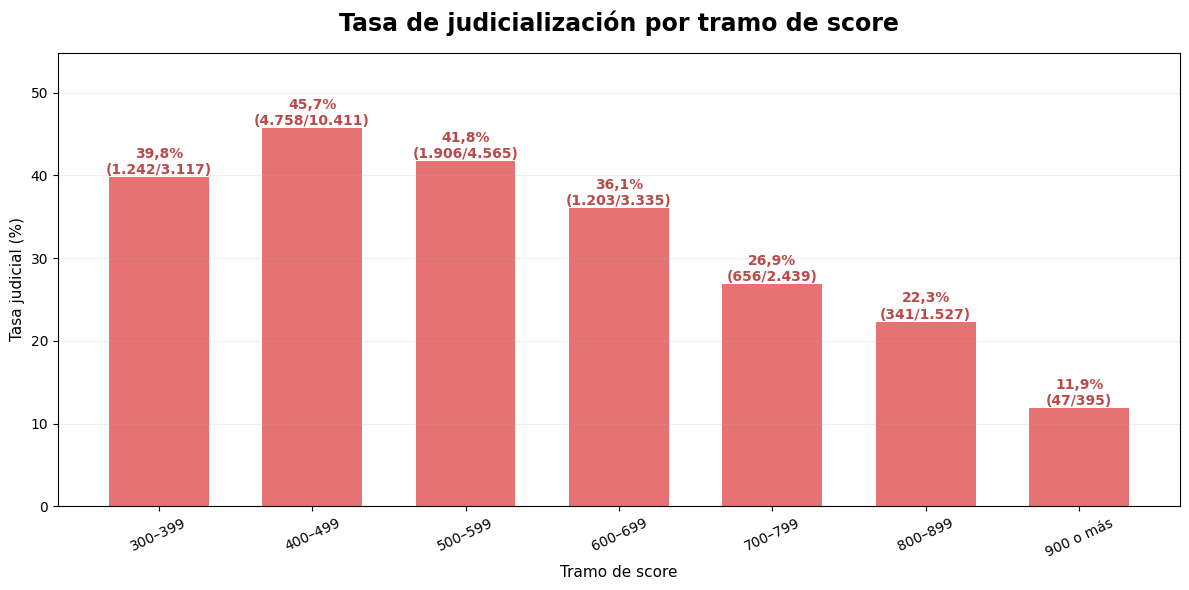

In [ ]:
# ============================================================
# 10.3 JUDICIALIZACIÓN POR TRAMO DE SCORE
# ============================================================

# ------------------------------------------------------------
# 1. Solo operaciones con resultado definitivo
# ------------------------------------------------------------

df_score_resultado = (
    df_2024_2026[
        df_2024_2026["judicial_bin"].notna()
    ]
    .copy()
)

df_score_resultado["judicial_bin"] = (
    df_score_resultado["judicial_bin"].astype(int)
)


# ------------------------------------------------------------
# 2. Resumen por tramo
# ------------------------------------------------------------

tabla_score_judicial = (
    df_score_resultado
    .groupby(
        "tramo_score_100",
        observed=False
    )
    .agg(
        Prestamos=("factura", "count"),
        Judiciales=("judicial_bin", "sum")
    )
    .reset_index()
)


tabla_score_judicial["No Judiciales"] = (
    tabla_score_judicial["Prestamos"]
    - tabla_score_judicial["Judiciales"]
)


tabla_score_judicial["Tasa judicial"] = np.where(

    tabla_score_judicial["Prestamos"] > 0,

    tabla_score_judicial["Judiciales"]
    / tabla_score_judicial["Prestamos"]
    * 100,

    np.nan
)


# eliminar tramos sin préstamos
tabla_score_judicial = (
    tabla_score_judicial[
        tabla_score_judicial["Prestamos"] > 0
    ]
    .copy()
)


# ------------------------------------------------------------
# 3. Gráfico tasa judicial
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(12, 6)
)

barras = ax.bar(
    tabla_score_judicial["tramo_score_100"].astype(str),
    tabla_score_judicial["Tasa judicial"],
    width=0.65,
    color="#E57373"
)


# ------------------------------------------------------------
# Etiquetas
# ------------------------------------------------------------

for barra, tasa, judiciales, total in zip(

    barras,

    tabla_score_judicial["Tasa judicial"],

    tabla_score_judicial["Judiciales"],

    tabla_score_judicial["Prestamos"]
):

    etiqueta = (
        f"{tasa:.1f}%".replace(".", ",")
        + "\n"
        + f"({int(judiciales):,}/{int(total):,})".replace(",", ".")
    )

    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        etiqueta,
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color="#B94A48"
    )


# ------------------------------------------------------------
# Formato
# ------------------------------------------------------------

ax.set_title(
    "Tasa de judicialización por tramo de score",
    fontsize=17,
    fontweight="bold",
    pad=16
)

ax.set_xlabel(
    "Tramo de score",
    fontsize=11
)

ax.set_ylabel(
    "Tasa judicial (%)",
    fontsize=11
)

ax.grid(
    axis="y",
    alpha=0.20
)

plt.xticks(
    rotation=25
)

maximo = tabla_score_judicial["Tasa judicial"].max()

ax.set_ylim(
    0,
    maximo * 1.20
)

plt.tight_layout()


# ------------------------------------------------------------
# Guardar
# ------------------------------------------------------------

ruta_score_judicial = (
    CARPETA
    / "tasa_judicial_por_score.png"
)

plt.savefig(
    ruta_score_judicial,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# 11. Comparación entre Apertura y Renovación

Las operaciones de **Apertura** y **Renovación** representan situaciones diferentes dentro de la cartera.

Las Aperturas corresponden a primeras operaciones, mientras que las Renovaciones pertenecen a clientes que ya cuentan con antecedentes dentro de la entidad. Esta diferencia también implica una disponibilidad distinta de información al momento del otorgamiento.

Para analizar el comportamiento observado de ambas poblaciones se consideran las operaciones de **2024–2025 con resultado definitivo**, excluyendo los préstamos que permanecen activos.

Se compara la cantidad de operaciones Judiciales y No Judiciales y la tasa de judicialización correspondiente a cada tipo de crédito.

In [ ]:
# ============================================================
# 11. APERTURA VS RENOVACIÓN
# Población histórica 2024–2025 con resultado definitivo
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Población histórica
# ------------------------------------------------------------

df_tipo_resultado = (
    df_2024_2026[
        (df_2024_2026["añofac"].isin([2024, 2025]))
        &
        (df_2024_2026["judicial_bin"].notna())
    ]
    .copy()
)

df_tipo_resultado["judicial_bin"] = (
    df_tipo_resultado["judicial_bin"].astype(int)
)


# ------------------------------------------------------------
# 2. Normalizar tipo de crédito
# ------------------------------------------------------------

df_tipo_resultado["tipo_credito_eda"] = (
    df_tipo_resultado["tipocredito"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Control
print(
    df_tipo_resultado["tipo_credito_eda"]
    .value_counts(dropna=False)
)


# ------------------------------------------------------------
# 3. Resumen
# ------------------------------------------------------------

tabla_tipo = (
    df_tipo_resultado
    .groupby("tipo_credito_eda")
    .agg(
        Prestamos=("factura", "count"),
        Judiciales=("judicial_bin", "sum")
    )
    .reset_index()
)

tabla_tipo["No Judiciales"] = (
    tabla_tipo["Prestamos"]
    - tabla_tipo["Judiciales"]
)

tabla_tipo["Tasa judicial"] = (
    tabla_tipo["Judiciales"]
    / tabla_tipo["Prestamos"]
    * 100
)

# Orden
orden = ["APERTURA", "RENOVACION"]

tabla_tipo["tipo_credito_eda"] = pd.Categorical(
    tabla_tipo["tipo_credito_eda"],
    categories=orden,
    ordered=True
)

tabla_tipo = (
    tabla_tipo
    .sort_values("tipo_credito_eda")
    .reset_index(drop=True)
)

display(tabla_tipo)

tipo_credito_eda
RENOVACION    14497
APERTURA      10797
Name: count, dtype: int64


,tipo_credito_eda,Prestamos,Judiciales,No Judiciales,Tasa judicial
0,APERTURA,10797,6062,4735,56.145226
1,RENOVACION,14497,3775,10722,26.039870


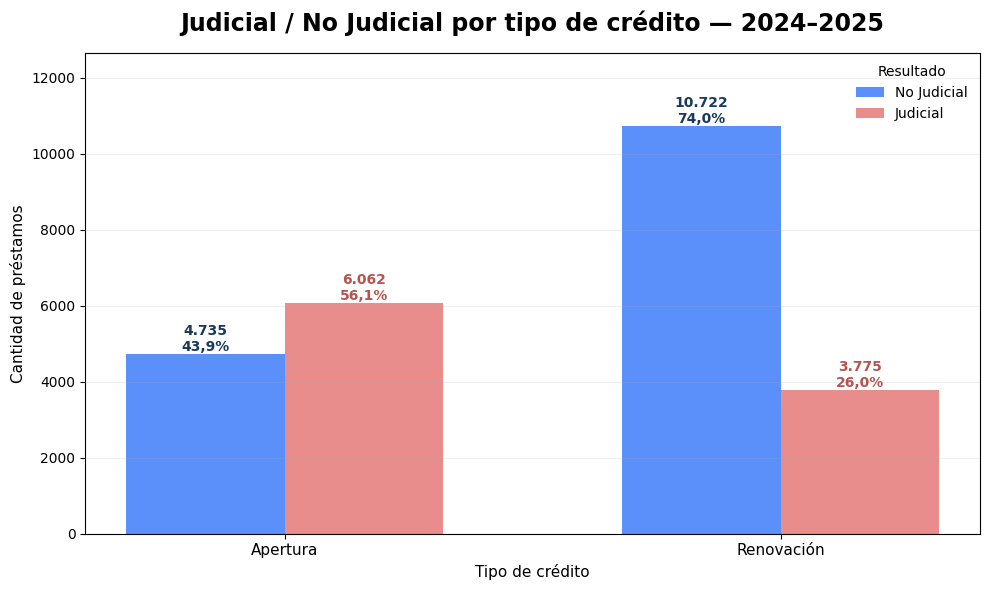

In [ ]:
# ============================================================
# GRÁFICO — JUDICIAL / NO JUDICIAL POR TIPO DE CRÉDITO
# ============================================================

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(tabla_tipo))
ancho = 0.32


# No Judicial
barras_no = ax.bar(
    x - ancho / 2,
    tabla_tipo["No Judiciales"],
    width=ancho,
    label="No Judicial",
    color="#5B8FF9"
)


# Judicial
barras_jud = ax.bar(
    x + ancho / 2,
    tabla_tipo["Judiciales"],
    width=ancho,
    label="Judicial",
    color="#E88C8C"
)


# ------------------------------------------------------------
# Porcentajes
# ------------------------------------------------------------

pct_no = (
    tabla_tipo["No Judiciales"]
    / tabla_tipo["Prestamos"]
    * 100
)

pct_jud = tabla_tipo["Tasa judicial"]


# ------------------------------------------------------------
# Etiquetas No Judicial
# ------------------------------------------------------------

for barra, cantidad, porcentaje in zip(
    barras_no,
    tabla_tipo["No Judiciales"],
    pct_no
):

    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        (
            f"{int(cantidad):,}".replace(",", ".")
            + "\n"
            + f"{porcentaje:.1f}%".replace(".", ",")
        ),
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color="#173A5E"
    )


# ------------------------------------------------------------
# Etiquetas Judicial
# ------------------------------------------------------------

for barra, cantidad, porcentaje in zip(
    barras_jud,
    tabla_tipo["Judiciales"],
    pct_jud
):

    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        (
            f"{int(cantidad):,}".replace(",", ".")
            + "\n"
            + f"{porcentaje:.1f}%".replace(".", ",")
        ),
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color="#B85450"
    )


# ------------------------------------------------------------
# Formato
# ------------------------------------------------------------

ax.set_title(
    "Judicial / No Judicial por tipo de crédito — 2024–2025",
    fontsize=17,
    fontweight="bold",
    pad=16
)

ax.set_xlabel(
    "Tipo de crédito",
    fontsize=11
)

ax.set_ylabel(
    "Cantidad de préstamos",
    fontsize=11
)

ax.set_xticks(x)

ax.set_xticklabels(
    ["Apertura", "Renovación"],
    fontsize=11
)

ax.legend(
    title="Resultado",
    frameon=False
)

ax.grid(
    axis="y",
    alpha=0.20
)

maximo = max(
    tabla_tipo["No Judiciales"].max(),
    tabla_tipo["Judiciales"].max()
)

ax.set_ylim(
    0,
    maximo * 1.18
)

plt.tight_layout()


# ------------------------------------------------------------
# Guardar
# ------------------------------------------------------------

ruta_tipo_credito = (
    CARPETA
    / "judicial_no_judicial_apertura_renovacion.png"
)

plt.savefig(
    ruta_tipo_credito,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

### Interpretación

La comparación evidencia diferencias importantes entre las dos poblaciones.

En **Apertura**, la participación de operaciones Judiciales es considerablemente mayor que en Renovación. En cambio, en **Renovación** predominan las operaciones No Judiciales.

Esta diferencia confirma que ambas poblaciones presentan comportamientos distintos respecto del resultado estudiado. Además, las Renovaciones disponen de antecedentes internos del cliente que no existen en las Aperturas.

Por estos motivos, en las etapas posteriores del trabajo las operaciones de Apertura y Renovación serán analizadas y modeladas de manera separada.

# 12. Segmentación de la judicialización

Luego de analizar el score y las diferencias entre Apertura y Renovación, se estudia cómo se distribuye la judicialización entre distintos segmentos de la cartera.

Para esta etapa se consideran las operaciones correspondientes a **2024–2025 con resultado definitivo**, utilizando únicamente los préstamos clasificados como Judiciales o No Judiciales.

Se analizan las siguientes variables:

- Actividad
- Provincia
- Rango de edad
- Género
- Plan de cuotas
- Sucursal

Para cada segmento se calcula la cantidad de préstamos, la cantidad de operaciones judiciales y la correspondiente **tasa de judicialización**.

**Tasa judicial = Judiciales / Total de operaciones con resultado definitivo × 100**

El objetivo de este análisis es identificar diferencias descriptivas entre los distintos grupos de la cartera, sin interpretar estas relaciones de manera aislada como causas de judicialización.

In [ ]:
# ============================================================
# 12. SEGMENTACIÓN DE LA JUDICIALIZACIÓN
# Base histórica 2024–2025 con resultado definitivo
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Base
# ------------------------------------------------------------

df_segmentos = (
    df_2024_2026[
        (df_2024_2026["añofac"].isin([2024, 2025]))
        &
        (df_2024_2026["judicial_bin"].notna())
    ]
    .copy()
)

df_segmentos["judicial_bin"] = (
    df_segmentos["judicial_bin"].astype(int)
)


# ------------------------------------------------------------
# 2. Función general
# ------------------------------------------------------------

def analizar_segmento(
    base,
    variable,
    titulo,
    top_n=None,
    horizontal=False
):

    resumen = (
        base
        .groupby(variable, dropna=False, observed=False)
        .agg(
            Prestamos=("factura", "count"),
            Judiciales=("judicial_bin", "sum")
        )
        .reset_index()
    )

    resumen["No Judiciales"] = (
        resumen["Prestamos"]
        - resumen["Judiciales"]
    )

    resumen["Tasa judicial"] = (
        resumen["Judiciales"]
        / resumen["Prestamos"]
        * 100
    )

    # Quitar categorías sin operaciones
    resumen = resumen[
        resumen["Prestamos"] > 0
    ].copy()

    # Si hay muchas categorías, mostrar las de mayor volumen
    if top_n is not None:
        resumen = (
            resumen
            .sort_values(
                "Prestamos",
                ascending=False
            )
            .head(top_n)
        )

    # Para gráfico: ordenar por tasa
    resumen_grafico = (
        resumen
        .sort_values(
            "Tasa judicial",
            ascending=True if horizontal else False
        )
        .copy()
    )


    # --------------------------------------------------------
    # GRÁFICO
    # --------------------------------------------------------

    if horizontal:

        alto = max(
            5,
            len(resumen_grafico) * 0.42
        )

        fig, ax = plt.subplots(
            figsize=(11, alto)
        )

        barras = ax.barh(
            resumen_grafico[variable].astype(str),
            resumen_grafico["Tasa judicial"],
            color="#E88C8C"
        )

        for barra, tasa, judiciales, total in zip(
            barras,
            resumen_grafico["Tasa judicial"],
            resumen_grafico["Judiciales"],
            resumen_grafico["Prestamos"]
        ):

            ax.text(
                barra.get_width(),
                barra.get_y() + barra.get_height()/2,
                (
                    f"  {tasa:.1f}%".replace(".", ",")
                    + f"  ({int(judiciales):,}/{int(total):,})"
                    .replace(",", ".")
                ),
                va="center",
                fontsize=9,
                fontweight="bold",
                color="#B85450"
            )

        ax.set_xlabel(
            "Tasa judicial (%)"
        )

        ax.set_ylabel("")

        maximo = resumen_grafico[
            "Tasa judicial"
        ].max()

        ax.set_xlim(
            0,
            maximo * 1.28
        )

        ax.grid(
            axis="x",
            alpha=0.20
        )


    else:

        fig, ax = plt.subplots(
            figsize=(11, 6)
        )

        barras = ax.bar(
            resumen_grafico[variable].astype(str),
            resumen_grafico["Tasa judicial"],
            width=0.65,
            color="#E88C8C"
        )

        for barra, tasa, judiciales, total in zip(
            barras,
            resumen_grafico["Tasa judicial"],
            resumen_grafico["Judiciales"],
            resumen_grafico["Prestamos"]
        ):

            ax.text(
                barra.get_x()
                + barra.get_width()/2,
                barra.get_height(),
                (
                    f"{tasa:.1f}%".replace(".", ",")
                    + "\n"
                    + f"{int(judiciales):,}/{int(total):,}"
                    .replace(",", ".")
                ),
                ha="center",
                va="bottom",
                fontsize=9,
                fontweight="bold",
                color="#B85450"
            )

        ax.set_xlabel("")
        ax.set_ylabel(
            "Tasa judicial (%)"
        )

        maximo = resumen_grafico[
            "Tasa judicial"
        ].max()

        ax.set_ylim(
            0,
            maximo * 1.20
        )

        ax.grid(
            axis="y",
            alpha=0.20
        )

        plt.xticks(
            rotation=25,
            ha="right"
        )


    ax.set_title(
        titulo,
        fontsize=16,
        fontweight="bold",
        pad=16
    )

    plt.tight_layout()
    plt.show()

    return resumen

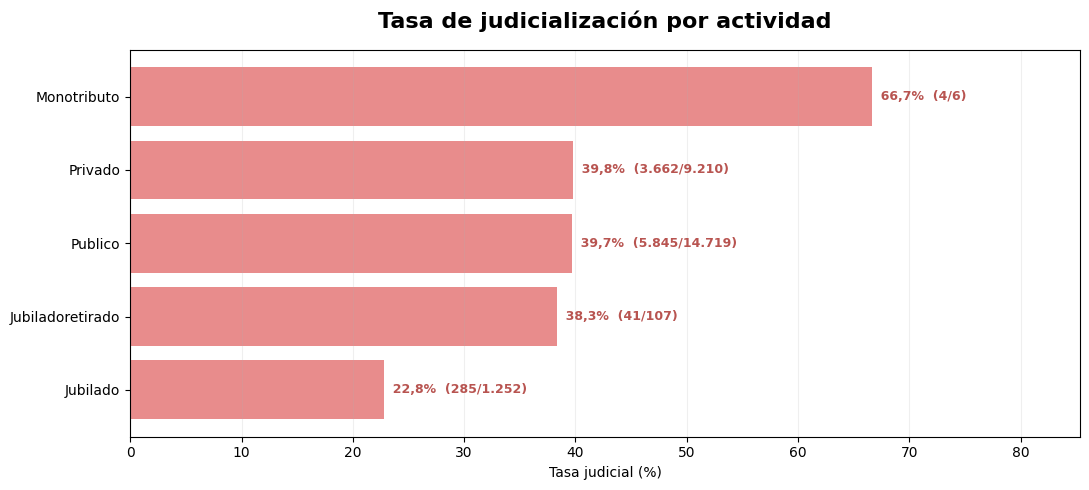

In [ ]:
tabla_actividad = analizar_segmento(
    df_segmentos,
    variable="actividad",
    titulo="Tasa de judicialización por actividad",
    top_n=12,
    horizontal=True
)

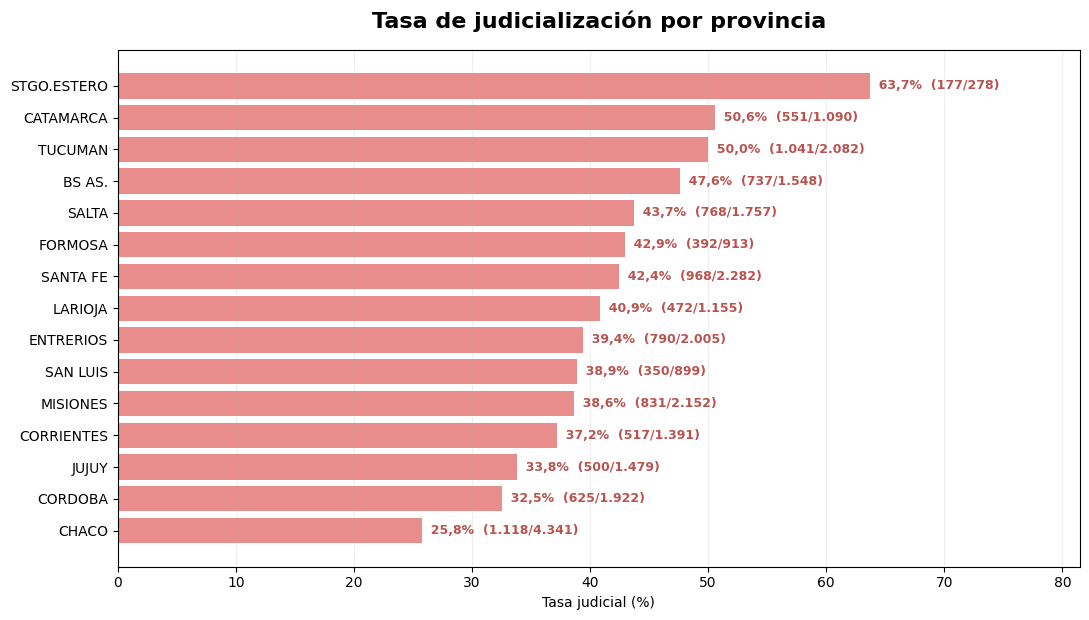

In [ ]:
tabla_provincia = analizar_segmento(
    df_segmentos,
    variable="provincia",
    titulo="Tasa de judicialización por provincia",
    top_n=None,
    horizontal=True
)

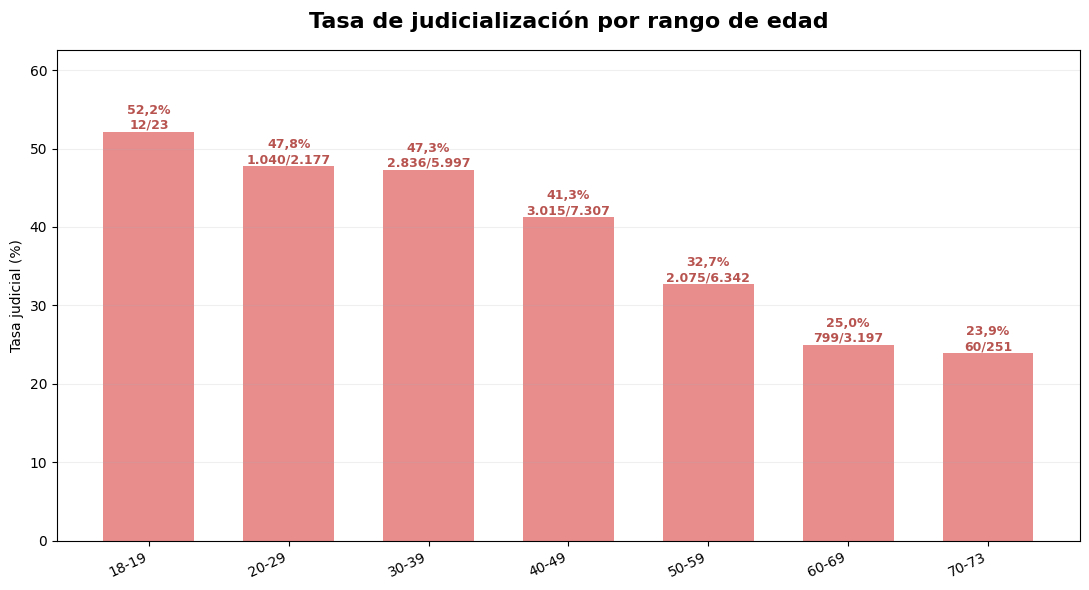

In [ ]:
tabla_edad = analizar_segmento(
    df_segmentos,
    variable="rangoedad",
    titulo="Tasa de judicialización por rango de edad",
    top_n=None,
    horizontal=False
)

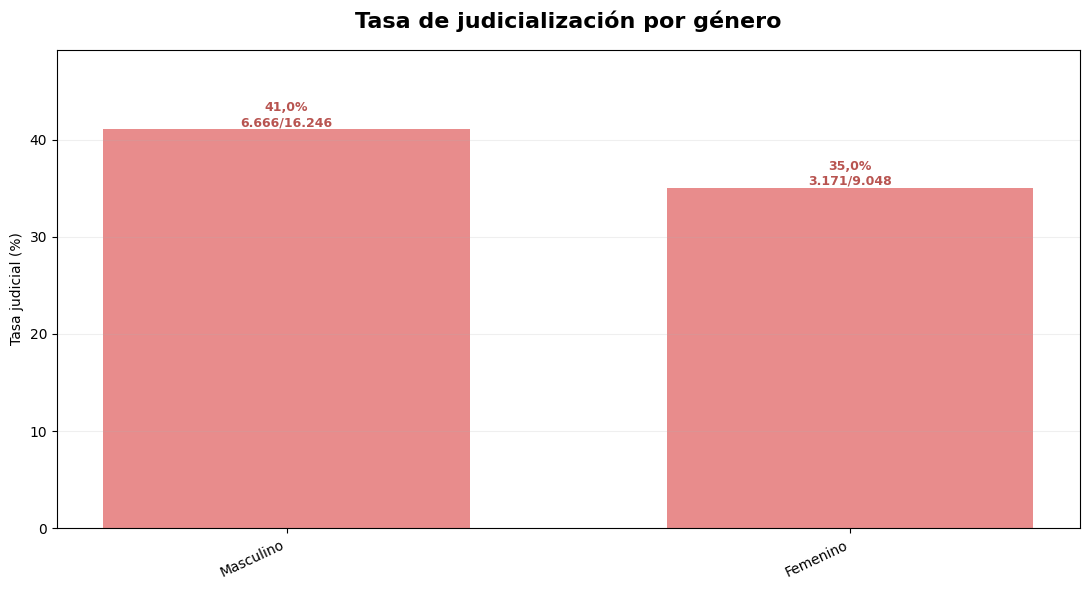

In [ ]:
# GÉNERO
df_segmentos["genero_descripcion"] = (
    pd.to_numeric(df_segmentos["genero"], errors="coerce")
    .map({0: "Masculino", 1: "Femenino"})
    .fillna("Sin dato")
)

tabla_genero = analizar_segmento(
    df_segmentos,
    variable="genero_descripcion",
    titulo="Tasa de judicialización por género",
    top_n=None,
    horizontal=False,
)


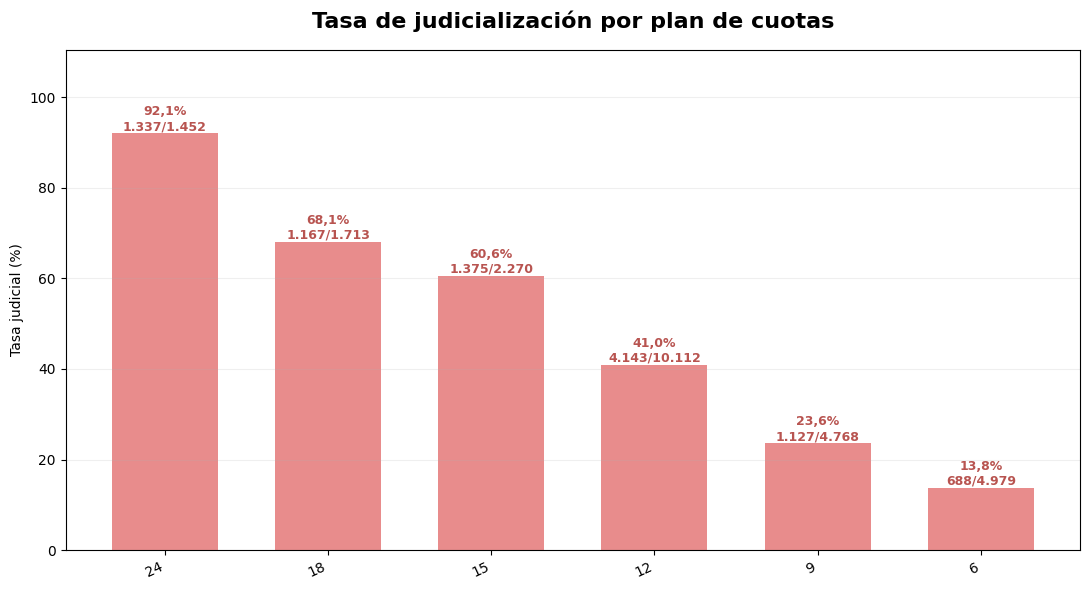

In [ ]:
tabla_plan = analizar_segmento(
    df_segmentos,
    variable="plan",
    titulo="Tasa de judicialización por plan de cuotas",
    top_n=None,
    horizontal=False
)

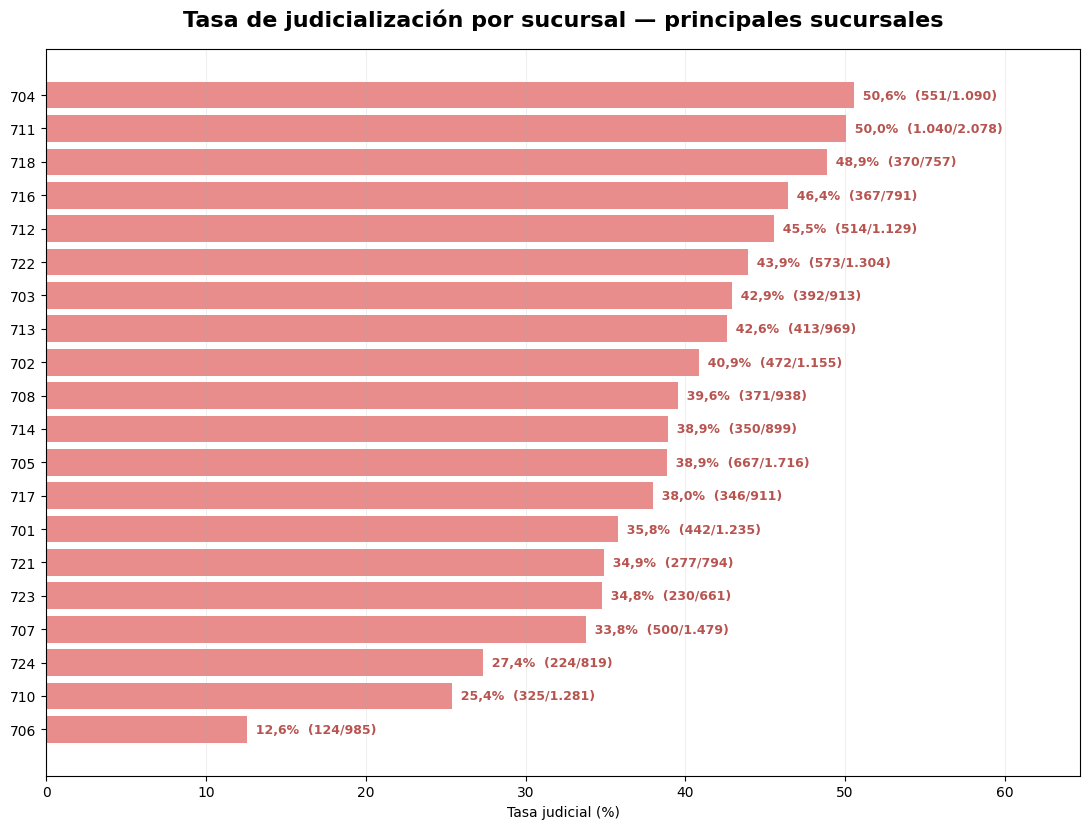

In [ ]:
tabla_sucursal = analizar_segmento(
    df_segmentos,
    variable="sucursal",
    titulo="Tasa de judicialización por sucursal — principales sucursales",
    top_n=20,
    horizontal=True
)

### Interpretación

Las segmentaciones muestran que la tasa de judicialización no es homogénea entre los distintos grupos de la cartera.

Se observan diferencias entre actividades, provincias, rangos de edad, género, planes de cuotas y sucursales. Sin embargo, estas diferencias deben interpretarse de manera descriptiva, ya que cada segmento puede estar compuesto por operaciones con características distintas en términos de score, monto, tipo de crédito y demás variables.

Por este motivo, ninguna de estas variables se utiliza como una regla aislada de riesgo. En el modelado posterior serán consideradas conjuntamente con el resto de la información disponible al momento del otorgamiento.

# 13. Relación cuota-ingreso y judicialización

La relación cuota-ingreso construida previamente permite aproximar el esfuerzo financiero inicial asumido en cada operación, expresando qué proporción del ingreso mensual informado representa el valor de la cuota.

En esta etapa se analiza su relación con el resultado posteriormente observado, utilizando las operaciones de **2024–2025 con resultado definitivo**.

Para facilitar la interpretación, la variable se agrupa en los siguientes rangos:

- Hasta 20 %
- Más de 20 % a 30 %
- Más de 30 % a 35 %
- Más de 35 % a 40 %
- Más de 40 %

Para cada rango se calcula la cantidad de préstamos, la cantidad de operaciones judiciales y la tasa de judicialización.

Posteriormente se realiza la misma comparación separando las operaciones de **Apertura** y **Renovación**.

## 13.1 Judicialización según relación cuota-ingreso

In [ ]:
# ============================================================
# 13.1 RELACIÓN CUOTA-INGRESO Y JUDICIALIZACIÓN
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Base histórica 2024-2025 con resultado definitivo
# ------------------------------------------------------------

df_ratio = (
    df_2024_2026[
        (df_2024_2026["añofac"].isin([2024, 2025]))
        &
        (df_2024_2026["judicial_bin"].notna())
    ]
    .copy()
)

df_ratio["judicial_bin"] = (
    df_ratio["judicial_bin"].astype(int)
)


# ------------------------------------------------------------
# Rangos de relación cuota-ingreso
# ------------------------------------------------------------

limites_ratio = [
    -np.inf,
    20,
    30,
    35,
    40,
    np.inf
]

etiquetas_ratio = [
    "Hasta 20%",
    "Más de 20% a 30%",
    "Más de 30% a 35%",
    "Más de 35% a 40%",
    "Más de 40%"
]


df_ratio["rango_cuota_ingreso"] = pd.cut(
    df_ratio["relacion_cuota_ingreso"],
    bins=limites_ratio,
    labels=etiquetas_ratio,
    include_lowest=True,
    ordered=True
)


# ------------------------------------------------------------
# Resumen
# ------------------------------------------------------------

tabla_ratio = (
    df_ratio
    .groupby(
        "rango_cuota_ingreso",
        observed=False
    )
    .agg(
        Prestamos=("factura", "count"),
        Judiciales=("judicial_bin", "sum"),
        Cuota_mediana=("monto_cuota", "median"),
        Sueldo_mediano=("SUELDO", "median")
    )
    .reset_index()
)


tabla_ratio["No Judiciales"] = (
    tabla_ratio["Prestamos"]
    - tabla_ratio["Judiciales"]
)


tabla_ratio["Tasa judicial"] = np.where(
    tabla_ratio["Prestamos"] > 0,
    tabla_ratio["Judiciales"]
    / tabla_ratio["Prestamos"] * 100,
    np.nan
)

tabla_ratio

,rango_cuota_ingreso,Prestamos,Judiciales,Cuota_mediana,Sueldo_mediano,No Judiciales,Tasa judicial
0,Hasta 20%,13829,3747,93336.661111,820104.0,10082,27.095235
1,Más de 20% a 30%,9676,5329,159940.138333,628740.5,4347,55.074411
2,Más de 30% a 35%,1068,499,218869.326000,674384.0,569,46.722846
3,Más de 35% a 40%,700,250,190483.101889,518816.5,450,35.714286
4,Más de 40%,21,12,226077.912500,562500.0,9,57.142857


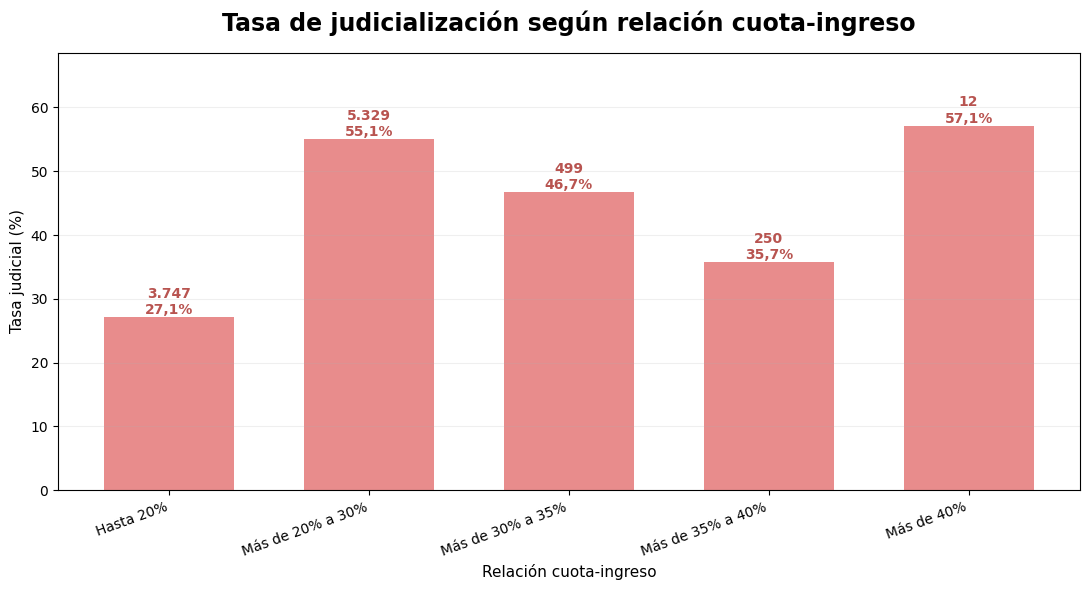

In [ ]:
# ============================================================
# GRÁFICO
# ============================================================

fig, ax = plt.subplots(
    figsize=(11, 6)
)

barras = ax.bar(
    tabla_ratio["rango_cuota_ingreso"].astype(str),
    tabla_ratio["Tasa judicial"],
    width=0.65,
    color="#E88C8C"
)


# Etiquetas
for barra, judiciales, total, tasa in zip(
    barras,
    tabla_ratio["Judiciales"],
    tabla_ratio["Prestamos"],
    tabla_ratio["Tasa judicial"]
):

    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        (
            f"{int(judiciales):,}".replace(",", ".")
            + "\n"
            + f"{tasa:.1f}%".replace(".", ",")
        ),
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color="#B85450"
    )


ax.set_title(
    "Tasa de judicialización según relación cuota-ingreso",
    fontsize=17,
    fontweight="bold",
    pad=16
)

ax.set_xlabel(
    "Relación cuota-ingreso",
    fontsize=11
)

ax.set_ylabel(
    "Tasa judicial (%)",
    fontsize=11
)

ax.grid(
    axis="y",
    alpha=0.20
)

plt.xticks(
    rotation=20,
    ha="right"
)

maximo = tabla_ratio["Tasa judicial"].max()

ax.set_ylim(
    0,
    maximo * 1.20
)

plt.tight_layout()

plt.savefig(
    CARPETA / "tasa_judicial_relacion_cuota_ingreso.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

## 13.2 Relación cuota-ingreso: Apertura vs Renovación

Esto es importante porque ya vimos que Apertura y Renovación tienen tasas base de judicialización muy diferentes. Por eso no conviene interpretar el ratio mezclando ambas poblaciones.

In [ ]:
# ============================================================
# 13.2 RELACIÓN CUOTA-INGRESO POR TIPO DE CRÉDITO
# ============================================================

df_ratio["tipo_credito_eda"] = (
    df_ratio["tipocredito"]
    .astype(str)
    .str.strip()
    .str.upper()
)


tabla_ratio_tipo = (
    df_ratio
    .groupby(
        [
            "tipo_credito_eda",
            "rango_cuota_ingreso"
        ],
        observed=False
    )
    .agg(
        Prestamos=("factura", "count"),
        Judiciales=("judicial_bin", "sum")
    )
    .reset_index()
)


tabla_ratio_tipo["Tasa judicial"] = np.where(
    tabla_ratio_tipo["Prestamos"] > 0,
    tabla_ratio_tipo["Judiciales"]
    / tabla_ratio_tipo["Prestamos"] * 100,
    np.nan
)


tabla_ratio_tipo = tabla_ratio_tipo[
    tabla_ratio_tipo["Prestamos"] > 0
].copy()

tabla_ratio_tipo

,tipo_credito_eda,rango_cuota_ingreso,Prestamos,Judiciales,Tasa judicial
0,APERTURA,Hasta 20%,4475,1873,41.854749
1,APERTURA,Más de 20% a 30%,6192,4104,66.279070
2,APERTURA,Más de 30% a 35%,120,83,69.166667
3,APERTURA,Más de 35% a 40%,8,2,25.000000
4,APERTURA,Más de 40%,2,0,0.000000
5,RENOVACION,Hasta 20%,9354,1874,20.034210
6,RENOVACION,Más de 20% a 30%,3484,1225,35.160735
7,RENOVACION,Más de 30% a 35%,948,416,43.881857
8,RENOVACION,Más de 35% a 40%,692,248,35.838150
9,RENOVACION,Más de 40%,19,12,63.157895


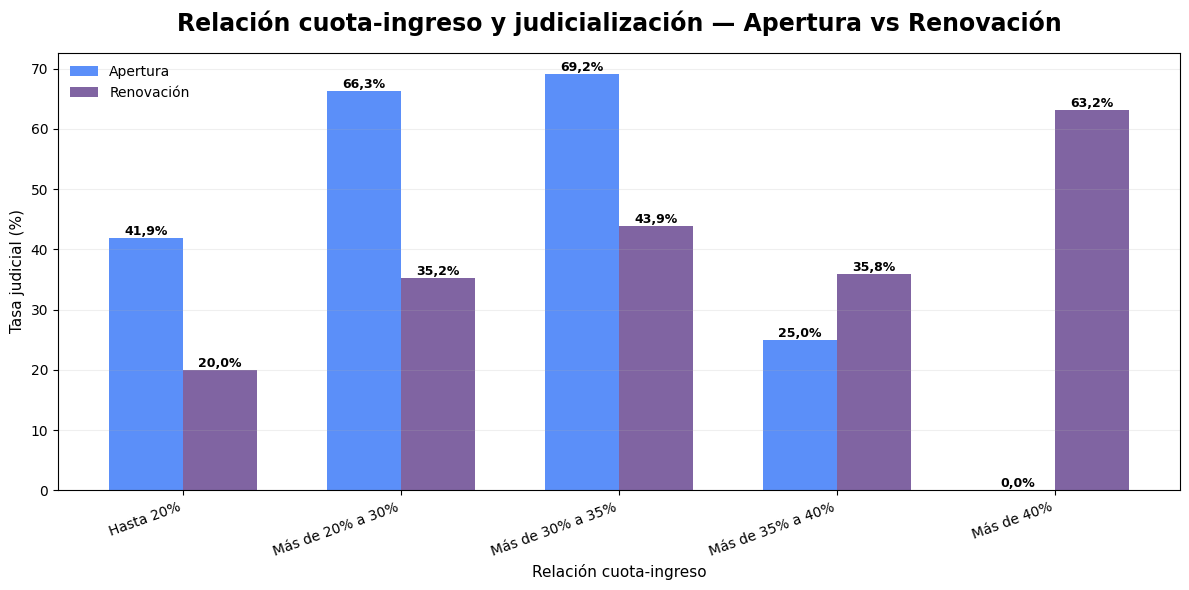

In [ ]:
# ============================================================
# GRÁFICO APERTURA VS RENOVACIÓN
# ============================================================

pivot_ratio = (
    tabla_ratio_tipo
    .pivot(
        index="rango_cuota_ingreso",
        columns="tipo_credito_eda",
        values="Tasa judicial"
    )
)


# respetar orden de los rangos
pivot_ratio = pivot_ratio.reindex(
    etiquetas_ratio
)


fig, ax = plt.subplots(
    figsize=(12, 6)
)

x = np.arange(
    len(pivot_ratio.index)
)

ancho = 0.34


# Apertura
if "APERTURA" in pivot_ratio.columns:

    barras_ap = ax.bar(
        x - ancho / 2,
        pivot_ratio["APERTURA"],
        width=ancho,
        label="Apertura",
        color="#5B8FF9"
    )


# Renovación
if "RENOVACION" in pivot_ratio.columns:

    barras_re = ax.bar(
        x + ancho / 2,
        pivot_ratio["RENOVACION"],
        width=ancho,
        label="Renovación",
        color="#8064A2"
    )


# ------------------------------------------------------------
# Etiquetas
# ------------------------------------------------------------

for contenedor in ax.containers:

    for barra in contenedor:

        altura = barra.get_height()

        if not np.isnan(altura):

            ax.text(
                barra.get_x()
                + barra.get_width() / 2,
                altura,
                f"{altura:.1f}%".replace(".", ","),
                ha="center",
                va="bottom",
                fontsize=9,
                fontweight="bold"
            )


ax.set_title(
    "Relación cuota-ingreso y judicialización — Apertura vs Renovación",
    fontsize=17,
    fontweight="bold",
    pad=16
)

ax.set_ylabel(
    "Tasa judicial (%)",
    fontsize=11
)

ax.set_xlabel(
    "Relación cuota-ingreso",
    fontsize=11
)

ax.set_xticks(x)

ax.set_xticklabels(
    etiquetas_ratio,
    rotation=20,
    ha="right"
)

ax.legend(
    frameon=False
)

ax.grid(
    axis="y",
    alpha=0.20
)

plt.tight_layout()

plt.savefig(
    CARPETA / "ratio_cuota_ingreso_apertura_renovacion.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

### Interpretación

La relación cuota-ingreso permite incorporar al análisis no solo el monto de la cuota, sino también el peso que esa obligación representa respecto del ingreso mensual informado.

Las diferencias observadas entre los distintos rangos muestran que el esfuerzo financiero puede aportar información relevante para caracterizar el comportamiento posterior de las operaciones.

Sin embargo, su interpretación debe realizarse conjuntamente con el tipo de crédito y el resto de las variables. Apertura y Renovación presentan composiciones y tasas de judicialización diferentes, por lo que una misma relación cuota-ingreso no necesariamente implica el mismo comportamiento en ambas poblaciones.

Por este motivo, la variable será incorporada posteriormente al modelado junto con el resto de la información disponible al momento del otorgamiento.

# 14. Matriz de correlaciones de variables candidatas

La matriz permite analizar la relación lineal entre las variables numéricas candidatas y la judicialización. También permite detectar relaciones elevadas entre las propias variables, que podrían indicar información redundante.

El análisis incluye variables disponibles al otorgamiento y antecedentes internos anteriores al crédito actual. La variable `genero` se incorpora como binaria, donde 1 representa femenino y 0 masculino.

Se excluyen las variables posteriores del préstamo actual porque podrían generar fuga de información. También se excluyen de esta matriz `cantidad_prestamos_anteriores`, `prestamos_cancelados_normal` y `renovacion_sin_historial_observable`.

Provincia y actividad continúan siendo variables candidatas, pero no se incorporan a la correlación de Pearson porque son categóricas nominales. Su asociación con la judicialización se evalúa mediante las tasas por segmento y la V de Cramér.

La variable `judicial_bin` se incluye únicamente como referencia descriptiva, donde 1 representa Judicial y 0 No judicial. Una correlación baja no implica que una variable carezca de utilidad predictiva, ya que Pearson mide solamente relaciones lineales individuales.

POBLACIÓN UTILIZADA
Préstamos incluidos: 25.294
Judiciales: 9.837
No judiciales: 15.457

Variables incluidas en la matriz:
• capitalprestado
• plan
• interes
• totalfac
• monto_cuota
• SUELDO
• costo_credito
• relacion_cuota_ingreso
• score_numerico
• genero
• tuvo_mora_anterior
• max_mora_prestamos_anteriores
• prestamos_en_judicial_anteriores
• judicial_bin


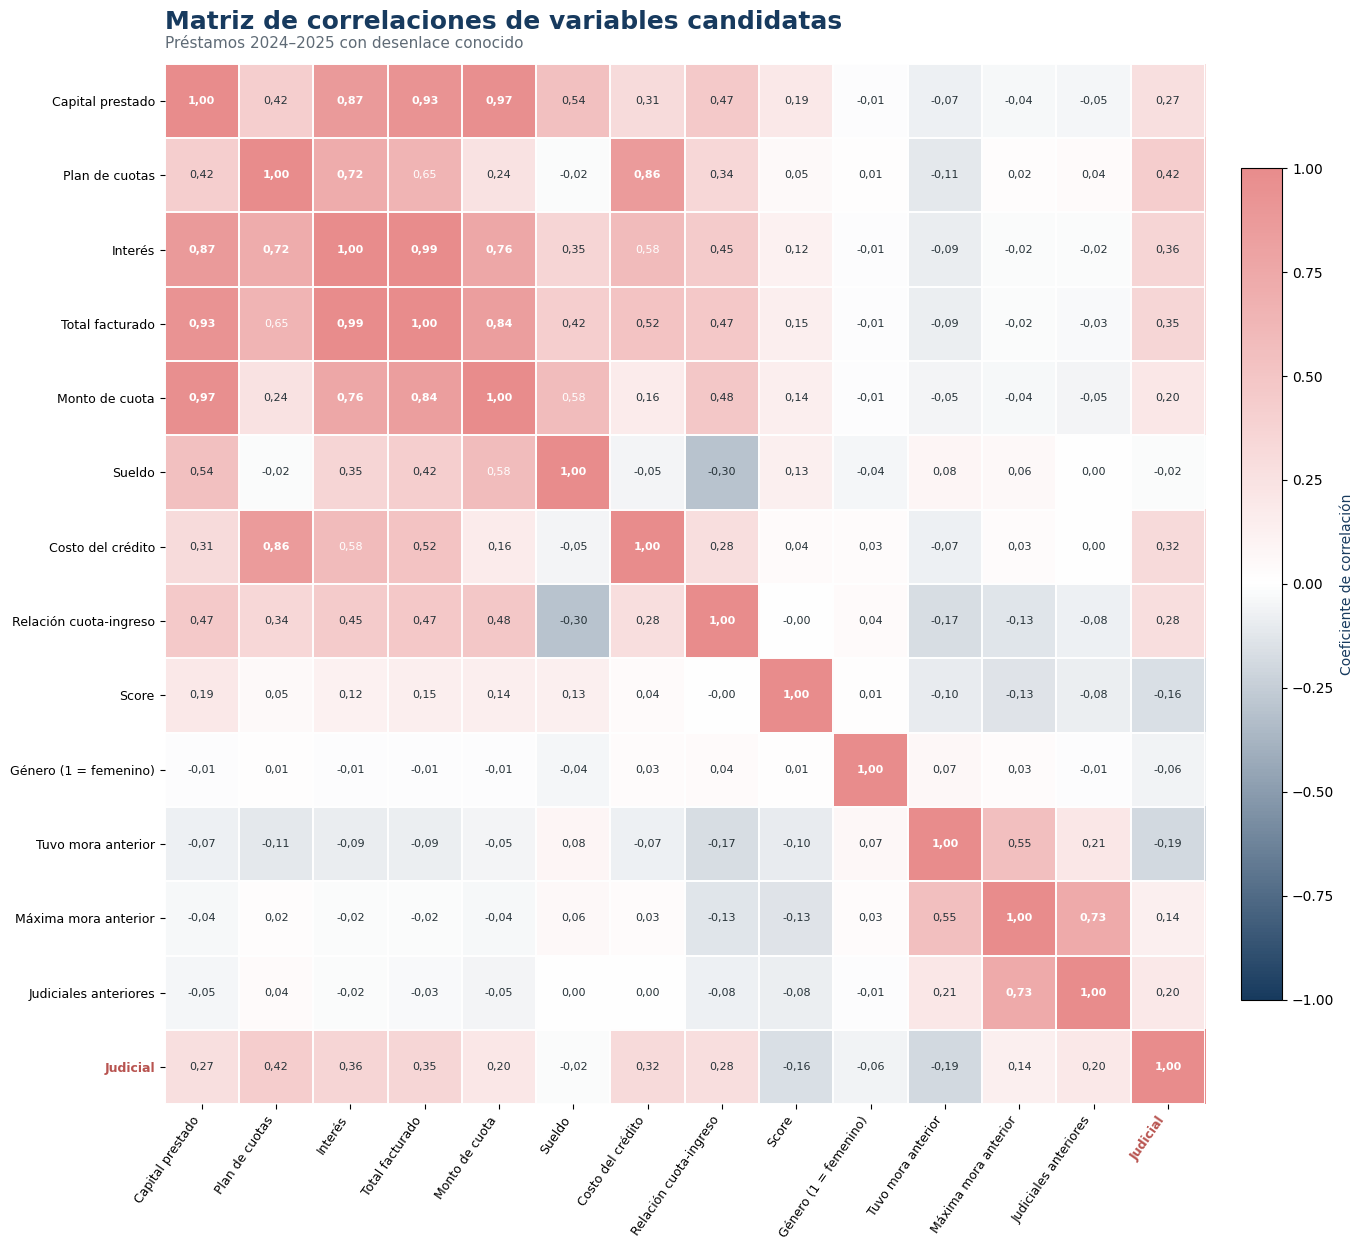

In [ ]:
# ============================================================
# 14. MATRIZ DE CORRELACIONES DE VARIABLES CANDIDATAS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap


# ------------------------------------------------------------
# 1. POBLACIÓN DEL ANÁLISIS
# ------------------------------------------------------------

# Préstamos 2024-2025 con desenlace conocido:
# Judicial = targets 2 y 5
# No judicial = targets 3 y 4

base_correlacion_eda = df_2024_2026[
    df_2024_2026["añofac"].between(2024, 2025)
    & df_2024_2026["target"].isin([2, 3, 4, 5])
].copy()

base_correlacion_eda["judicial_bin"] = np.where(
    base_correlacion_eda["target"].isin([2, 5]),
    1,
    0
).astype(int)


# ------------------------------------------------------------
# 2. VARIABLES CANDIDATAS PARA PEARSON
# ------------------------------------------------------------

variables_correlacion = [
    # Variables disponibles al otorgamiento
    "capitalprestado",
    "plan",
    "interes",
    "totalfac",
    "monto_cuota",
    "SUELDO",
    "costo_credito",
    "relacion_cuota_ingreso",
    "score_numerico",
    "genero",

    # Historial previo válido para Renovación
    "tuvo_mora_anterior",
    "max_mora_prestamos_anteriores",
    "prestamos_en_judicial_anteriores",

    # Target como referencia descriptiva
    "judicial_bin"
]

variables_disponibles = [
    variable
    for variable in variables_correlacion
    if variable in base_correlacion_eda.columns
]

variables_no_encontradas = [
    variable
    for variable in variables_correlacion
    if variable not in base_correlacion_eda.columns
]

print("=" * 68)
print("POBLACIÓN UTILIZADA")
print("=" * 68)

print(
    "Préstamos incluidos:",
    f"{len(base_correlacion_eda):,.0f}".replace(",", ".")
)

print(
    "Judiciales:",
    f"{base_correlacion_eda['judicial_bin'].sum():,.0f}"
    .replace(",", ".")
)

print(
    "No judiciales:",
    f"{base_correlacion_eda['judicial_bin'].eq(0).sum():,.0f}"
    .replace(",", ".")
)

print("\nVariables incluidas en la matriz:")

for variable in variables_disponibles:
    print(f"• {variable}")

if variables_no_encontradas:
    print("\nVariables no encontradas:")

    for variable in variables_no_encontradas:
        print(f"• {variable}")


# ------------------------------------------------------------
# 3. PREPARAR DATOS NUMÉRICOS
# ------------------------------------------------------------

datos_correlacion = (
    base_correlacion_eda[
        variables_disponibles
    ]
    .apply(pd.to_numeric, errors="coerce")
    .copy()
)

variables_sin_variacion = [
    variable
    for variable in datos_correlacion.columns
    if datos_correlacion[variable].nunique(dropna=True) <= 1
]

if variables_sin_variacion:
    print("\nVariables excluidas por no presentar variación:")

    for variable in variables_sin_variacion:
        print(f"• {variable}")

    datos_correlacion = datos_correlacion.drop(
        columns=variables_sin_variacion
    )

if datos_correlacion.shape[1] < 2:
    raise ValueError(
        "No hay suficientes variables para calcular la matriz."
    )


# ------------------------------------------------------------
# 4. CALCULAR CORRELACIONES
# ------------------------------------------------------------

matriz_correlacion = datos_correlacion.corr(
    method="pearson",
    min_periods=30
)


# ------------------------------------------------------------
# 5. NOMBRES PARA PRESENTACIÓN
# ------------------------------------------------------------

nombres_presentacion = {
    "capitalprestado": "Capital prestado",
    "plan": "Plan de cuotas",
    "interes": "Interés",
    "totalfac": "Total facturado",
    "monto_cuota": "Monto de cuota",
    "SUELDO": "Sueldo",
    "costo_credito": "Costo del crédito",
    "relacion_cuota_ingreso": "Relación cuota-ingreso",
    "score_numerico": "Score",
    "genero": "Género (1 = femenino)",
    "tuvo_mora_anterior": "Tuvo mora anterior",
    "max_mora_prestamos_anteriores": "Máxima mora anterior",
    "prestamos_en_judicial_anteriores": "Judiciales anteriores",
    "judicial_bin": "Judicial"
}

etiquetas = [
    nombres_presentacion.get(variable, variable)
    for variable in matriz_correlacion.columns
]


# ------------------------------------------------------------
# 6. PALETA DE COLORES
# ------------------------------------------------------------

mapa_correlacion = LinearSegmentedColormap.from_list(
    "correlacion_eda",
    [
        "#173A5E",
        "#FFFFFF",
        "#E88C8C"
    ]
)


# ------------------------------------------------------------
# 7. MATRIZ CUADRADA
# ------------------------------------------------------------

cantidad_variables = len(
    matriz_correlacion.columns
)

fig, ax = plt.subplots(
    figsize=(
        max(14, cantidad_variables * 1.00),
        max(12, cantidad_variables * 0.90)
    ),
    facecolor="white"
)

imagen = ax.imshow(
    matriz_correlacion.values,
    cmap=mapa_correlacion,
    vmin=-1,
    vmax=1,
    aspect="equal"
)

ax.set_xticks(
    range(cantidad_variables)
)

ax.set_yticks(
    range(cantidad_variables)
)

ax.set_xticklabels(
    etiquetas,
    rotation=55,
    ha="right",
    fontsize=9
)

ax.set_yticklabels(
    etiquetas,
    fontsize=9
)


# ------------------------------------------------------------
# 8. VALORES EN LAS CELDAS
# ------------------------------------------------------------

for fila in range(cantidad_variables):

    for columna in range(cantidad_variables):

        valor = matriz_correlacion.iloc[
            fila,
            columna
        ]

        if pd.notna(valor):

            color_texto = (
                "white"
                if abs(valor) >= 0.55
                else "#263238"
            )

            ax.text(
                columna,
                fila,
                f"{valor:.2f}".replace(".", ","),
                ha="center",
                va="center",
                fontsize=8,
                color=color_texto,
                fontweight=(
                    "bold"
                    if abs(valor) >= 0.70
                    else "normal"
                )
            )


# ------------------------------------------------------------
# 9. DESTACAR JUDICIAL
# ------------------------------------------------------------

if "judicial_bin" in matriz_correlacion.columns:

    posicion_judicial = list(
        matriz_correlacion.columns
    ).index("judicial_bin")

    ax.get_xticklabels()[
        posicion_judicial
    ].set_color("#B85450")

    ax.get_xticklabels()[
        posicion_judicial
    ].set_fontweight("bold")

    ax.get_yticklabels()[
        posicion_judicial
    ].set_color("#B85450")

    ax.get_yticklabels()[
        posicion_judicial
    ].set_fontweight("bold")


# ------------------------------------------------------------
# 10. TÍTULO Y FORMATO
# ------------------------------------------------------------

ax.set_title(
    "Matriz de correlaciones de variables candidatas",
    loc="left",
    fontsize=18,
    fontweight="bold",
    color="#173A5E",
    pad=25
)

ax.text(
    0,
    1.015,
    "Préstamos 2024–2025 con desenlace conocido",
    transform=ax.transAxes,
    fontsize=11,
    color="#5F6B76",
    ha="left"
)

barra_color = fig.colorbar(
    imagen,
    ax=ax,
    fraction=0.035,
    pad=0.03
)

barra_color.set_label(
    "Coeficiente de correlación",
    fontsize=10,
    color="#173A5E"
)

ax.set_xticks(
    np.arange(-0.5, cantidad_variables, 1),
    minor=True
)

ax.set_yticks(
    np.arange(-0.5, cantidad_variables, 1),
    minor=True
)

ax.grid(
    which="minor",
    color="white",
    linewidth=1.4
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)

for borde in ax.spines.values():
    borde.set_visible(False)

plt.tight_layout()
plt.show()

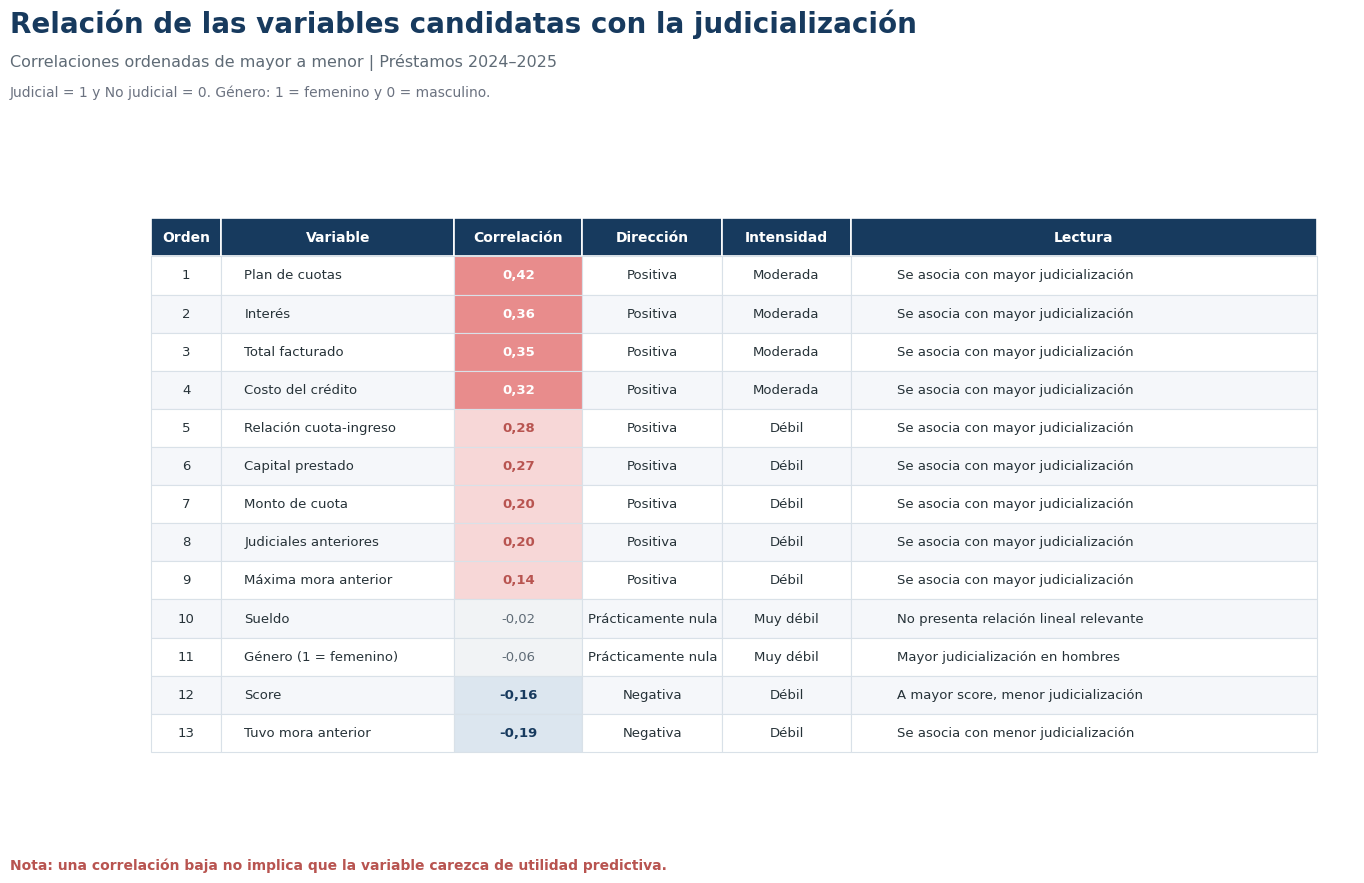

ASOCIACIÓN DE PROVINCIA Y ACTIVIDAD CON JUDICIAL


,Variable,Medida,Valor,Interpretación
0,Provincia,V de Cramér,"0,166",Asociación débil
1,Actividad,V de Cramér,"0,076",Asociación muy débil


In [ ]:
# ============================================================
# 14.1 RESULTADOS DE LA ASOCIACIÓN CON JUDICIAL
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from IPython.display import display


# ------------------------------------------------------------
# 1. FUNCIONES DE INTERPRETACIÓN
# ------------------------------------------------------------

def obtener_direccion(valor):

    if valor >= 0.10:
        return "Positiva"

    elif valor <= -0.10:
        return "Negativa"

    else:
        return "Prácticamente nula"


def obtener_intensidad(valor):

    valor_absoluto = abs(valor)

    if valor_absoluto >= 0.70:
        return "Muy fuerte"

    elif valor_absoluto >= 0.50:
        return "Fuerte"

    elif valor_absoluto >= 0.30:
        return "Moderada"

    elif valor_absoluto >= 0.10:
        return "Débil"

    else:
        return "Muy débil"


def obtener_lectura(variable, valor):

    if variable == "score_numerico":
        return (
            "A mayor score, menor judicialización"
            if valor < 0
            else "A mayor score, mayor judicialización"
        )

    if variable == "genero":
        return (
            "Mayor judicialización en mujeres"
            if valor > 0
            else "Mayor judicialización en hombres"
        )

    if valor >= 0.10:
        return "Se asocia con mayor judicialización"

    elif valor <= -0.10:
        return "Se asocia con menor judicialización"

    else:
        return "No presenta relación lineal relevante"


# ------------------------------------------------------------
# 2. TABLA DE CORRELACIÓN CON JUDICIAL
# ------------------------------------------------------------

if "judicial_bin" not in matriz_correlacion.columns:
    raise ValueError(
        "judicial_bin no está disponible en la matriz."
    )

tabla_judicial = (
    matriz_correlacion["judicial_bin"]
    .drop(labels="judicial_bin")
    .reset_index()
)

tabla_judicial.columns = [
    "Variable original",
    "Correlación"
]

tabla_judicial["Variable"] = (
    tabla_judicial["Variable original"]
    .map(nombres_presentacion)
    .fillna(tabla_judicial["Variable original"])
)

tabla_judicial["Dirección"] = (
    tabla_judicial["Correlación"]
    .apply(obtener_direccion)
)

tabla_judicial["Intensidad"] = (
    tabla_judicial["Correlación"]
    .apply(obtener_intensidad)
)

tabla_judicial["Lectura"] = tabla_judicial.apply(
    lambda fila: obtener_lectura(
        fila["Variable original"],
        fila["Correlación"]
    ),
    axis=1
)

tabla_judicial = (
    tabla_judicial
    .sort_values(
        "Correlación",
        ascending=False
    )
    .reset_index(drop=True)
)

tabla_judicial.insert(
    0,
    "Orden",
    range(1, len(tabla_judicial) + 1)
)

tabla_mostrar = tabla_judicial[
    [
        "Orden",
        "Variable",
        "Correlación",
        "Dirección",
        "Intensidad",
        "Lectura"
    ]
].copy()

tabla_mostrar["Correlación"] = (
    tabla_mostrar["Correlación"]
    .map(
        lambda valor:
        f"{valor:.2f}".replace(".", ",")
    )
)


# ------------------------------------------------------------
# 3. TABLA GRÁFICA PROFESIONAL
# ------------------------------------------------------------

cantidad_filas = len(
    tabla_mostrar
)

fig, ax = plt.subplots(
    figsize=(16, 9),
    facecolor="white"
)

ax.axis("off")

fig.text(
    0.06,
    0.955,
    "Relación de las variables candidatas con la judicialización",
    fontsize=20,
    fontweight="bold",
    color="#173A5E",
    ha="left"
)

fig.text(
    0.06,
    0.918,
    "Correlaciones ordenadas de mayor a menor | Préstamos 2024–2025",
    fontsize=11.5,
    color="#5F6B76",
    ha="left"
)

fig.text(
    0.06,
    0.884,
    "Judicial = 1 y No judicial = 0. Género: 1 = femenino y 0 = masculino.",
    fontsize=10,
    color="#6B7280",
    ha="left"
)

tabla_grafica = ax.table(
    cellText=tabla_mostrar.values,
    colLabels=tabla_mostrar.columns,
    cellLoc="center",
    colLoc="center",
    colWidths=[
        0.06,
        0.20,
        0.11,
        0.12,
        0.11,
        0.40
    ],
    bbox=[
        0.03,
        0.06,
        0.94,
        0.77
    ]
)

tabla_grafica.auto_set_font_size(False)
tabla_grafica.set_fontsize(9.5)

# Encabezado
for columna in range(
    len(tabla_mostrar.columns)
):

    celda = tabla_grafica[
        0,
        columna
    ]

    celda.set_facecolor("#173A5E")
    celda.set_edgecolor("white")
    celda.set_linewidth(1.2)

    celda.get_text().set_color("white")
    celda.get_text().set_fontweight("bold")
    celda.get_text().set_fontsize(10)

# Filas
for fila in range(1, cantidad_filas + 1):

    valor = tabla_judicial.loc[
        fila - 1,
        "Correlación"
    ]

    color_fila = (
        "#F5F7FA"
        if fila % 2 == 0
        else "white"
    )

    for columna in range(
        len(tabla_mostrar.columns)
    ):

        celda = tabla_grafica[
            fila,
            columna
        ]

        celda.set_facecolor(color_fila)
        celda.set_edgecolor("#D9E1E8")
        celda.set_linewidth(0.8)
        celda.get_text().set_color("#263238")

        if columna in [1, 5]:
            celda.get_text().set_ha("left")

    celda_correlacion = tabla_grafica[
        fila,
        2
    ]

    if valor >= 0.30:
        celda_correlacion.set_facecolor("#E88C8C")
        celda_correlacion.get_text().set_color("white")
        celda_correlacion.get_text().set_fontweight("bold")

    elif valor >= 0.10:
        celda_correlacion.set_facecolor("#F7D7D7")
        celda_correlacion.get_text().set_color("#B85450")
        celda_correlacion.get_text().set_fontweight("bold")

    elif valor <= -0.30:
        celda_correlacion.set_facecolor("#6F8FAF")
        celda_correlacion.get_text().set_color("white")
        celda_correlacion.get_text().set_fontweight("bold")

    elif valor <= -0.10:
        celda_correlacion.set_facecolor("#DCE6EF")
        celda_correlacion.get_text().set_color("#173A5E")
        celda_correlacion.get_text().set_fontweight("bold")

    else:
        celda_correlacion.set_facecolor("#F1F3F5")
        celda_correlacion.get_text().set_color("#5F6B76")

fig.text(
    0.06,
    0.025,
    "Nota: una correlación baja no implica que la variable carezca de utilidad predictiva.",
    fontsize=10,
    color="#B85450",
    fontweight="bold",
    ha="left"
)

plt.show()


# ------------------------------------------------------------
# 4. V DE CRAMÉR PARA PROVINCIA Y ACTIVIDAD
# ------------------------------------------------------------

def calcular_v_cramer(base, variable, target):

    datos = base[
        [variable, target]
    ].copy()

    datos[variable] = (
        datos[variable]
        .astype("object")
        .where(
            datos[variable].notna(),
            "Sin dato"
        )
    )

    tabla_contingencia = pd.crosstab(
        datos[variable],
        datos[target]
    )

    if (
        tabla_contingencia.shape[0] < 2
        or tabla_contingencia.shape[1] < 2
    ):
        return np.nan

    chi2 = chi2_contingency(
        tabla_contingencia
    )[0]

    cantidad = tabla_contingencia.values.sum()

    filas = tabla_contingencia.shape[0]
    columnas = tabla_contingencia.shape[1]

    denominador = min(
        filas - 1,
        columnas - 1
    )

    if cantidad == 0 or denominador == 0:
        return np.nan

    return np.sqrt(
        (chi2 / cantidad)
        / denominador
    )


def interpretar_v_cramer(valor):

    if pd.isna(valor):
        return "No calculable"

    elif valor >= 0.50:
        return "Asociación fuerte"

    elif valor >= 0.30:
        return "Asociación moderada"

    elif valor >= 0.10:
        return "Asociación débil"

    else:
        return "Asociación muy débil"


variables_categoricas = [
    "provincia",
    "actividad"
]

filas_cramer = []

for variable in variables_categoricas:

    if variable not in base_correlacion_eda.columns:
        continue

    valor_v = calcular_v_cramer(
        base_correlacion_eda,
        variable,
        "judicial_bin"
    )

    filas_cramer.append({
        "Variable": variable.capitalize(),
        "Medida": "V de Cramér",
        "Valor": valor_v,
        "Interpretación": interpretar_v_cramer(
            valor_v
        )
    })

tabla_cramer = pd.DataFrame(
    filas_cramer
)

tabla_cramer = (
    tabla_cramer
    .sort_values(
        "Valor",
        ascending=False
    )
    .reset_index(drop=True)
)

tabla_cramer_mostrar = tabla_cramer.copy()

tabla_cramer_mostrar["Valor"] = (
    tabla_cramer_mostrar["Valor"]
    .map(
        lambda valor:
        f"{valor:.3f}".replace(".", ",")
        if pd.notna(valor)
        else "Sin dato"
    )
)

print("=" * 68)
print("ASOCIACIÓN DE PROVINCIA Y ACTIVIDAD CON JUDICIAL")
print("=" * 68)

display(
    tabla_cramer_mostrar
)


La matriz muestra que ninguna variable presenta, de manera individual, una correlación fuerte con la judicialización. El plan de cuotas, el interés, el total facturado, el costo del crédito y la relación cuota-ingreso presentan las asociaciones positivas más relevantes, aunque de intensidad moderada o débil. Esto indica que el riesgo de derivación a Gestión Judicial no depende de una única característica, sino de la combinación de distintas condiciones del crédito y del cliente.

El score presenta una relación negativa con la judicialización, consistente con lo esperado: a mayor score, menor judicialización observada. Sin embargo, su asociación lineal es débil, lo que demuestra que un score elevado reduce el riesgo esperado, pero no garantiza el cumplimiento. Por este motivo, el modelo propuesto busca complementar el score con otras variables disponibles al momento del otorgamiento.

El sueldo, considerado de forma aislada, presenta una relación prácticamente nula. En cambio, la relación cuota-ingreso aporta una señal más clara, debido a que representa el esfuerzo financiero asumido por el cliente y no solamente su nivel de ingreso.

Provincia y actividad no se incorporan a la correlación de Pearson por tratarse de variables categóricas nominales. Su asociación global con la judicialización se evalúa mediante la V de Cramér y se complementa con las tasas observadas en cada categoría. Una asociación global débil no implica que todas las provincias o actividades presenten el mismo comportamiento, por lo que también deben considerarse el volumen de operaciones y las tasas específicas de cada segmento.

Finalmente, se observan correlaciones elevadas entre algunas variables financieras, como capital, interés, total facturado y monto de cuota. Estas relaciones indican posible información redundante.

En conjunto, los resultados respaldan la construcción de un modelo multivariable: ninguna variable determina por sí sola la judicialización, pero varias pueden aportar información cuando se analizan conjuntamente.

# 15. Resumen de hallazgos por segmento

Este bloque sintetiza los resultados de las segmentaciones realizadas anteriormente. Para cada variable se identifica la categoría con mayor cantidad de préstamos y la categoría con mayor tasa de judicialización.

La categoría de mayor volumen permite conocer dónde se concentra la cartera, mientras que la categoría de mayor tasa permite identificar el segmento con mayor proporción de casos judiciales.

Para evitar conclusiones basadas en grupos muy pequeños, la búsqueda de la tasa máxima considera únicamente categorías con al menos 30 préstamos. Las tasas representan asociaciones descriptivas dentro de la base analizada y no deben interpretarse como relaciones causales.

RESUMEN DE HALLAZGOS POR SEGMENTO
Población: 25.294 préstamos
Base mínima para considerar una categoría de mayor riesgo: 30 préstamos


,Segmento,Categoría más frecuente,Préstamos categoría frecuente,Tasa categoría frecuente,Categoría de mayor riesgo,Préstamos categoría de riesgo,Tasa categoría de riesgo
0,Tipo de crédito,RENOVACION,14.497,"26,0%",APERTURA,10.797,"56,1%"
1,Score,400–499,10.373,"45,7%",400–499,10.373,"45,7%"
2,Actividad,Publico,14.719,"39,7%",Privado,9.210,"39,8%"
3,Provincia,CHACO,4.341,"25,8%",STGO.ESTERO,278,"63,7%"
4,Edad,40-49,7.307,"41,3%",20-29,2.177,"47,8%"
5,Género,Masculino,16.246,"41,0%",Masculino,16.246,"41,0%"
6,Plan de cuotas,12,10.112,"41,0%",24,1.452,"92,1%"
7,Sucursal,711,2.078,"50,0%",725,67,"73,1%"
8,Relación cuota-ingreso,Hasta 20%,13.829,"27,1%",20–30%,9.676,"55,1%"


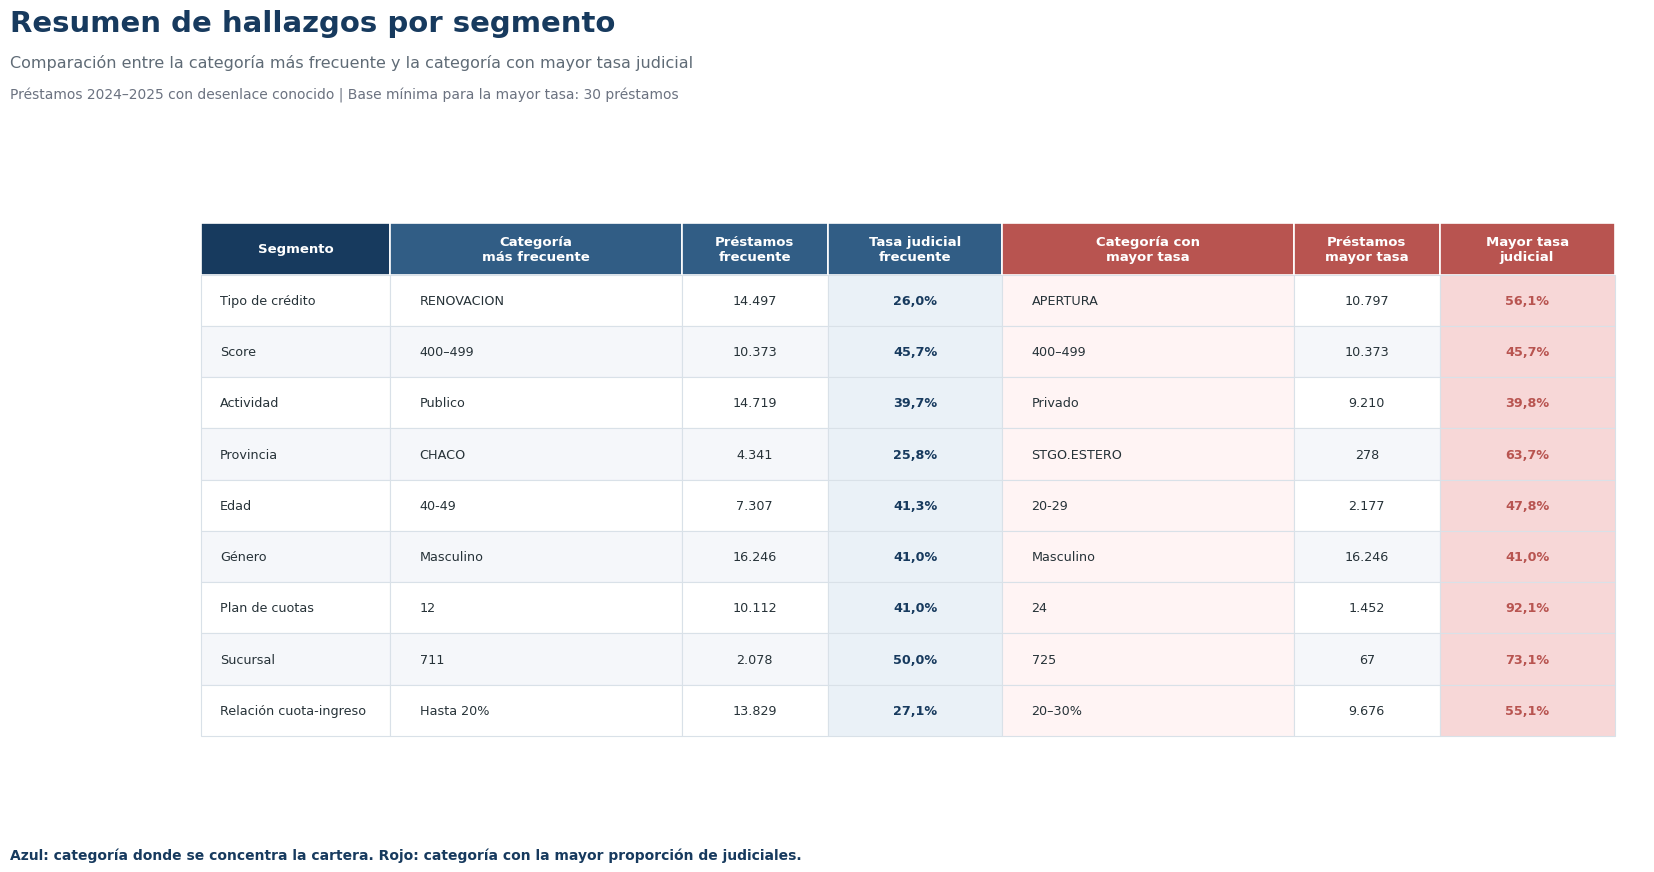

In [ ]:
# ============================================================
# 15. RESUMEN DE HALLAZGOS POR SEGMENTO
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


# ------------------------------------------------------------
# 1. POBLACIÓN ANALIZADA
# ------------------------------------------------------------

# Judicial = targets 2 y 5
# No judicial = targets 3 y 4

base_resumen_segmentos = df_2024_2026[
    df_2024_2026["añofac"].between(2024, 2025)
    & df_2024_2026["target"].isin([2, 3, 4, 5])
].copy()

base_resumen_segmentos["judicial_bin"] = np.where(
    base_resumen_segmentos["target"].isin([2, 5]),
    1,
    0
).astype(int)

# Reconstrucción del rango cuota-ingreso dentro de la base utilizada por este resumen.
limites_ratio_resumen = [-np.inf, 20, 30, 35, 40, np.inf]
etiquetas_ratio_resumen = ["Hasta 20%", "20–30%", "30–35%", "35–40%", "Más de 40%"]

base_resumen_segmentos["rango_cuota_ingreso"] = pd.cut(
    base_resumen_segmentos["relacion_cuota_ingreso"],
    bins=limites_ratio_resumen,
    labels=etiquetas_ratio_resumen,
    include_lowest=True,
    ordered=True,
)


# ------------------------------------------------------------
# 2. CONFIGURACIÓN
# ------------------------------------------------------------

MINIMO_PRESTAMOS = 30

segmentos = [
    {
        "variable": "tipocredito",
        "nombre": "Tipo de crédito"
    },
    {
        "variable": "tramo_score_100",
        "nombre": "Score"
    },
    {
        "variable": "actividad",
        "nombre": "Actividad"
    },
    {
        "variable": "provincia",
        "nombre": "Provincia"
    },
    {
        "variable": "rangoedad",
        "nombre": "Edad"
    },
    {
        "variable": "genero",
        "nombre": "Género"
    },
    {
        "variable": "plan",
        "nombre": "Plan de cuotas"
    },
    {
        "variable": "sucursal",
        "nombre": "Sucursal"
    },
    {
        "variable": "rango_cuota_ingreso",
        "nombre": "Relación cuota-ingreso"
    }
]


# ------------------------------------------------------------
# 3. FUNCIÓN PARA MOSTRAR CATEGORÍAS
# ------------------------------------------------------------

def formatear_categoria(valor, variable):

    if pd.isna(valor):
        return "Sin dato"

    # Género: 1 femenino y 0 masculino
    if variable == "genero":

        try:
            genero_numero = int(float(valor))

            if genero_numero == 1:
                return "Femenino"

            elif genero_numero == 0:
                return "Masculino"

        except (ValueError, TypeError):
            pass

    # Plan y sucursal sin decimales
    if variable in ["plan", "sucursal"]:

        try:
            valor_numerico = float(valor)

            if valor_numerico.is_integer():
                return str(
                    int(valor_numerico)
                )

        except (ValueError, TypeError):
            pass

    return str(valor)


# ------------------------------------------------------------
# 4. FUNCIÓN DE RESUMEN
# ------------------------------------------------------------

def resumir_segmento(
    base,
    variable,
    nombre,
    minimo_prestamos
):

    if variable not in base.columns:
        return None

    temporal = base[
        [variable, "judicial_bin"]
    ].copy()

    temporal[variable] = (
        temporal[variable]
        .astype("object")
        .where(
            temporal[variable].notna(),
            "Sin dato"
        )
    )

    tabla = (
        temporal
        .groupby(
            variable,
            dropna=False
        )
        .agg(
            Prestamos=(
                "judicial_bin",
                "size"
            ),
            Judiciales=(
                "judicial_bin",
                "sum"
            )
        )
        .reset_index()
    )

    tabla["Tasa judicial"] = (
        tabla["Judiciales"]
        / tabla["Prestamos"]
        * 100
    )

    if tabla.empty:
        return None

    # Categoría más frecuente
    fila_mayor_volumen = tabla.loc[
        tabla["Prestamos"].idxmax()
    ]

    # Categorías con una cantidad mínima de préstamos
    tabla_base_suficiente = tabla[
        tabla["Prestamos"] >= minimo_prestamos
    ].copy()

    if tabla_base_suficiente.empty:

        fila_mayor_riesgo = tabla.loc[
            tabla["Tasa judicial"].idxmax()
        ]

    else:

        fila_mayor_riesgo = (
            tabla_base_suficiente.loc[
                tabla_base_suficiente[
                    "Tasa judicial"
                ].idxmax()
            ]
        )

    return {
        "Segmento": nombre,

        "Categoría más frecuente": formatear_categoria(
            fila_mayor_volumen[variable],
            variable
        ),

        "Préstamos categoría frecuente": int(
            fila_mayor_volumen["Prestamos"]
        ),

        "Tasa categoría frecuente": float(
            fila_mayor_volumen["Tasa judicial"]
        ),

        "Categoría de mayor riesgo": formatear_categoria(
            fila_mayor_riesgo[variable],
            variable
        ),

        "Préstamos categoría de riesgo": int(
            fila_mayor_riesgo["Prestamos"]
        ),

        "Tasa categoría de riesgo": float(
            fila_mayor_riesgo["Tasa judicial"]
        )
    }


# ------------------------------------------------------------
# 5. CONSTRUIR EL RESUMEN
# ------------------------------------------------------------

filas_resumen = []

variables_no_encontradas = []

for segmento in segmentos:

    variable = segmento["variable"]
    nombre = segmento["nombre"]

    if variable not in base_resumen_segmentos.columns:

        variables_no_encontradas.append(
            variable
        )

        continue

    resultado = resumir_segmento(
        base=base_resumen_segmentos,
        variable=variable,
        nombre=nombre,
        minimo_prestamos=MINIMO_PRESTAMOS
    )

    if resultado is not None:
        filas_resumen.append(
            resultado
        )

tabla_hallazgos_segmentos = pd.DataFrame(
    filas_resumen
)

if tabla_hallazgos_segmentos.empty:
    raise ValueError(
        "No fue posible construir el resumen por segmentos."
    )

if variables_no_encontradas:
    print("Variables no encontradas:")

    for variable in variables_no_encontradas:
        print(f"• {variable}")


# ------------------------------------------------------------
# 6. ORDENAR LOS SEGMENTOS
# ------------------------------------------------------------

orden_segmentos = [
    segmento["nombre"]
    for segmento in segmentos
]

tabla_hallazgos_segmentos["Segmento"] = pd.Categorical(
    tabla_hallazgos_segmentos["Segmento"],
    categories=orden_segmentos,
    ordered=True
)

tabla_hallazgos_segmentos = (
    tabla_hallazgos_segmentos
    .sort_values("Segmento")
    .reset_index(drop=True)
)

tabla_hallazgos_segmentos["Segmento"] = (
    tabla_hallazgos_segmentos[
        "Segmento"
    ].astype(str)
)


# ------------------------------------------------------------
# 7. VERSIÓN FORMATEADA
# ------------------------------------------------------------

tabla_mostrar = (
    tabla_hallazgos_segmentos.copy()
)

columnas_cantidad = [
    "Préstamos categoría frecuente",
    "Préstamos categoría de riesgo"
]

for columna in columnas_cantidad:

    tabla_mostrar[columna] = (
        tabla_mostrar[columna]
        .map(
            lambda valor:
            f"{valor:,.0f}".replace(",", ".")
        )
    )

columnas_tasa = [
    "Tasa categoría frecuente",
    "Tasa categoría de riesgo"
]

for columna in columnas_tasa:

    tabla_mostrar[columna] = (
        tabla_mostrar[columna]
        .map(
            lambda valor:
            f"{valor:.1f}%".replace(".", ",")
        )
    )


# ------------------------------------------------------------
# 8. TABLA DE CONTROL
# ------------------------------------------------------------

print("=" * 90)
print("RESUMEN DE HALLAZGOS POR SEGMENTO")
print("=" * 90)

print(
    "Población:",
    f"{len(base_resumen_segmentos):,.0f} préstamos"
    .replace(",", ".")
)

print(
    "Base mínima para considerar una categoría de mayor riesgo:",
    f"{MINIMO_PRESTAMOS} préstamos"
)

display(
    tabla_mostrar
)


# ------------------------------------------------------------
# 9. PREPARAR TABLA GRÁFICA
# ------------------------------------------------------------

datos_grafico = tabla_mostrar.rename(
    columns={
        "Categoría más frecuente":
            "Categoría\nmás frecuente",

        "Préstamos categoría frecuente":
            "Préstamos\nfrecuente",

        "Tasa categoría frecuente":
            "Tasa judicial\nfrecuente",

        "Categoría de mayor riesgo":
            "Categoría con\nmayor tasa",

        "Préstamos categoría de riesgo":
            "Préstamos\nmayor tasa",

        "Tasa categoría de riesgo":
            "Mayor tasa\njudicial"
    }
)

columnas_grafico = [
    "Segmento",
    "Categoría\nmás frecuente",
    "Préstamos\nfrecuente",
    "Tasa judicial\nfrecuente",
    "Categoría con\nmayor tasa",
    "Préstamos\nmayor tasa",
    "Mayor tasa\njudicial"
]

datos_grafico = datos_grafico[
    columnas_grafico
]


# ------------------------------------------------------------
# 10. CREAR TABLA GRÁFICA PROFESIONAL
# ------------------------------------------------------------

cantidad_filas = len(
    datos_grafico
)

fig, ax = plt.subplots(
    figsize=(19, 9),
    facecolor="white"
)

ax.axis("off")

fig.text(
    0.04,
    0.955,
    "Resumen de hallazgos por segmento",
    fontsize=21,
    fontweight="bold",
    color="#173A5E",
    ha="left"
)

fig.text(
    0.04,
    0.915,
    (
        "Comparación entre la categoría más frecuente "
        "y la categoría con mayor tasa judicial"
    ),
    fontsize=11.5,
    color="#5F6B76",
    ha="left"
)

fig.text(
    0.04,
    0.880,
    (
        "Préstamos 2024–2025 con desenlace conocido | "
        f"Base mínima para la mayor tasa: "
        f"{MINIMO_PRESTAMOS} préstamos"
    ),
    fontsize=10,
    color="#6B7280",
    ha="left"
)

tabla_grafica = ax.table(
    cellText=datos_grafico.values,
    colLabels=datos_grafico.columns,
    cellLoc="center",
    colLoc="center",
    colWidths=[
        0.13,  # Segmento
        0.20,  # Categoría frecuente
        0.10,  # Préstamos frecuente
        0.12,  # Tasa frecuente
        0.20,  # Categoría mayor tasa
        0.10,  # Préstamos mayor tasa
        0.12   # Mayor tasa judicial
    ],
    bbox=[
        0.02,
        0.08,
        0.96,
        0.74
    ]
)

tabla_grafica.auto_set_font_size(False)
tabla_grafica.set_fontsize(9.2)


# ------------------------------------------------------------
# 11. FORMATO DEL ENCABEZADO
# ------------------------------------------------------------

for columna in range(
    len(columnas_grafico)
):

    celda = tabla_grafica[
        0,
        columna
    ]

    celda.set_edgecolor("white")
    celda.set_linewidth(1.2)

    # Grupo de mayor volumen
    if columna in [1, 2, 3]:
        celda.set_facecolor("#315D85")

    # Grupo de mayor riesgo
    elif columna in [4, 5, 6]:
        celda.set_facecolor("#B85450")

    else:
        celda.set_facecolor("#173A5E")

    texto = celda.get_text()
    texto.set_color("white")
    texto.set_fontweight("bold")
    texto.set_fontsize(9.5)


# ------------------------------------------------------------
# 12. FORMATO DE LAS FILAS
# ------------------------------------------------------------

for fila in range(
    1,
    cantidad_filas + 1
):

    color_fila = (
        "#F5F7FA"
        if fila % 2 == 0
        else "white"
    )

    for columna in range(
        len(columnas_grafico)
    ):

        celda = tabla_grafica[
            fila,
            columna
        ]

        celda.set_facecolor(
            color_fila
        )

        celda.set_edgecolor(
            "#D9E1E8"
        )

        celda.set_linewidth(
            0.8
        )

        celda.get_text().set_color(
            "#263238"
        )

        if columna in [0, 1, 4]:
            celda.get_text().set_ha(
                "left"
            )

    # Tasa de la categoría más frecuente
    tabla_grafica[
        fila,
        3
    ].set_facecolor("#EAF1F7")

    tabla_grafica[
        fila,
        3
    ].get_text().set_color("#173A5E")

    tabla_grafica[
        fila,
        3
    ].get_text().set_fontweight("bold")

    # Categoría con mayor tasa
    tabla_grafica[
        fila,
        4
    ].set_facecolor("#FFF4F4")

    # Tasa judicial máxima
    tabla_grafica[
        fila,
        6
    ].set_facecolor("#F7D7D7")

    tabla_grafica[
        fila,
        6
    ].get_text().set_color("#B85450")

    tabla_grafica[
        fila,
        6
    ].get_text().set_fontweight("bold")


# ------------------------------------------------------------
# 13. NOTAS AL PIE
# ------------------------------------------------------------

fig.text(
    0.04,
    0.035,
    (
        "Azul: categoría donde se concentra la cartera. "
        "Rojo: categoría con la mayor proporción de judiciales."
    ),
    fontsize=10,
    color="#173A5E",
    fontweight="bold",
    ha="left"
)

plt.show()

# 16. Variables disponibles al momento de evaluar el crédito

La siguiente tabla presenta exclusivamente la información disponible al momento de evaluar el crédito.

Las variables de otorgamiento pueden utilizarse tanto en Apertura como en Renovación. En Renovación también pueden incorporarse antecedentes internos del cliente, siempre que correspondan a préstamos anteriores y no incluyan información del crédito actual.

La tabla no incluye identificadores, variables posteriores al otorgamiento ni la variable objetivo.

VARIABLES DISPONIBLES AL MOMENTO DE EVALUAR EL CRÉDITO
Variables documentadas: 18
Variables encontradas: 18


,Variable,Grupo,Apertura,Renovación,Descripción
0,sucursal,Perfil y ubicación,Sí,Sí,Sucursal que origina la operación.
1,provincia,Perfil y ubicación,Sí,Sí,Provincia correspondiente a la operación.
2,rangoedad,Perfil del cliente,Sí,Sí,Rango de edad del cliente.
3,genero,Perfil del cliente,Sí,Sí,1 = femenino y 0 = masculino.
4,actividad,Perfil del cliente,Sí,Sí,Actividad laboral informada.
5,motivocompra,Perfil del cliente,Sí,Sí,Motivo declarado para la operación.
6,capitalprestado,Condiciones del crédito,Sí,Sí,Capital otorgado.
7,plan,Condiciones del crédito,Sí,Sí,Cantidad pactada de cuotas.
8,interes,Condiciones del crédito,Sí,Sí,Interés total pactado.
9,totalfac,Condiciones del crédito,Sí,Sí,Importe total facturado.


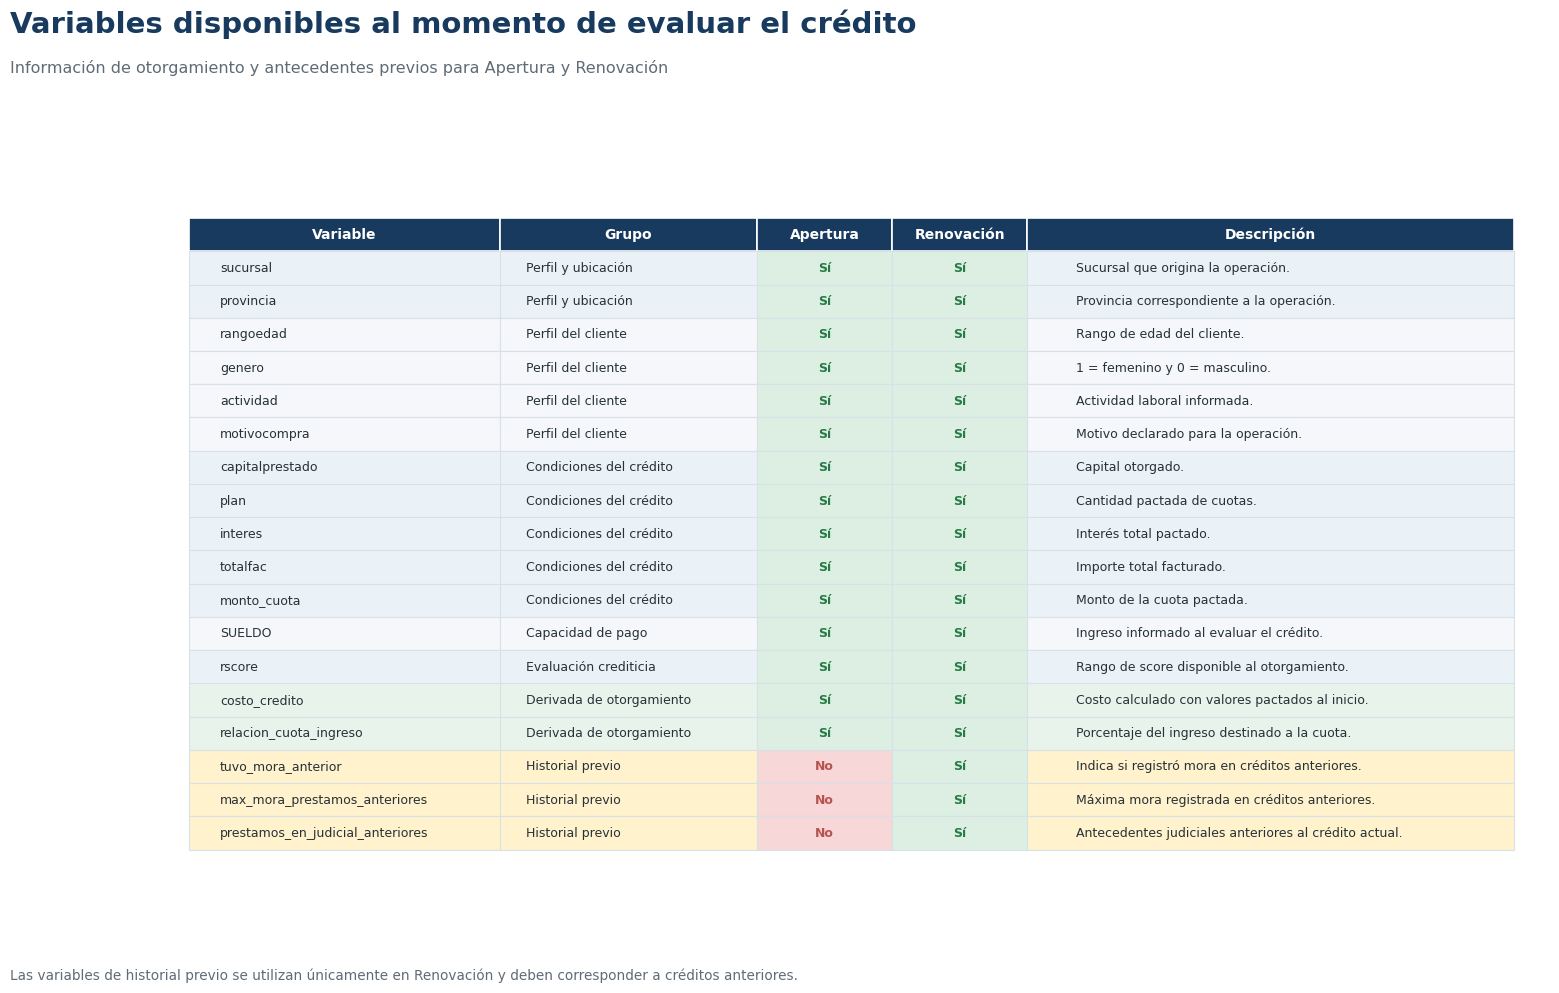

In [ ]:
# ============================================================
# 16. VARIABLES DISPONIBLES AL MOMENTO DE EVALUAR EL CRÉDITO
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


# ------------------------------------------------------------
# 1. DEFINICIÓN DE VARIABLES
# ------------------------------------------------------------

filas_variables = [
    # --------------------------------------------------------
    # INFORMACIÓN DISPONIBLE EN APERTURA Y RENOVACIÓN
    # --------------------------------------------------------
    {
        "Variable": "sucursal",
        "Grupo": "Perfil y ubicación",
        "Apertura": "Sí",
        "Renovación": "Sí",
        "Descripción": "Sucursal que origina la operación."
    },
    {
        "Variable": "provincia",
        "Grupo": "Perfil y ubicación",
        "Apertura": "Sí",
        "Renovación": "Sí",
        "Descripción": "Provincia correspondiente a la operación."
    },
    {
        "Variable": "rangoedad",
        "Grupo": "Perfil del cliente",
        "Apertura": "Sí",
        "Renovación": "Sí",
        "Descripción": "Rango de edad del cliente."
    },
    {
        "Variable": "genero",
        "Grupo": "Perfil del cliente",
        "Apertura": "Sí",
        "Renovación": "Sí",
        "Descripción": "1 = femenino y 0 = masculino."
    },
    {
        "Variable": "actividad",
        "Grupo": "Perfil del cliente",
        "Apertura": "Sí",
        "Renovación": "Sí",
        "Descripción": "Actividad laboral informada."
    },
    {
        "Variable": "motivocompra",
        "Grupo": "Perfil del cliente",
        "Apertura": "Sí",
        "Renovación": "Sí",
        "Descripción": "Motivo declarado para la operación."
    },
    {
        "Variable": "capitalprestado",
        "Grupo": "Condiciones del crédito",
        "Apertura": "Sí",
        "Renovación": "Sí",
        "Descripción": "Capital otorgado."
    },
    {
        "Variable": "plan",
        "Grupo": "Condiciones del crédito",
        "Apertura": "Sí",
        "Renovación": "Sí",
        "Descripción": "Cantidad pactada de cuotas."
    },
    {
        "Variable": "interes",
        "Grupo": "Condiciones del crédito",
        "Apertura": "Sí",
        "Renovación": "Sí",
        "Descripción": "Interés total pactado."
    },
    {
        "Variable": "totalfac",
        "Grupo": "Condiciones del crédito",
        "Apertura": "Sí",
        "Renovación": "Sí",
        "Descripción": "Importe total facturado."
    },
    {
        "Variable": "monto_cuota",
        "Grupo": "Condiciones del crédito",
        "Apertura": "Sí",
        "Renovación": "Sí",
        "Descripción": "Monto de la cuota pactada."
    },
    {
        "Variable": "SUELDO",
        "Grupo": "Capacidad de pago",
        "Apertura": "Sí",
        "Renovación": "Sí",
        "Descripción": "Ingreso informado al evaluar el crédito."
    },
    {
        "Variable": "rscore",
        "Grupo": "Evaluación crediticia",
        "Apertura": "Sí",
        "Renovación": "Sí",
        "Descripción": "Rango de score disponible al otorgamiento."
    },
    {
        "Variable": "costo_credito",
        "Grupo": "Derivada de otorgamiento",
        "Apertura": "Sí",
        "Renovación": "Sí",
        "Descripción": "Costo calculado con valores pactados al inicio."
    },
    {
        "Variable": "relacion_cuota_ingreso",
        "Grupo": "Derivada de otorgamiento",
        "Apertura": "Sí",
        "Renovación": "Sí",
        "Descripción": "Porcentaje del ingreso destinado a la cuota."
    },

    # --------------------------------------------------------
    # ANTECEDENTES DISPONIBLES SOLO EN RENOVACIÓN
    # --------------------------------------------------------
    {
        "Variable": "tuvo_mora_anterior",
        "Grupo": "Historial previo",
        "Apertura": "No",
        "Renovación": "Sí",
        "Descripción": "Indica si registró mora en créditos anteriores."
    },
    {
        "Variable": "max_mora_prestamos_anteriores",
        "Grupo": "Historial previo",
        "Apertura": "No",
        "Renovación": "Sí",
        "Descripción": "Máxima mora registrada en créditos anteriores."
    },
    {
        "Variable": "prestamos_en_judicial_anteriores",
        "Grupo": "Historial previo",
        "Apertura": "No",
        "Renovación": "Sí",
        "Descripción": "Antecedentes judiciales anteriores al crédito actual."
    }
]


# ------------------------------------------------------------
# 2. CONSTRUIR LA TABLA
# ------------------------------------------------------------

matriz_variables_otorgamiento = pd.DataFrame(
    filas_variables
)

# Verificar que las variables se encuentren disponibles
variables_base = set(
    df_2024_2026.columns
)

variables_derivadas = {
    "costo_credito",
    "relacion_cuota_ingreso"
}

matriz_variables_otorgamiento["Disponible"] = (
    matriz_variables_otorgamiento["Variable"]
    .isin(
        variables_base
        | variables_derivadas
    )
    .map({
        True: "Sí",
        False: "No"
    })
)


# ------------------------------------------------------------
# 3. MOSTRAR CONTROLES
# ------------------------------------------------------------

print("=" * 78)
print("VARIABLES DISPONIBLES AL MOMENTO DE EVALUAR EL CRÉDITO")
print("=" * 78)

print(
    "Variables documentadas:",
    len(matriz_variables_otorgamiento)
)

print(
    "Variables encontradas:",
    int(
        matriz_variables_otorgamiento[
            "Disponible"
        ].eq("Sí").sum()
    )
)

variables_no_encontradas = (
    matriz_variables_otorgamiento.loc[
        matriz_variables_otorgamiento[
            "Disponible"
        ].eq("No"),
        "Variable"
    ]
    .tolist()
)

if variables_no_encontradas:

    print("\nVariables no encontradas:")

    for variable in variables_no_encontradas:
        print(f"• {variable}")


# ------------------------------------------------------------
# 4. CONSERVAR SOLO VARIABLES DISPONIBLES
# ------------------------------------------------------------

tabla_variables_disponibles = (
    matriz_variables_otorgamiento[
        matriz_variables_otorgamiento[
            "Disponible"
        ].eq("Sí")
    ]
    .drop(
        columns="Disponible"
    )
    .reset_index(drop=True)
)

display(
    tabla_variables_disponibles
)


# ------------------------------------------------------------
# 5. PREPARAR LA TABLA GRÁFICA
# ------------------------------------------------------------

tabla_grafico = tabla_variables_disponibles[
    [
        "Variable",
        "Grupo",
        "Apertura",
        "Renovación",
        "Descripción"
    ]
].copy()

cantidad_filas = len(
    tabla_grafico
)

altura_figura = max(
    10,
    cantidad_filas * 0.52
)


# ------------------------------------------------------------
# 6. CREAR TABLA PROFESIONAL
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(18, altura_figura),
    facecolor="white"
)

ax.axis("off")

fig.text(
    0.045,
    0.965,
    "Variables disponibles al momento de evaluar el crédito",
    fontsize=21,
    fontweight="bold",
    color="#173A5E",
    ha="left"
)

fig.text(
    0.045,
    0.925,
    (
        "Información de otorgamiento y antecedentes previos "
        "para Apertura y Renovación"
    ),
    fontsize=11.5,
    color="#5F6B76",
    ha="left"
)

tabla_visual = ax.table(
    cellText=tabla_grafico.values,
    colLabels=tabla_grafico.columns,
    cellLoc="center",
    colLoc="center",
    colWidths=[
        0.23,
        0.19,
        0.10,
        0.10,
        0.36
    ],
    bbox=[
        0.025,
        0.05,
        0.95,
        0.82
    ]
)

tabla_visual.auto_set_font_size(False)
tabla_visual.set_fontsize(9)


# ------------------------------------------------------------
# 7. FORMATO DEL ENCABEZADO
# ------------------------------------------------------------

for columna in range(
    len(tabla_grafico.columns)
):

    celda = tabla_visual[
        0,
        columna
    ]

    celda.set_facecolor("#173A5E")
    celda.set_edgecolor("white")
    celda.set_linewidth(1.2)

    texto = celda.get_text()
    texto.set_color("white")
    texto.set_fontweight("bold")
    texto.set_fontsize(10)


# ------------------------------------------------------------
# 8. COLORES POR GRUPO
# ------------------------------------------------------------

colores_grupo = {
    "Perfil y ubicación": "#EAF1F7",
    "Perfil del cliente": "#F5F7FA",
    "Condiciones del crédito": "#EAF1F7",
    "Capacidad de pago": "#F5F7FA",
    "Evaluación crediticia": "#EAF1F7",
    "Derivada de otorgamiento": "#E8F3EC",
    "Historial previo": "#FFF2CC"
}


# ------------------------------------------------------------
# 9. FORMATO DE LAS FILAS
# ------------------------------------------------------------

for fila in range(
    1,
    cantidad_filas + 1
):

    grupo = tabla_grafico.iloc[
        fila - 1
    ]["Grupo"]

    color_fila = colores_grupo.get(
        grupo,
        "white"
    )

    for columna in range(
        len(tabla_grafico.columns)
    ):

        celda = tabla_visual[
            fila,
            columna
        ]

        celda.set_facecolor(
            color_fila
        )

        celda.set_edgecolor(
            "#D9E1E8"
        )

        celda.set_linewidth(
            0.8
        )

        celda.get_text().set_color(
            "#263238"
        )

        # Alineación a la izquierda
        if columna in [0, 1, 4]:
            celda.get_text().set_ha(
                "left"
            )

    # Apertura y Renovación
    for columna in [2, 3]:

        valor = tabla_grafico.iloc[
            fila - 1,
            columna
        ]

        celda = tabla_visual[
            fila,
            columna
        ]

        if valor == "Sí":

            celda.set_facecolor("#DCEFE2")
            celda.get_text().set_color("#287A47")
            celda.get_text().set_fontweight("bold")

        else:

            celda.set_facecolor("#F7D7D7")
            celda.get_text().set_color("#B85450")
            celda.get_text().set_fontweight("bold")


# ------------------------------------------------------------
# 10. NOTA FINAL
# ------------------------------------------------------------

fig.text(
    0.045,
    0.018,
    (
        "Las variables de historial previo se utilizan únicamente "
        "en Renovación y deben corresponder a créditos anteriores."
    ),
    fontsize=9.8,
    color="#5F6B76",
    ha="left"
)

plt.show()


Apertura y Renovación comparten las variables conocidas al momento del otorgamiento, entre ellas las características del cliente, las condiciones financieras del crédito, el score, el sueldo y la relación cuota-ingreso.

La principal diferencia se encuentra en el historial interno. En Apertura no existen antecedentes previos dentro de la entidad, mientras que en Renovación pueden incorporarse la mora anterior, la máxima mora registrada y los antecedentes judiciales de créditos anteriores.

Esta separación permite trabajar con información disponible en el momento real de la evaluación y evita utilizar el comportamiento posterior del préstamo actual. La tabla representa el conjunto inicial de variables disponibles; su incorporación definitiva se determinará durante el modelado según su calidad, estabilidad y aporte predictivo.

# 17. Poblaciones de Apertura y Renovación

Apertura y Renovación representan situaciones diferentes. Apertura corresponde a la primera operación del cliente dentro de la entidad, mientras que Renovación incluye clientes con experiencia crediticia previa.

La población histórica de 2024–2025 contiene préstamos con desenlace conocido y permite observar la composición de Judicial y No judicial. Las operaciones activas se mantienen separadas porque todavía no poseen un resultado definitivo.

POBLACIONES DE APERTURA Y RENOVACIÓN
Préstamos históricos 2024-2025: 25.294
Préstamos activos 2024-2026: 7.181


,Población,Tipo de crédito,Uso,Prestamos,% de la población,Judiciales,No judiciales,Tasa judicial
0,Histórica 2024–2025,Apertura,Desenlace conocido,10.797,"42,7%",6.062,4.735,"56,1%"
1,Histórica 2024–2025,Renovación,Desenlace conocido,14.497,"57,3%",3.775,10.722,"26,0%"
2,Activa 2024–2026,Apertura,Resultado todavía no conocido,3.263,"45,4%",No corresponde,No corresponde,No disponible
3,Activa 2024–2026,Renovación,Resultado todavía no conocido,3.918,"54,6%",No corresponde,No corresponde,No disponible


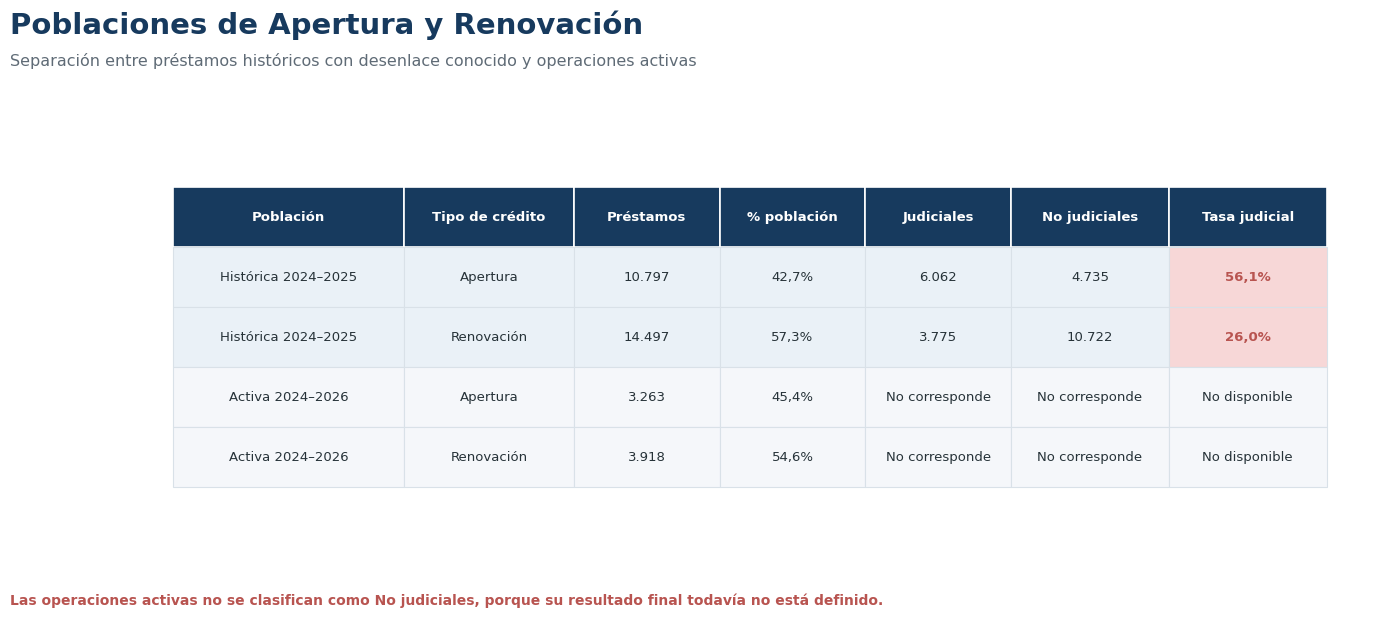

In [ ]:
# ============================================================
# 17. POBLACIONES DE APERTURA Y RENOVACIÓN
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


# ------------------------------------------------------------
# 1. NORMALIZAR EL TIPO DE CRÉDITO
# ------------------------------------------------------------

base_poblaciones = df_2024_2026.copy()

base_poblaciones["tipo_credito_limpio"] = (
    base_poblaciones["tipocredito"]
    .astype(str)
    .str.upper()
    .str.strip()
    .str.replace(
        "RENOVACIÓN",
        "RENOVACION",
        regex=False
    )
)

base_poblaciones = base_poblaciones[
    base_poblaciones[
        "tipo_credito_limpio"
    ].isin([
        "APERTURA",
        "RENOVACION"
    ])
].copy()


# ------------------------------------------------------------
# 2. POBLACIÓN HISTÓRICA
# ------------------------------------------------------------

# Préstamos 2024-2025 con desenlace conocido

poblacion_historica = base_poblaciones[
    base_poblaciones["añofac"].between(2024, 2025)
    & base_poblaciones["target"].isin([2, 3, 4, 5])
].copy()

poblacion_historica["judicial_bin"] = np.where(
    poblacion_historica["target"].isin([2, 5]),
    1,
    0
).astype(int)


# ------------------------------------------------------------
# 3. POBLACIÓN ACTIVA
# ------------------------------------------------------------

# Operaciones 2024-2026 todavía activas al corte

poblacion_activa = base_poblaciones[
    base_poblaciones["target"].eq(1)
].copy()


# ------------------------------------------------------------
# 4. RESUMEN DE LA POBLACIÓN HISTÓRICA
# ------------------------------------------------------------

resumen_historico = (
    poblacion_historica
    .groupby(
        "tipo_credito_limpio"
    )
    .agg(
        Prestamos=(
            "judicial_bin",
            "size"
        ),
        Judiciales=(
            "judicial_bin",
            "sum"
        )
    )
    .reset_index()
)

resumen_historico["No judiciales"] = (
    resumen_historico["Prestamos"]
    - resumen_historico["Judiciales"]
)

resumen_historico["Tasa judicial"] = (
    resumen_historico["Judiciales"]
    / resumen_historico["Prestamos"]
    * 100
)

resumen_historico["Población"] = (
    "Histórica 2024–2025"
)

resumen_historico["Uso"] = (
    "Desenlace conocido"
)


# ------------------------------------------------------------
# 5. RESUMEN DE LA POBLACIÓN ACTIVA
# ------------------------------------------------------------

resumen_activos = (
    poblacion_activa
    .groupby(
        "tipo_credito_limpio"
    )
    .size()
    .reset_index(
        name="Prestamos"
    )
)

resumen_activos["Judiciales"] = np.nan
resumen_activos["No judiciales"] = np.nan
resumen_activos["Tasa judicial"] = np.nan

resumen_activos["Población"] = (
    "Activa 2024–2026"
)

resumen_activos["Uso"] = (
    "Resultado todavía no conocido"
)


# ------------------------------------------------------------
# 6. UNIR LAS POBLACIONES
# ------------------------------------------------------------

tabla_poblaciones = pd.concat(
    [
        resumen_historico,
        resumen_activos
    ],
    ignore_index=True
)

tabla_poblaciones["Tipo de crédito"] = (
    tabla_poblaciones[
        "tipo_credito_limpio"
    ]
    .replace({
        "APERTURA": "Apertura",
        "RENOVACION": "Renovación"
    })
)

orden_poblacion = {
    "Histórica 2024–2025": 1,
    "Activa 2024–2026": 2
}

orden_tipo = {
    "Apertura": 1,
    "Renovación": 2
}

tabla_poblaciones["orden_poblacion"] = (
    tabla_poblaciones["Población"]
    .map(orden_poblacion)
)

tabla_poblaciones["orden_tipo"] = (
    tabla_poblaciones["Tipo de crédito"]
    .map(orden_tipo)
)

tabla_poblaciones = (
    tabla_poblaciones
    .sort_values(
        [
            "orden_poblacion",
            "orden_tipo"
        ]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 7. PARTICIPACIÓN DENTRO DE CADA POBLACIÓN
# ------------------------------------------------------------

tabla_poblaciones[
    "% de la población"
] = (
    tabla_poblaciones["Prestamos"]
    / tabla_poblaciones.groupby(
        "Población"
    )["Prestamos"].transform("sum")
    * 100
)


# ------------------------------------------------------------
# 8. TABLA NUMÉRICA
# ------------------------------------------------------------

tabla_poblaciones_numerica = (
    tabla_poblaciones[
        [
            "Población",
            "Tipo de crédito",
            "Uso",
            "Prestamos",
            "% de la población",
            "Judiciales",
            "No judiciales",
            "Tasa judicial"
        ]
    ]
    .copy()
)


# ------------------------------------------------------------
# 9. TABLA FORMATEADA
# ------------------------------------------------------------

tabla_poblaciones_mostrar = (
    tabla_poblaciones_numerica.copy()
)

tabla_poblaciones_mostrar["Prestamos"] = (
    tabla_poblaciones_mostrar["Prestamos"]
    .map(
        lambda valor:
        f"{valor:,.0f}".replace(",", ".")
    )
)

tabla_poblaciones_mostrar[
    "% de la población"
] = (
    tabla_poblaciones_mostrar[
        "% de la población"
    ]
    .map(
        lambda valor:
        f"{valor:.1f}%".replace(".", ",")
    )
)

for columna in [
    "Judiciales",
    "No judiciales"
]:

    tabla_poblaciones_mostrar[columna] = (
        tabla_poblaciones_mostrar[columna]
        .map(
            lambda valor:
            (
                f"{valor:,.0f}".replace(",", ".")
                if pd.notna(valor)
                else "No corresponde"
            )
        )
    )

tabla_poblaciones_mostrar[
    "Tasa judicial"
] = (
    tabla_poblaciones_mostrar[
        "Tasa judicial"
    ]
    .map(
        lambda valor:
        (
            f"{valor:.1f}%".replace(".", ",")
            if pd.notna(valor)
            else "No disponible"
        )
    )
)


# ------------------------------------------------------------
# 10. MOSTRAR RESULTADOS
# ------------------------------------------------------------

print("=" * 80)
print("POBLACIONES DE APERTURA Y RENOVACIÓN")
print("=" * 80)

print(
    "Préstamos históricos 2024-2025:",
    f"{len(poblacion_historica):,.0f}"
    .replace(",", ".")
)

print(
    "Préstamos activos 2024-2026:",
    f"{len(poblacion_activa):,.0f}"
    .replace(",", ".")
)

display(
    tabla_poblaciones_mostrar
)


# ------------------------------------------------------------
# 11. TABLA GRÁFICA PROFESIONAL
# ------------------------------------------------------------

columnas_grafico = [
    "Población",
    "Tipo de crédito",
    "Préstamos",
    "% población",
    "Judiciales",
    "No judiciales",
    "Tasa judicial"
]

datos_grafico = tabla_poblaciones_mostrar.rename(
    columns={
        "Prestamos": "Préstamos",
        "% de la población": "% población"
    }
)

datos_grafico = datos_grafico[
    columnas_grafico
]

cantidad_filas = len(
    datos_grafico
)

fig, ax = plt.subplots(
    figsize=(16, 6.5),
    facecolor="white"
)

ax.axis("off")

fig.text(
    0.05,
    0.94,
    "Poblaciones de Apertura y Renovación",
    fontsize=21,
    fontweight="bold",
    color="#173A5E",
    ha="left"
)

fig.text(
    0.05,
    0.89,
    (
        "Separación entre préstamos históricos "
        "con desenlace conocido y operaciones activas"
    ),
    fontsize=11.5,
    color="#5F6B76",
    ha="left"
)

tabla_visual = ax.table(
    cellText=datos_grafico.values,
    colLabels=datos_grafico.columns,
    cellLoc="center",
    colLoc="center",
    colWidths=[
        0.19,
        0.14,
        0.12,
        0.12,
        0.12,
        0.13,
        0.13
    ],
    bbox=[
        0.035,
        0.17,
        0.93,
        0.60
    ]
)

tabla_visual.auto_set_font_size(False)
tabla_visual.set_fontsize(9.5)


# ------------------------------------------------------------
# 12. FORMATO DEL ENCABEZADO
# ------------------------------------------------------------

for columna in range(
    len(columnas_grafico)
):

    celda = tabla_visual[
        0,
        columna
    ]

    celda.set_facecolor("#173A5E")
    celda.set_edgecolor("white")
    celda.set_linewidth(1.2)

    celda.get_text().set_color("white")
    celda.get_text().set_fontweight("bold")
    celda.get_text().set_fontsize(9.5)


# ------------------------------------------------------------
# 13. FORMATO DE FILAS
# ------------------------------------------------------------

for fila in range(
    1,
    cantidad_filas + 1
):

    poblacion = datos_grafico.iloc[
        fila - 1
    ]["Población"]

    if poblacion == "Histórica 2024–2025":
        color_fila = "#EAF1F7"

    else:
        color_fila = "#F5F7FA"

    for columna in range(
        len(columnas_grafico)
    ):

        celda = tabla_visual[
            fila,
            columna
        ]

        celda.set_facecolor(
            color_fila
        )

        celda.set_edgecolor(
            "#D9E1E8"
        )

        celda.set_linewidth(
            0.8
        )

        celda.get_text().set_color(
            "#263238"
        )

    # Destacar tasa judicial histórica
    if poblacion == "Histórica 2024–2025":

        celda_tasa = tabla_visual[
            fila,
            6
        ]

        celda_tasa.set_facecolor(
            "#F7D7D7"
        )

        celda_tasa.get_text().set_color(
            "#B85450"
        )

        celda_tasa.get_text().set_fontweight(
            "bold"
        )


# ------------------------------------------------------------
# 14. NOTA FINAL
# ------------------------------------------------------------

fig.text(
    0.05,
    0.06,
    (
        "Las operaciones activas no se clasifican como No judiciales, "
        "porque su resultado final todavía no está definido."
    ),
    fontsize=10,
    color="#B85450",
    fontweight="bold",
    ha="left"
)

plt.show()

### Lectura de las poblaciones

La población histórica de 2024–2025 permite comparar Apertura y Renovación utilizando préstamos con desenlace conocido. Las diferencias en cantidad de operaciones y tasa de judicialización muestran que ambas poblaciones presentan composiciones distintas y justifican su análisis separado.

Las operaciones activas de 2024–2026 se mantienen fuera de la construcción del resultado porque todavía pueden continuar normalmente, cancelarse o derivarse posteriormente a Gestión Judicial. Por lo tanto, no corresponde clasificarlas anticipadamente como No judiciales.

Esta separación conserva la diferencia entre la información utilizada para estudiar resultados históricos y la cartera sobre la cual podrá aplicarse posteriormente la estimación de riesgo.

# 18. Cierre del análisis exploratorio

El análisis exploratorio permitió comprender la estructura, cobertura y calidad de la base V2 utilizada para estudiar el riesgo de derivación a Gestión Judicial.

La base completa contiene 48.668 préstamos correspondientes al período 2023–2026. Debido a la disponibilidad más consistente de sueldo, los análisis que requieren esta variable se concentraron en la ventana 2024–2026. Para estudiar la judicialización se utilizaron préstamos de 2024–2025 con desenlace conocido.

El resultado se definió de la siguiente manera:

- Targets 2 y 5: Judicial.
- Targets 3 y 4: No judicial.
- Target 1: Activo, excluido de la población con desenlace conocido.

La base V2 no contiene refinanciaciones, por lo que la clasificación se concentra exclusivamente en préstamos de Apertura y Renovación.

Los análisis muestran que Apertura y Renovación presentan composiciones diferentes. Ambas comparten las variables disponibles al otorgamiento, mientras que Renovación permite incorporar antecedentes internos de créditos anteriores. Esta diferencia justifica conservar ambas poblaciones separadas en las etapas posteriores.

El score presenta la relación esperada con el resultado: los rangos más bajos registran una mayor judicialización. Sin embargo, la relación no es determinante, ya que existen préstamos judiciales y no judiciales en distintos niveles de score. Esto confirma que el score aporta información, pero no resulta suficiente como único indicador de riesgo.

El sueldo aislado presenta una asociación lineal reducida con la judicialización. La relación cuota-ingreso ofrece una lectura más completa, debido a que representa el esfuerzo de pago asumido por el cliente en función de su ingreso.

También se observaron diferencias en la judicialización según tipo de crédito, actividad, provincia, edad, género, plan de cuotas y sucursal. Estas diferencias deben interpretarse junto con la cantidad de préstamos de cada categoría, evitando conclusiones basadas únicamente en tasas elevadas de segmentos pequeños.

La matriz de correlaciones mostró que ninguna variable individual determina la judicialización. Al mismo tiempo, se detectaron relaciones elevadas entre algunas condiciones financieras, especialmente capital, interés, total facturado y monto de cuota, lo que indica posible información redundante que deberá controlarse posteriormente.

Finalmente, quedaron identificadas las variables disponibles al evaluar el crédito. Para Apertura se dispone de información del cliente y de las condiciones de la operación. Para Renovación pueden agregarse antecedentes de mora y judicialización correspondientes a créditos anteriores.

En conjunto, el EDA respalda la construcción de un modelo multivariable que complemente el score crediticio mediante información económica, características del préstamo y antecedentes internos del cliente.